# tACS coupling analysis

**How to use this notebook**

1. Run the **Setup** section (imports, colours, constants, `data.csv`) once after every kernel restart. Be sure to manually configure the `node_sets_path` variable as appropriate for your machine.
2. Jump to any section and run it from its first cell. No section depends on another one.

**Phase histograms and tests are per cell**

* Every rose histogram shows **one preferred phase per active cell**: the angle of the mean spike-phase vector of that cell in the analysis window (`utils.cell_phases`). Cells with no spikes in the window (fewer than `MIN_SPIKES_PER_CELL`) are not counted, so bar heights are numbers of cells.
* Phase convention, used by every phase in the project: `2*pi*f*(t - delay) + stim_phase + stim_orientation` (baselines use `t - 1000 ms` with zero phase and orientation). `stim_orientation` is the angle between the field vector and the cortical axis, so phase 0 is the peak of the field component driving the column, which is also the waveform drawn under the raster plots.
* Each stimulated phase distribution is compared with its frequency-matched baseline using **Moore's paired test** on cells active in both conditions. Other two-sample comparisons also retain the per-cell **Kuiper** result as a descriptive independent-sample comparison (`utils.compare_cell_phases`).

**Conventions (to avoid variable leakage)**

* Each section's first cell builds one object named after the section (`fig3`, `fig4`, ...) that holds all the data the section needs. Heavy data computed later in the section is stored on that same object (e.g. `fig3.firing_rates`).
* Plot cells only read the Setup constants and their own section object. Any `fig`, `ax` or loop variables they create are temporary and are never read by another cell.
* All plotting and analysis functions are generic and live in `src/plotting.py` and `src/utils.py`; the figure-specific choices (rows, baselines, colours, limits, file names) are made here.
* Simulations are loaded once and cached (`utils.load_simulation`), so re-running a section is fast.

## Statistical methods for phase preferences

**Unit of analysis: one preferred phase per active cell.** For every cell, each spike in the analysis window (`delay` < t < `tstop`; baselines use 1000 ms < t < `tstop`) gets the phase `θ = -2π f (t - delay) - stim_phase` of the stimulation (for baselines: of a virtual stimulus at the same frequency, with zero phase). The cell's **preferred phase** is the angle of its mean spike vector `mean(exp(iθ))`, and its **PLV** is the length of that vector. Cells without spikes in the window are not included, so the rose histograms count cells; several seeds of one condition are pooled per cell before averaging.

**Two-sample Kuiper test per cell (distribution difference).** Do two sets of preferred phases have the same circular distribution? Same statistic, computed between the two empirical CDFs; sensitive to any difference (location, spread, multimodality). It assumes **independent** samples. Here the same cells usually appear in both conditions, which violates that assumption, so read it as a descriptive distribution comparison.

**Moore's paired test (dependent samples).** Did the same cells change their preferred phase systematically? For every cell active in both conditions (`n_pairs`), take the change vector between its two unit phase vectors, rank the vector lengths and keep their directions: `R' = |Σ rank_i · u_i| / n^{3/2}`. If stimulation does not change the phase preference, change directions are symmetric and `R'` is small. `moore_p` comes from a randomization test that swaps the two conditions within random cells (`MOORE_PERMUTATIONS` swaps; the smallest reachable p is `1/(MOORE_PERMUTATIONS+1)`); `moore_p_asymptotic` uses `12 n³ R'² / (n(n+1)(2n+1)) ~ χ²(2)`. `moore_mean_shift_deg` is the mean within-cell phase change (B minus A). Moore's test detects changes of the population mean phase vector (a shift or a gain/loss of locking); a common rotation of an initially uniform population is not detected.

**Table format and baseline rows.** Every two-sample table has the same columns: `cell_type`, `freq_a`, `freq_b`, `amp_a`, `amp_b`, `connectivity_a`, `connectivity_b`, `correlation_a`, `correlation_b` (`COMPARISON_METADATA_COLUMNS`), followed by the Kuiper and Moore results. Every stimulated distribution that was previously tested for uniformity now has a paired baseline-vs-simulation row (a baseline row has `amp_a = 0`; `freq_a` is the reference frequency at which the baseline phases were computed). The baseline is always sample A, so the shift is the effect of stimulation. Caveats: there is no unstimulated O1 (hex_O1) run, so hex0 vs O1 has only a hex0 baseline row; the disconnected (replay) network has no unstimulated run, so replay is compared with the connected baseline of the same state (`connectivity_a = True`, `connectivity_b = False`).

**Test families.** Each family supports one conclusion and controls its own familywise error rate at `ALPHA` (code in the *Statistical testing* section at the end). The Moore families 1–3 are run separately for all cells (`PRIMARY_CELL_TYPE`: the population response, primary) and for inhibitory interneurons in isolation (secondary: at which stimulation paradigms the interneurons become entrained).

1. *Baseline vs stimulated* (Figures S2, S3): one chain per network state × frequency.
2. *Low vs high correlation* (Figure S3): one chain per frequency (7, 10 Hz). A step is tested only where family 1 found a stimulation effect at that frequency and amplitude, in `STATE_GATE` (`"any"` or `"all"`) of the two network states.
3. *Connected vs disconnected* (Figure 5, 10 Hz, 2 V/m): one test per network state, `CORRECTION_METHOD` over the two.
4. *Pyramidal vs inhibitory interneurons* (Figures S2, S3): one chain per network state × frequency. A step is tested only where all cells show a stimulation effect (family 1).

**Fixed-sequence (step-down) testing over amplitude** (families 1, 2 and 4). The order is fixed in advance: within a chain the highest amplitude is tested first, the next lower one only if the previous test was significant, and the chain stops at the first non-significant test. Within a chain no α is split, because a test is reached only if every earlier hypothesis was rejected (a special case of the closed testing principle); across the k chains of a family α is split by Bonferroni, so every step is run at `ALPHA / k`. The adjusted p is `min(1, k · max(p of this and all earlier steps))`; steps that were not reached are reported as "not tested". The lowest significant amplitude of a family-1 chain is its **minimum effective amplitude**. A gate (families 2 and 4) can only remove tests from the ungated procedure, so the familywise error rate stays controlled. The order assumes the effect does not decrease with amplitude: an effect present only at low amplitudes is not detected.

**Pyramidal vs inhibitory interneurons.** The two groups are different cells, so Moore's paired test cannot compare them with each other. Within each group, every cell active in both its baseline and its stimulated condition contributes its change vector `exp(iθ_stim) − exp(iθ_base)` (the vector Moore's test uses); the mean change vector of a group is how far stimulation moved that group's mean phase vector. The two mean change vectors are compared with a two-sample Wald test with unequal covariances, `(m_PYR − m_INH)ᵀ (S_PYR/n_PYR + S_INH/n_INH)⁻¹ (m_PYR − m_INH) ~ χ²(2)` (`utils.compare_phase_changes`); a difference in the size or in the direction of the shift both count. `R_base_*` and `R_stim_*` are each group's population phase concentration (mean resultant length of the preferred phases) at baseline and during stimulation, for the same cells.

**Reporting.** Kuiper results are descriptive and not corrected. Columns ending in `_paper` give the corrected p in reporting form (`< 0.05`, `< 0.005`, ..., `n.s.`, `not tested`); only corrected values should be compared with 0.05. Moore families use `MOORE_P_COLUMN`. The randomization `moore_p` cannot go below `1/(MOORE_PERMUTATIONS+1)`, so a step-down family with k chains cannot report an adjusted p below `k/(MOORE_PERMUTATIONS+1)` (2.5·10⁻⁴ for 5 chains and 19 999 swaps); `moore_p_asymptotic` (χ²(2)) has no such floor and matches the randomization p closely at these sample sizes.

**Scope.** Cells are matched units within one simulated network, and each condition was simulated once (or a few seeds). The p-values describe the cell population of this network; they do not estimate variability across network realisations. With thousands of cells, tiny effects become significant, so also look at `moore_mean_shift_deg`, the PLVs and the histograms.

# Setup

In [115]:
# %matplotlib tk
%load_ext autoreload
%autoreload 2

from pathlib import Path
from types import SimpleNamespace

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

from src.plotting import (
    annotate_significance,
    marker_sizes,
    multiple_psth_plot,
    plot_metric_vs_amplitude,
    plot_power_spectrum,
    plot_psd_overlay,
    plot_rose,
    plot_rose_grid,
    polar_scatter,
    psth_grid_plot,
    psth_plot,
)
from src.utils import (
    BASELINE_START_MS,
    average_metrics_by_amp,
    cell_phase_contrasts,
    cell_phase_grid,
    cell_phases,
    check_data_available,
    compare_cell_phases,
    compare_phase_changes,
    correct_pvalues,
    cross_frequency_moore_tests,
    firing_rate_amplitude_trend,
    fixed_sequence_pvalues,
    get_baseline,
    get_psd_data,
    load_simulation,
    load_simulation_table,
    merge_and_average,
    minimum_effective_levels,
    paper_p_value,
    population_firing_rates,
    psd_by_amplitude,
    rows_at,
    select_simulations,
    sim_row,
    synaptic_delay_tables,
    pooled_phases,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Colours

In [116]:
%matplotlib inline

In [117]:
matplotlib.rcParams.update({"font.size": 10})
pd.options.display.max_columns = None

peru, pink, darkgrey = "#FFBA8B", "#FFA3D7", "#686868"          # cell types, low-correlation state
lighterorange, lighterpink, midgrey = "#F07605", "#DA4597", "#333333"  # cell types, high-correlation state
darkbrown, grey = "#994F00", "slategrey"                        # O1 vs hex0
blue, red, purple = "#56B4E9", "#cf5656", "#9367bd"             # 7 / 10 / 15 Hz, low-correlation state
lightblue, magenta = "#0072B2", "#c50000"                    # 7 / 10 Hz, high-correlation state

FREQ_COLORS = {"low": {7: blue, 10: red, 15: purple}, "high": {7: lightblue, 10: magenta}}
CELL_COLORS = {
    "low": {"PYR": peru, "INT_INH": pink, "INT_EXC": darkgrey},
    "high": {"PYR": lighterorange, "INT_INH": lighterpink, "INT_EXC": midgrey},
}
CELL_LABELS = {"PYR": "Pyramidal", "INT_EXC": "Exc. Interneuron", "INT_INH": "Inh. Interneuron"}

### Constants and simulation table

In [118]:
FIG_DIR = Path("paper_figures_CORRECT")
FIG_DIR.mkdir(parents=True, exist_ok=True)

STATES = ("low", "high")  # low-correlation (externally driven) / high-correlation (internally driven)
STATE_LABELS = {"low": "Low-correlation", "high": "High-correlation"}
BASELINE_ID = {"low": "resting", "high": "baseline_highCorrelation_stopStart"}
SELECT = {  # sim_id regexes selecting the stimulated runs of each network state
    "low": dict(exclude=r"highCorrelation|replay|hex0|O1|obi|baseline|resting|delay|long"),
    "high": dict(include="highCorrelation", exclude=r"baseline|replay|delay"),
}
FREQS = {"low": (7, 10, 15), "high": (7, 10)}
AMPS = (0.25, 0.5, 1, 2, 4)
CELL_TYPES = ("PYR", "INT_EXC", "INT_INH")
AMP_LABELS = ["baseline"] + [f"{amp:g} V/m" for amp in AMPS]

simulations = load_simulation_table("data.csv")
check_data_available(simulations)
SETUP_DONE = True

# Cell-level phase analysis
MIN_SPIKES_PER_CELL = 1      # cells with fewer spikes in the analysis window are not counted
ROSE_NORMALIZE = False       # False: rose bars are numbers of cells; True: fractions of active cells
MOORE_PERMUTATIONS = 19999    # within-cell label swaps for Moore's paired test (0 = asymptotic p only)
CELL_TEST_KWARGS = dict(n_permutations=MOORE_PERMUTATIONS, seed=20260921)
# Test families (see Statistical methods and the Statistical testing section)
ALPHA = 0.05                         # familywise error rate of every test family
MOORE_P_COLUMN = "moore_p"           # randomization p; "moore_p_asymptotic" for the chi2(2) p
PRIMARY_CELL_TYPE = "ALL"            # population response (primary); INT_INH is tested as its own family
CELL_TYPE_PAIR = ("PYR", "INT_INH")  # groups compared by the pyramidal vs interneuron test
STATE_GATE = "any"                   # low vs high is tested where a baseline effect exists in "any" / "all" states
CORRECTION_METHOD = "holm"           # "bonferroni" or "holm": connected vs disconnected family
# Power spectra: samples per Welch segment. Every PSD uses this value, so all spectra share one
# frequency grid (5 ms bins, 200 samples -> 1 Hz, the resolution of the 1 s stimulation window).
PSD_NPERSEG = 200


def amp_colors(state, freq):
    """One shade of FREQ_COLORS[state][freq] per amplitude, light (lowest) to full colour (highest)."""
    base = np.array(matplotlib.colors.to_rgb(FREQ_COLORS[state][freq]))
    return {amp: tuple(1 - (1 - base) * t) for amp, t in zip(AMPS, np.linspace(0.3, 1, len(AMPS)))}


BASELINE_COLORS = {"low": "black", "high": "slategrey"}

ROSE_GRID_KWARGS = dict(normalize=ROSE_NORMALIZE, shared_scale=False, show_n=False)

# Shared condition fields for every two-sample phase comparison.
COMPARISON_METADATA_COLUMNS = (
    "cell_type", "freq_a", "freq_b", "amp_a", "amp_b",
    "connectivity_a", "connectivity_b", "correlation_a", "correlation_b",
)

def comparison_metadata(*, cell_type, freq_a, freq_b, amp_a, amp_b,
                        connectivity_a, connectivity_b, correlation_a, correlation_b):
    return {
        "cell_type": cell_type,
        "freq_a": freq_a,
        "freq_b": freq_b,
        "amp_a": amp_a,
        "amp_b": amp_b,
        "connectivity_a": connectivity_a,
        "connectivity_b": connectivity_b,
        "correlation_a": correlation_a,
        "correlation_b": correlation_b,
    }


# Columns identifying one statistical test. The same test reported in several tables has the
# same conditions and, because it is computed from the same cells, the same statistics; it is
# counted once in the multiple-comparison correction.
TEST_KEY_COLUMNS = COMPARISON_METADATA_COLUMNS + ("n_cells_a", "n_cells_b", "kuiper_V")


def condition(freq, amp, correlation, connectivity=True):
    """Descriptor of one sample in a comparison table (amp=0 marks a baseline; freq is the
    phase-reference frequency). Gives the freq/amp/connectivity/correlation _a/_b columns."""
    return {"freq": freq, "amp": amp, "connectivity": connectivity, "correlation": correlation}


def cell_type_contrast(grids, freq_index, amp_index, freq, amp, correlation):
    """Pyramidal vs inhibitory interneurons (CELL_TYPE_PAIR) at one condition of a ``cell_phase_grid``
    dict: each cell's change from the frequency-matched baseline (column 0), compared between the two
    groups (``utils.compare_phase_changes``). Gives the same metadata columns as the other tables."""
    group_a, group_b = CELL_TYPE_PAIR
    return {
        "cell_type": f"{group_a} vs {group_b}",
        **{f"{key}_{sample}": value for key, value in condition(freq, amp, correlation).items() for sample in "ab"},
        **compare_phase_changes(grids[group_a][freq_index][0], grids[group_a][freq_index][amp_index],
                                grids[group_b][freq_index][0], grids[group_b][freq_index][amp_index]),
    }

All 55 simulations found.


### Path to node sets **MUST BE CONFIGURED MANUALLY FOR YOUR MACHINE**

In [119]:
node_sets_path = Path.home() / "Documents/bluebrainStuff/csd_paper/config/circuit_config.json"

In [120]:
simulations

,sim_id,time_import,dt,tstop,seed,simulator,node_set,delay,duration,stim_freq,stim_phase,stim_amp,stim_orientation,stim_rampup,stim_rampdown,analysis_start,analysis_stop,source_file,plv,ppc,deltafr,complex,amplitude_norm,power_norm,total_power,plv_PYR,ppc_PYR,deltafr_PYR,complex_PYR,amplitude_norm_PYR,power_norm_PYR,total_power_PYR,plv_INT_INH,ppc_INT_INH,deltafr_INT_INH,complex_INT_INH,amplitude_norm_INT_INH,power_norm_INT_INH,total_power_INT_INH,plv_INT_EXC,ppc_INT_EXC,deltafr_INT_EXC,complex_INT_EXC,amplitude_norm_INT_EXC,power_norm_INT_EXC,total_power_INT_EXC,deployment,neurodamus,abs_plv,abs_plv_PYR,abs_plv_INT_INH,abs_plv_INT_EXC
0,baseline,2026-05-18,0.025,2500,843,CORENEURON,hex0,0,0,0,0.000000,0.00,0.0000,0.0,0.0,1499.144897,2500.000000,data/sim0_CoreNeuron/sim_with_stim.json,1.000000+0.000000j,1.000000,NaN,39.205035+ 0.000000j,1.000000,0.994681,0.038248,1.000000+0.000000j,1.000000,NaN,33.443294+ 0.000000j,1.000000,0.993881,0.027854,1.000000+0.000000j,1.000000,NaN,87.275933+ 0.000000j,1.000000,0.983215,0.191756,1.000000+0.000000j,1.000000,NaN,11.111111+ 0.000000j,1.000000,0.591080,0.005170,Mimas,bluebrain/neurodamus,1.000000,1.000000,1.000000,1.000000
1,highCorrelation_baseline,2026-05-21,0.025,2500,843,CORENEURON,hex0,0,0,0,0.000000,0.00,0.0000,0.0,0.0,1499.841635,2500.000000,data/highCorrelation_convergence/sim_with_stim...,1.000000+0.000000j,1.000000,NaN,73.991388+ 0.000000j,1.000000,0.993965,0.136332,1.000000+0.000000j,1.000000,NaN,57.392030+ 0.000000j,1.000000,0.991377,0.082238,1.000000+0.000000j,1.000000,NaN,207.052601+ 0.000000j,1.000000,0.995025,1.066437,1.000000+0.000000j,1.000000,NaN,37.681159+ 0.000000j,1.000000,0.846024,0.041541,Mimas,bluebrain/neurodamus,1.000000,1.000000,1.000000,1.000000
2,baseline_highCorrelation_stopStart,2026-05-22,0.025,5000,843,CORENEURON,hex0,0,0,0,0.000000,0.00,0.0000,0.0,0.0,1384.055862,5000.000000,data/highCorrelation_convergence_stopStart/sim...,1.000000+0.000000j,1.000000,NaN,258.211328- 0.000000j,1.000000,0.988665,0.128654,1.000000+0.000000j,1.000000,NaN,199.218898- 0.000000j,1.000000,0.983282,0.077003,1.000000+0.000000j,1.000000,NaN,729.709080- 0.000000j,1.000000,0.993731,1.022241,1.000000+0.000000j,1.000000,NaN,140.579710- 0.000000j,1.000000,0.837130,0.045038,Mimas,bluebrain/neurodamus,1.000000,1.000000,1.000000,1.000000
3,baseline_highCorrelation_stopStart_short,2026-05-23,0.025,3000,843,CORENEURON,hex0,0,0,0,0.000000,0.00,0.0000,0.0,0.0,1201.285537,3000.000000,data/highCorrelation_convergence_stopStart_sho...,1.000000+0.000000j,1.000000,NaN,127.247433+ 0.000000j,1.000000,0.985713,0.126748,1.000000+0.000000j,1.000000,NaN,98.024495+ 0.000000j,1.000000,0.978839,0.075745,1.000000+0.000000j,1.000000,NaN,362.327358+ 0.000000j,1.000000,0.993287,1.019818,1.000000+0.000000j,1.000000,NaN,56.521739+ 0.000000j,1.000000,0.808130,0.030503,Mimas,bluebrain/neurodamus,1.000000,1.000000,1.000000,1.000000
4,resting_3000,2026-09-15,0.025,3000,843,CORENEURON,hex0,0,0,0,0.000000,0.00,0.0000,0.0,0.0,500.000000,3004.507464,data/resting_3000/sim_with_stim.json,1.000000+0.000000j,1.000000,NaN,106.141106+ 0.000000j,1.000000,0.992491,0.045224,1.000000+0.000000j,1.000000,NaN,91.912183+ 0.000000j,1.000000,0.990198,0.033990,1.000000+0.000000j,1.000000,NaN,223.273582+ 0.000000j,1.000000,0.986554,0.201316,1.000000+0.000000j,1.000000,NaN,49.758454+ 0.000000j,1.000000,0.716163,0.013774,mimas,4.2,1.000000,1.000000,1.000000,1.000000
5,resting,2026-09-16,0.025,5000,843,CORENEURON,hex0,0,0,0,0.000000,0.00,0.0000,0.0,0.0,500.000000,5000.000000,data/resting/sim_with_stim.json,1.000000+0.000000j,1.000000,NaN,194.554488+ 0.000000j,1.000000,0.993577,0.047032,1.000000+0.000000j,1.000000,NaN,169.210935+ 0.000000j,1.000000,0.991583,0.035649,1.000000+0.000000j,1.000000,NaN,403.467529+ 0.000000j,1.000000,0.988920,0.203222,1.000000+0.000000j,1.000000,NaN,91.787440+ 0.000000j,1.000000,0.733448,0.014181,mimas,weji,1.000000,1.000000,1.000000,1.000000
6,7Hz0.25Vm,2026-05-13,0.025,2500,843,NEURON,hex0,1500,1000,7,1.570796,0.

(700,)


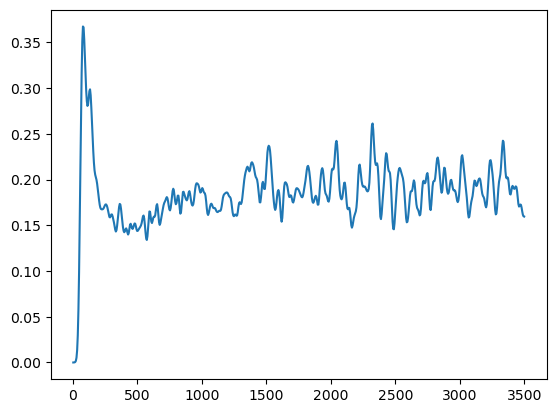

In [121]:
import matplotlib.pyplot as plt
#Spectrogram for firing rate of 10Hz 1Vm_longer_rerun
from scipy.ndimage import gaussian_filter1d
#load data from source_file -> get spikes.h5 -> calculate population firing rate -> plot spectrogram
long_sim = simulations[simulations["sim_id"] == "10Hz1Vm_longer_rerun"]["source_file"].values[0]
data  = load_simulation(long_sim)
data.spikes
#make a population firing rate from the spikes.h5 file
bin = 5 #5ms
bins = np.arange(0, 3500 + bin, bin)
hist_counts, _ = np.histogram(data.spikes.index.tolist(), bins=bins)
firing_rate = hist_counts / (bin * 1e-3) / data.cells.shape[0]
bins = bins[1:] - bin / 2
firing_rate = gaussian_filter1d(firing_rate, sigma=10 / 5)
plt.plot(bins, firing_rate)
print(firing_rate.shape)

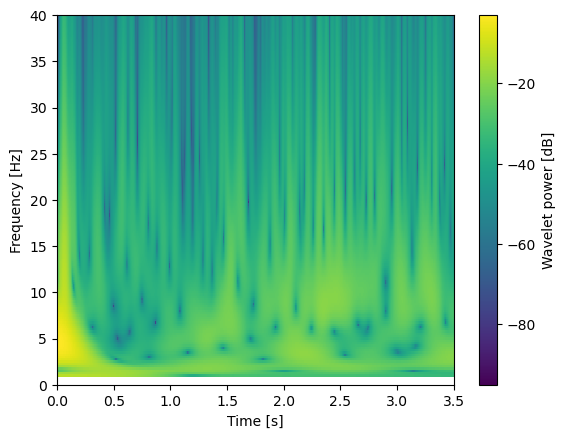

In [122]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from src.spectrograms import morlet_kernel

dt = 5e-3
fs = 1 / dt

rate = np.asarray(firing_rate, dtype=float).squeeze()

frequencies = np.arange(1, 40.01, 0.25)
periods = 3.0  # wavelet support contains at least 3 cycles

power = np.empty((len(frequencies), len(rate)))

for i, frequency in enumerate(frequencies):
    wavelet = morlet_kernel(
        frequency,
        bin_s=dt,
        window_periods=periods,
    )

    half = len(wavelet) // 2

    # Reflect the signal at both edges so every original time sample is retained
    padded_rate = np.pad(rate, (half, half), mode="reflect")

    coefficients = signal.fftconvolve(
        padded_rate,
        wavelet.conj()[::-1],
        mode="valid",
    )

    power[i, :] = np.abs(coefficients) ** 2

time = (np.arange(len(rate)) + 0.5) * dt

plt.pcolormesh(
    time,
    frequencies,
    10 * np.log10(power + np.finfo(float).tiny),
    shading="auto",
)

plt.xlim(0, len(rate) * dt)
plt.ylim(0, 40)
plt.xlabel("Time [s]")
plt.ylabel("Frequency [Hz]")
plt.colorbar(label="Wavelet power [dB]")
plt.show()

In [123]:
from matplotlib.gridspec import GridSpec
from src.spectrogram_comparisons import load_runs

# Use the same wavelet/rate implementation already used in analysis.ipynb
spectrogram_frequencies = np.arange(1, 20.001, 0.125)
spectrogram_periods = 3.0

spectrogram_runs, spectrogram_audit = load_runs(
    root=Path.cwd(),
    node_sets_path=node_sets_path,
    frequencies=spectrogram_frequencies,
    periods=spectrogram_periods,
)

def close_value(a, b):
    return np.isclose(float(a), float(b), rtol=0, atol=1e-6)


def choose_runs_for_frequency(runs, stimulation_frequency):
    """Return one low/high run per amplitude, paired by common seed."""
    candidates = [
        run for run in runs
        if run["standard"]
        and close_value(run["stimulus_hz"], stimulation_frequency)
    ]

    amplitudes = sorted({
        round(float(run["amplitude_vm"]), 6)
        for run in candidates
        if float(run["amplitude_vm"]) > 0
    })

    selected = []

    for amplitude in amplitudes:
        by_state = {}

        for state in ("low", "high"):
            state_runs = [
                run for run in candidates
                if run["state"] == state
                and close_value(run["amplitude_vm"], amplitude)
            ]

            # Keep one run per seed.
            by_seed = {}
            for run in state_runs:
                by_seed.setdefault(run["seed"], run)

            by_state[state] = by_seed

        low_seeds = set(by_state["low"])
        high_seeds = set(by_state["high"])
        common_seeds = sorted(low_seeds & high_seeds)

        if common_seeds:
            # Same seed is used for the low/high comparison.
            seed = common_seeds[0]
            selected.append(
                (amplitude, by_state["low"][seed], by_state["high"][seed])
            )
        elif low_seeds or high_seeds:
            # If only one correlation state exists, show the available state.
            low_run = by_state["low"][sorted(low_seeds)[0]] if low_seeds else None
            high_run = by_state["high"][sorted(high_seeds)[0]] if high_seeds else None
            selected.append((amplitude, low_run, high_run))

    return selected


def plot_frequency_comparison(runs, stimulation_frequency, output_dir):
    selected = choose_runs_for_frequency(runs, stimulation_frequency)

    if not selected:
        print(f"No standard simulations available for {stimulation_frequency:g} Hz")
        return None

    n_rows = len(selected)
    figure = plt.figure(
        figsize=(7.5, 3.0 * n_rows),
        constrained_layout=True,
    )

    grid = GridSpec(
        n_rows,
        2,
        figure=figure,
        width_ratios=(1, 1),
    )

    mesh = None

    for row, (amplitude, low_run, high_run) in enumerate(selected):
        available = [
            ("Low-correlation", low_run),
            ("High-correlation", high_run),
        ]

        for column, (state_label, run) in enumerate(available):
            if run is None:
                continue

            ax = figure.add_subplot(grid[row, column])

            # Existing Morlet wavelet power calculated from the firing-rate signal.
            mesh = ax.pcolormesh(
                run["time"],
                run["frequency"],
                run["power_db"],
                shading="auto",
                cmap="magma",
                rasterized=True,
            )

            for stimulus in run["stimuli"]:
                ax.axvline(
                    stimulus["start"],
                    color="white",
                    linestyle="--",
                    linewidth=0.8,
                )
                ax.axvline(
                    stimulus["end"],
                    color="white",
                    linestyle="--",
                    linewidth=0.8,
                )

            ax.set(
                title=(
                    f"{state_label}\n"
                    f"{amplitude:g} V/m, seed {run['seed']}"
                ),
                xlabel="Simulation time (s)",
                ylabel="Frequency (Hz)",
                ylim=(1, 20),
            )

        # Add the amplitude label at the left of each row.
        figure.text(
            0.01,
            1 - (row + 0.5) / n_rows,
            f"{amplitude:g} V/m",
            rotation=90,
            va="center",
            ha="center",
        )

    if mesh is not None:
        figure.colorbar(
            mesh,
            ax=figure.axes,
            label="Morlet wavelet power [dB]",
            shrink=0.85,
        )

    figure.suptitle(
        f"Population firing-rate Morlet spectrograms: {stimulation_frequency:g} Hz",
        fontsize=14,
    )

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    output_path = output_dir / (
        f"morlet_spectrogram_comparison_{stimulation_frequency:g}Hz.svg"
    )
    figure.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved {output_path}")

    return figure


spectrogram_output_dir = FIG_DIR / "morlet_frequency_comparisons"

figures = {
    frequency: plot_frequency_comparison(
        spectrogram_runs,
        frequency,
        spectrogram_output_dir,
    )
    for frequency in (7, 10, 15)
}

ValueError: No eligible recordings loaded: [{'name': 'O1_10Hz_0.25Vm', 'status': 'excluded', 'reason': 'hex0/O1 comparison run'}, {'name': 'O1_10Hz_1Vm_seed1', 'status': 'excluded', 'reason': 'hex0/O1 comparison run'}, {'name': 'O1_10Hz_1Vm_seed2', 'status': 'excluded', 'reason': 'hex0/O1 comparison run'}, {'name': 'O1_10Hz_1Vm_seed3', 'status': 'excluded', 'reason': 'hex0/O1 comparison run'}, {'name': 'O1_10Hz_4Vm', 'status': 'excluded', 'reason': 'hex0/O1 comparison run'}, {'name': 'hex0_10Hz_0.25Vm', 'status': 'excluded', 'reason': 'hex0/O1 comparison run'}, {'name': 'hex0_10Hz_0.25Vm_seed2', 'status': 'excluded', 'reason': 'hex0/O1 comparison run'}, {'name': 'hex0_10Hz_1Vm', 'status': 'excluded', 'reason': 'hex0/O1 comparison run'}, {'name': 'hex0_10Hz_4Vm', 'status': 'excluded', 'reason': 'hex0/O1 comparison run'}, {'name': 'highCorrelation_convergence', 'status': 'skipped', 'reason': "'hex0'"}, {'name': 'highCorrelation_convergence_stopStart', 'status': 'skipped', 'reason': "'hex

# Figure 1a: intro raster

In [ ]:
assert "SETUP_DONE" in globals(), "Run the Setup section at the top of the notebook first."
intro = SimpleNamespace(sim=load_simulation(sim_row(simulations, "7Hz1Vm_seed2")["source_file"].iloc[0]))

# Figure 2: single column (hex0) reproduces behaviour of the larger network (O1)

In [ ]:
assert "SETUP_DONE" in globals(), "Run the Setup section at the top of the notebook first."
fig2 = SimpleNamespace(
    rows={circuit: select_simulations(simulations, include=f"^{circuit}", freqs=(10,)) for circuit in ("O1", "hex0")},
    colors={"O1": darkbrown, "hex0": grey},
    amps=(0.25, 1, 4),
)
fig2.phases = {amp: {c: pooled_phases(rows_at(rows, amp=amp)) for c, rows in fig2.rows.items()} for amp in fig2.amps}

### Population firing rate at 4 V/m, O1 vs hex0

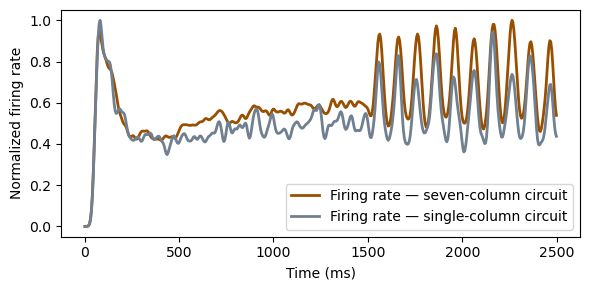

In [ ]:
fig2.psth = {c: load_simulation(rows_at(rows, amp=4)["source_file"].iloc[0]) for c, rows in fig2.rows.items()}
multiple_psth_plot(
    [sim.spikes for sim in fig2.psth.values()], "", [sim.cell_to_rank for sim in fig2.psth.values()],
    [sim.simulation for sim in fig2.psth.values()], ['\u2014 seven-column circuit','\u2014 single-column circuit'], bin_width=5, figsize=(6, 3),
    colorList=[fig2.colors[c] for c in fig2.psth], normalized=True,
    save_histogram=FIG_DIR / "psth_O1_vs_hex0_10Hz_4Vm_5bin.svg",
);

### PPC and PLV vs amplitude (seed-averaged)

In [ ]:
fig2.metrics = {c: pd.DataFrame(average_metrics_by_amp(rows["source_file"], stim_amps=fig2.amps))
                for c, rows in fig2.rows.items()}
for metric in ("ppc", "plv"):
    fig, ax = plt.subplots(figsize=(4, 4))
    for circuit in ("hex0", "O1"):
        ax.plot(fig2.metrics[circuit]["stim_amp"], fig2.metrics[circuit][metric], "o", c=fig2.colors[circuit], label=circuit)
    ax.set(xlabel="Stimulus\namplitude (V/m)", ylabel=metric.upper())
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"O1_vs_hex0_{metric}.svg", dpi=600)

TypeError: Pass simulation-table rows, not source_file paths.

### Figure 2c-e: phase preferences, hex0 vs O1

angle=0.297 (17.0°)
plv=0.020
angle=0.314 (18.0°)
plv=0.011
angle=0.467 (26.8°)
plv=0.044
angle=0.734 (42.1°)
plv=0.050
angle=0.612 (35.1°)
plv=0.193
angle=0.767 (43.9°)
plv=0.192


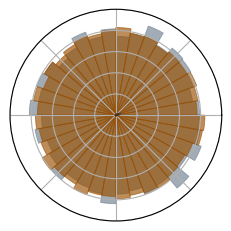

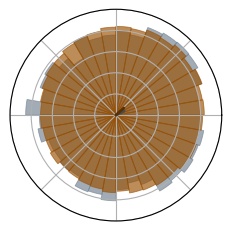

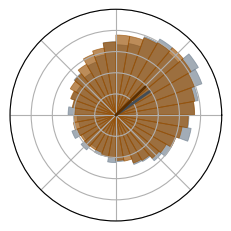

In [ ]:
for amp, phases in fig2.phases.items():
    ax = plot_rose([phases["hex0"], phases["O1"]], legend=False, color=[fig2.colors["hex0"], fig2.colors["O1"]])
    ax.get_figure().savefig(FIG_DIR / (f"O1vHex0_{amp:g}".replace(".", "") + ".svg"), dpi=300, bbox_inches="tight")

Kuiper tests on the cell preferred phases shown in the rose histograms

In [ ]:
fig2.circuit_tests = pd.DataFrame([
    row
    for amp, phases in fig2.phases.items()
    if len(phases["hex0"]) > 1 and len(phases["O1"]) > 1
    for row in cell_phase_contrasts(
        (condition(10, amp, "low"), phases["hex0"]),
        (condition(10, amp, "low"), phases["O1"]),
        labels={"cell_type": "ALL"}, **CELL_TEST_KWARGS,
    )
])
display(fig2.circuit_tests)
fig2.circuit_tests.to_csv(FIG_DIR / "fig2_hex0_vs_O1_phase_tests.csv", index=False)

,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_cells_a,n_cells_b,kuiper_V,kuiper_p,moore_n_pairs,moore_n_moore,moore_R,moore_p_asymptotic,moore_mean_shift_deg,moore_p,moore_method
0,ALL,10,10,0.25,0.25,True,True,low,low,11518,48978,0.012648,0.500246,1077,1077,0.408156,0.607090,60.861443,0.60670,randomization (19999 within-cell label swaps)
1,ALL,10,10,1.00,1.00,True,True,low,low,5814,147008,0.020353,0.158353,1596,1596,1.165045,0.017109,64.458724,0.01615,randomization (19999 within-cell label swaps)
2,ALL,10,10,4.00,4.00,True,True,low,low,6334,54696,0.026939,0.007935,601,601,1.400922,0.002814,-16.165143,0.00315,randomization (19999 within-cell label swaps)


# Figure S1: baseline activity and power spectra

In [ ]:
assert "SETUP_DONE" in globals(), "Run the Setup section at the top of the notebook first."
figS1 = SimpleNamespace(
    rows={state: sim_row(simulations, BASELINE_ID[state]) for state in STATES},
    window_ms=(1000, 5000),
    nperseg=PSD_NPERSEG,
)
# Welch PSD of the smoothed population rate, one per network state, on a common frequency grid.
figS1.spectra = {state: get_psd_data(row, start=figS1.window_ms[0], time_stop=figS1.window_ms[1],
                                     nperseg=512)
                 for state, row in figS1.rows.items()}

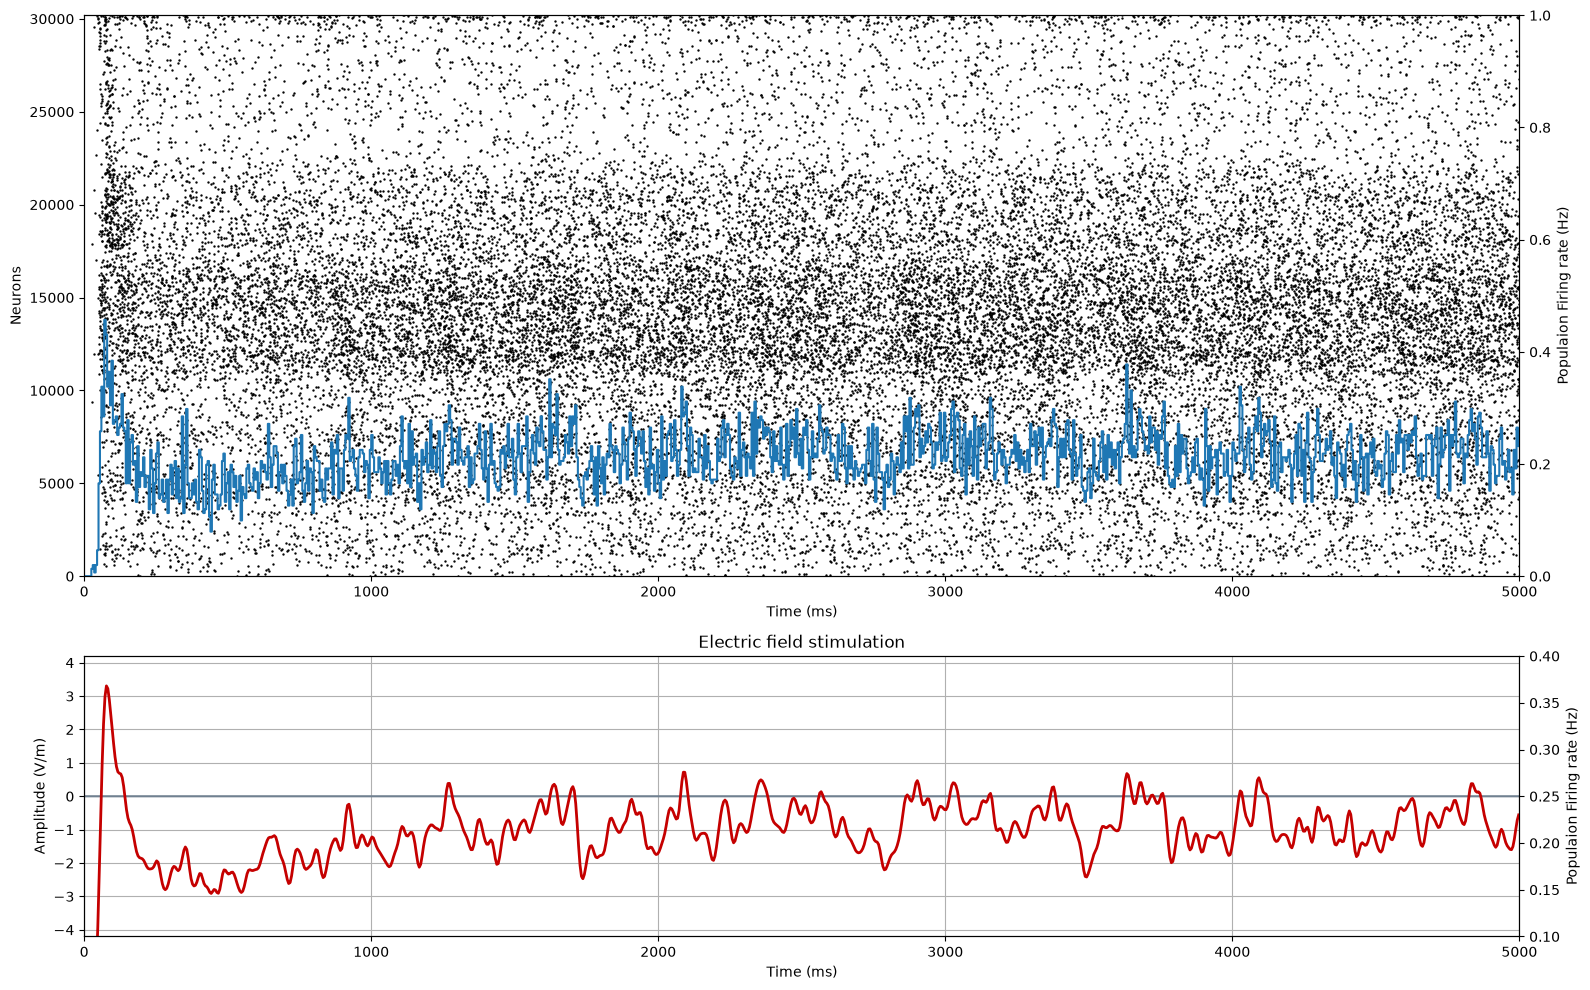

In [ ]:
figS1.sim = load_simulation(figS1.rows["low"]["source_file"].iloc[0])
psth_plot(figS1.sim.spikes, "resting - coreNeuron 5000", figS1.sim.cell_to_rank, figS1.sim.simulation,
          bin_width=5, smoothed=True, save_histogram=FIG_DIR / "baseline_2500.svg");

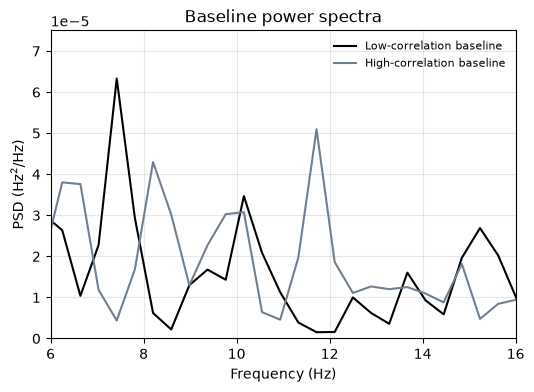

In [ ]:
# Both baselines overlaid.
plot_psd_overlay(
    [figS1.spectra[state] for state in STATES],
    labels=[f"{STATE_LABELS[state]} baseline" for state in STATES],
    colors=[BASELINE_COLORS[state] for state in STATES],
    log_scale=False, title="Baseline power spectra",
    xlim=(6,16),ylim=(0,7.5e-5)).savefig(FIG_DIR / "power_spectrum_baselines.svg", dpi=300, bbox_inches="tight")

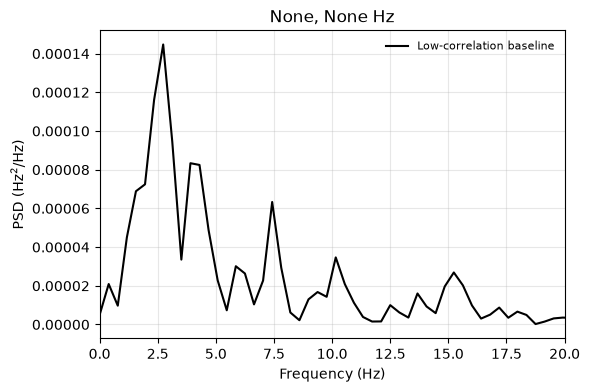

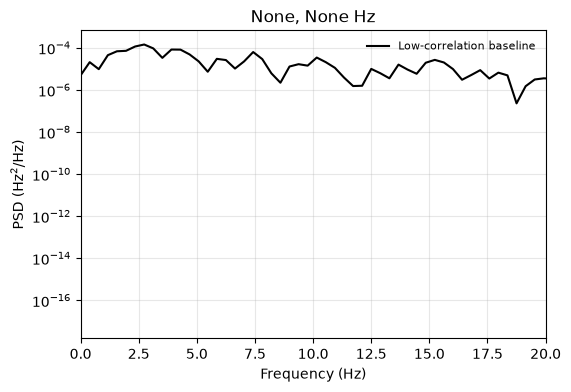

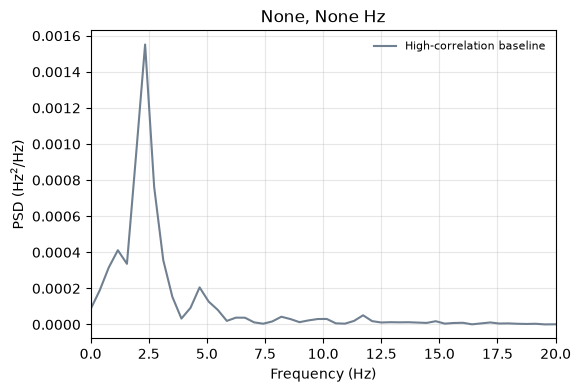

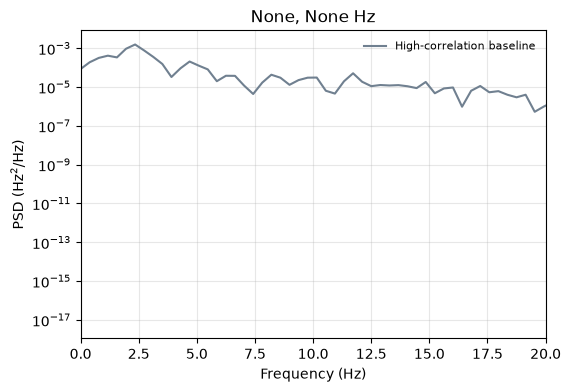

In [ ]:
# One figure per baseline, linear and logarithmic.
for state, spectrum in figS1.spectra.items():
    for log_scale, suffix in ((False, ""), (True, "_log")):
        plot_psd_overlay([spectrum], labels=[f"{STATE_LABELS[state]} baseline"],
                         colors=[BASELINE_COLORS[state]], log_scale=log_scale,
                         ).savefig(FIG_DIR / f"power_spectrum_{BASELINE_ID[state]}{suffix}.svg", dpi=300,
                                   bbox_inches="tight")

# All simulations: population PSTHs

One compact panel for every simulation in `data.csv`, ordered by stimulation frequency, amplitude and simulation ID. Panels show the raw population histogram, its Gaussian-smoothed trace and the applied stimulation waveform. The firing-rate and stimulation scales are shared across panels so simulations can be compared directly.

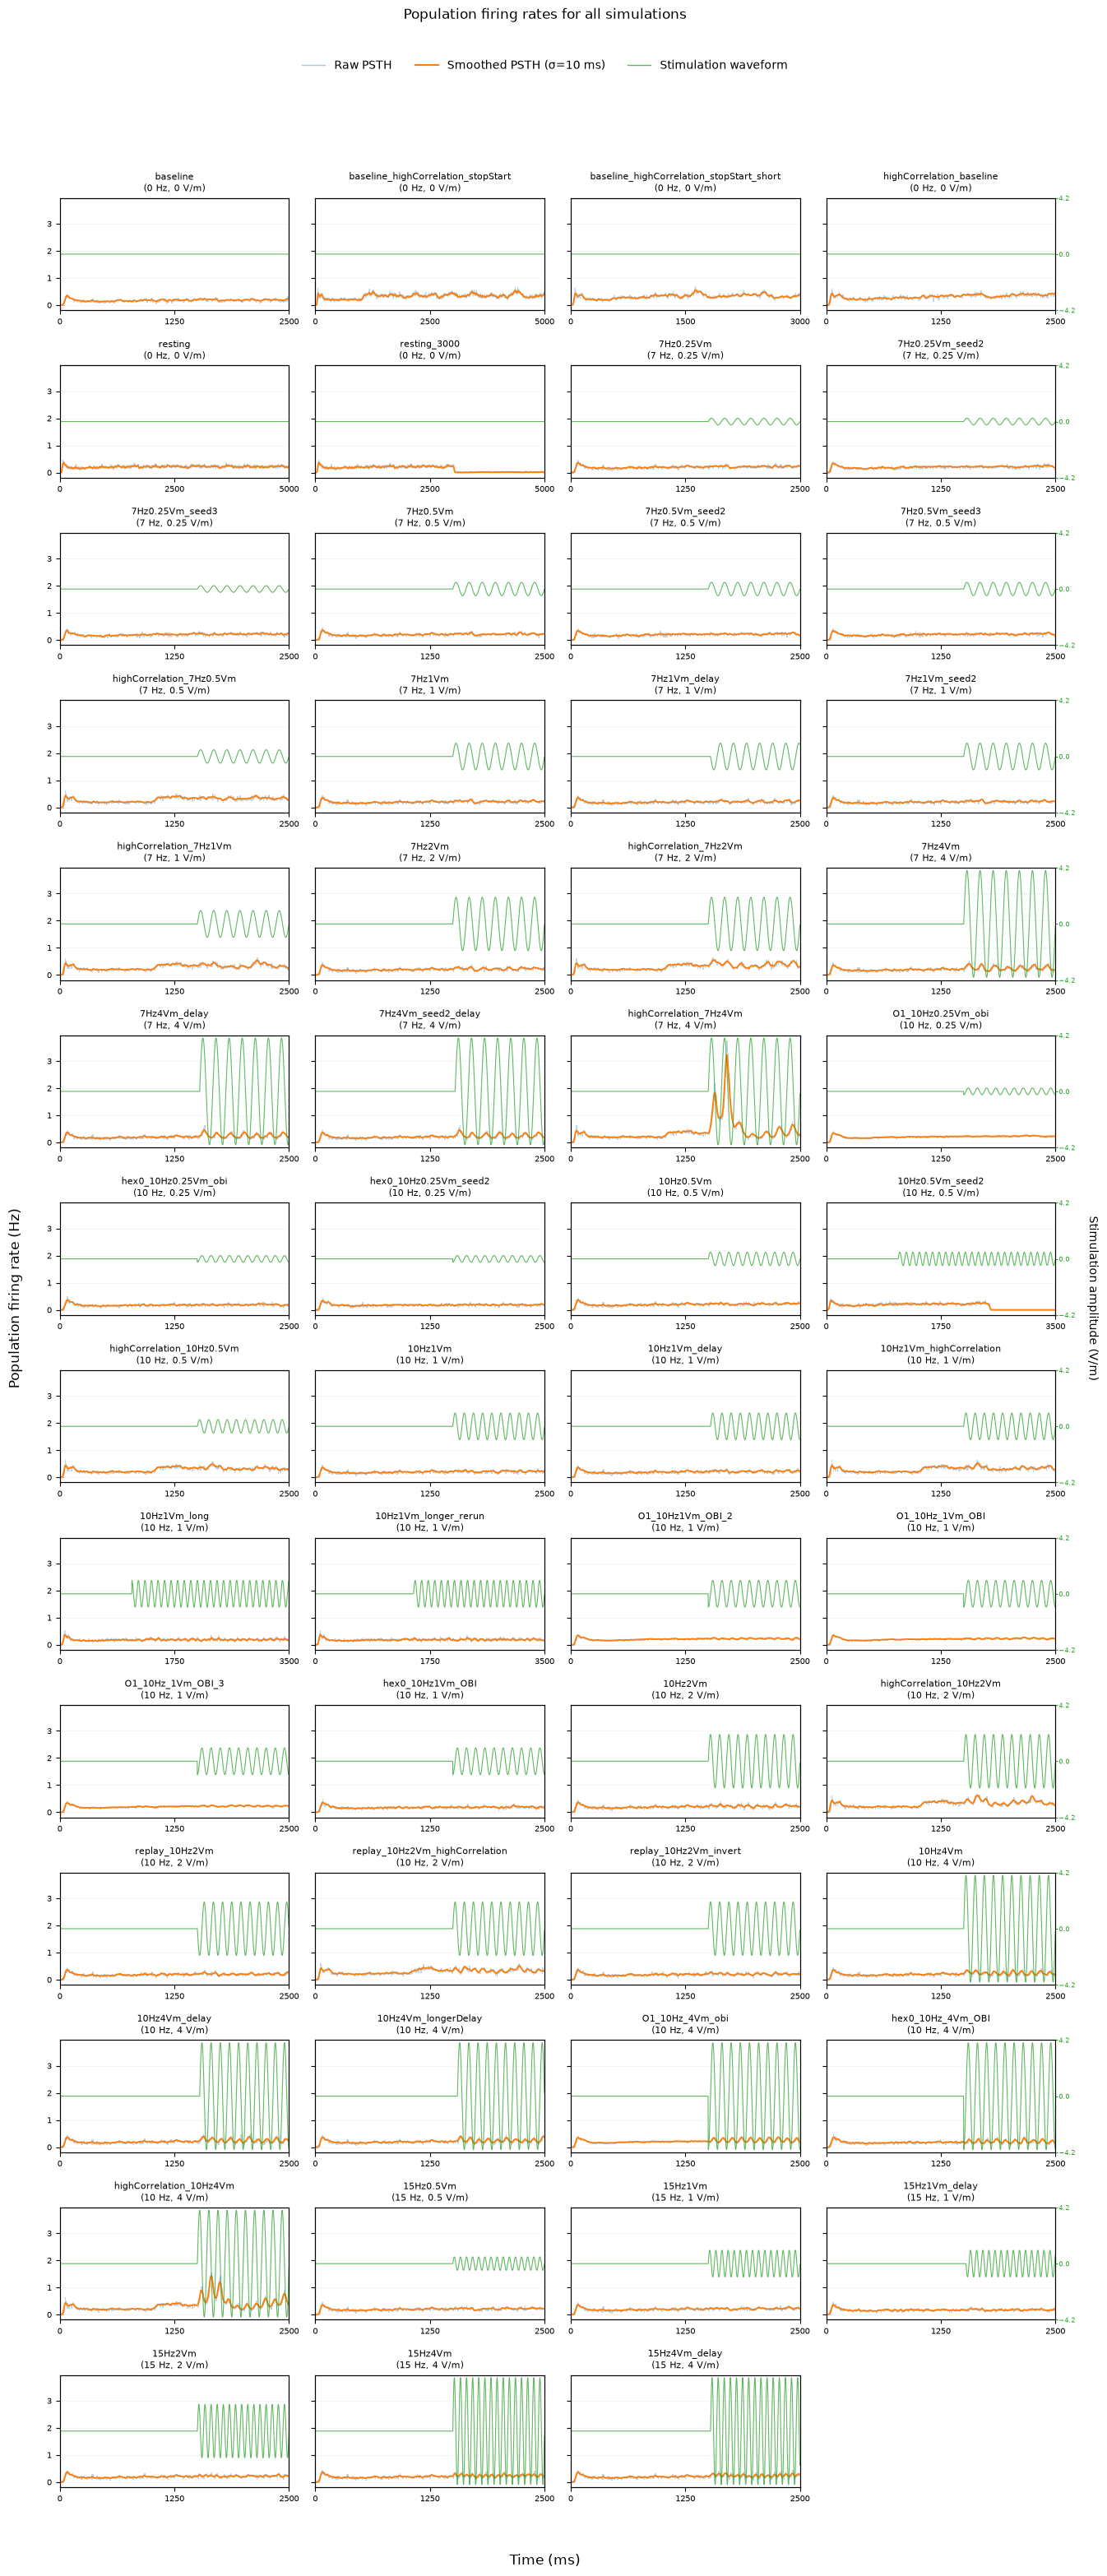

In [ ]:
assert "SETUP_DONE" in globals(), "Run the Setup section at the top of the notebook first."
all_psths = SimpleNamespace(
    rows=simulations.sort_values(["stim_freq", "stim_amp", "sim_id"]).reset_index(drop=True),
    bin_width=5,
    sigma_ms=10,
    ncols=4,
    waveform_step_ms=1,  # downsample only the displayed waveform; PSTH data are unchanged
)
all_psths.loaded = [load_simulation(path) for path in all_psths.rows["source_file"]]
all_psths.labels = [
    f"{row.sim_id}\n({row.stim_freq:g} Hz, {row.stim_amp:g} V/m)"
    for row in all_psths.rows.itertuples(index=False)
]
all_psths.fig, all_psths.axes = psth_grid_plot(
    [sim.spikes for sim in all_psths.loaded],
    [sim.cell_to_rank for sim in all_psths.loaded],
    [sim.simulation for sim in all_psths.loaded],
    all_psths.labels,
    bin_width=all_psths.bin_width,
    sigma_ms=all_psths.sigma_ms,
    ncols=all_psths.ncols,
    waveform_step_ms=all_psths.waveform_step_ms,
)
all_psths.fig.savefig(
    FIG_DIR / "all_simulation_psths.svg", dpi=300, bbox_inches="tight"
)


# Power spectra: stimulation amplitudes overlaid per frequency

One figure per network state and stimulation frequency (3 low-correlation + 2 high-correlation = 5).
Each overlays the Welch PSD of the population firing rate for every amplitude of that frequency plus
the unstimulated baseline of the same state. Seeds of one condition are averaged.

All spectra use `PSD_NPERSEG` samples per segment, so they share one frequency grid; with 5 ms bins
that is a resolution of `1000 / (5 * PSD_NPERSEG)` Hz (the 1 s stimulation window allows no finer).
`normalize=True` in the plot cell compares spectral shape instead of absolute power.

In [ ]:
assert "SETUP_DONE" in globals(), "Run the Setup section at the top of the notebook first."
psd = SimpleNamespace(
    cell_type="ALL",          # "PYR", "INT_INH" or "INT_EXC" for a cell-type-specific version
    nperseg=PSD_NPERSEG,
    runs={state: select_simulations(simulations, **SELECT[state], freqs=FREQS[state], amps=AMPS)
          for state in STATES},
    baseline={state: sim_row(simulations, BASELINE_ID[state]) for state in STATES},
)
psd.spectra = {
    (state, freq): psd_by_amplitude(psd.runs[state], psd.baseline[state], freq, AMPS,
                                    cell_type=psd.cell_type, nperseg=100)
    for state in STATES for freq in FREQS[state]
}
{key: sorted(spectra) for key, spectra in psd.spectra.items()}

{('low', 7): [0.0, 0.25, 0.5, 1.0, 2.0, 4.0],
 ('low', 10): [0.0, 0.5, 1.0, 2.0, 4.0],
 ('low', 15): [0.0, 0.5, 1.0, 2.0, 4.0],
 ('high', 7): [0.0, 0.5, 1.0, 2.0, 4.0],
 ('high', 10): [0.0, 0.5, 1.0, 2.0, 4.0]}

Low-correlation
Low-correlation
Low-correlation
High-correlation
High-correlation


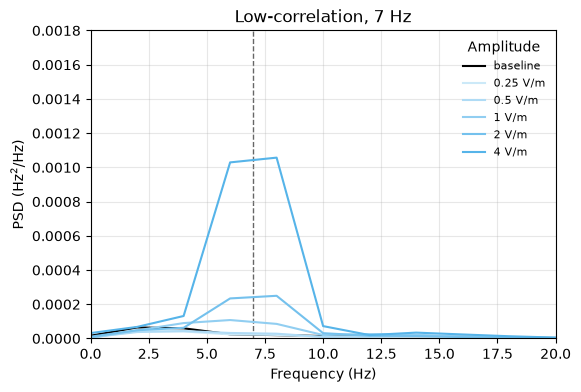

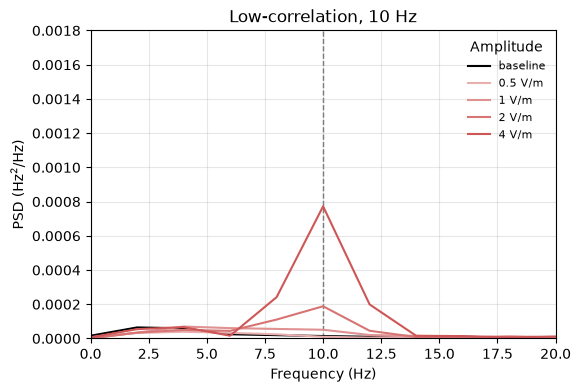

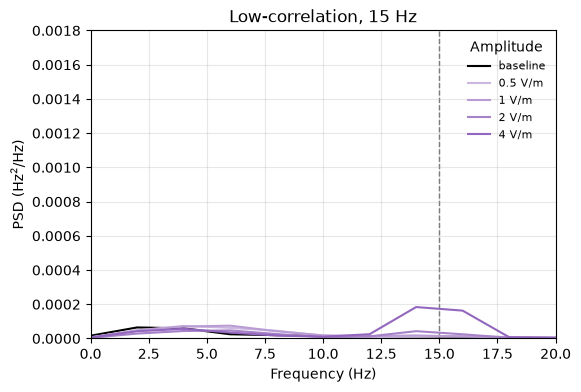

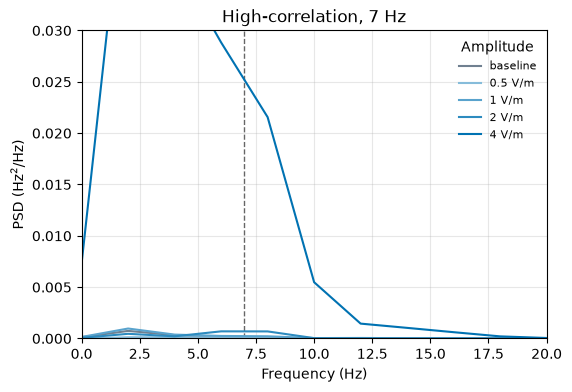

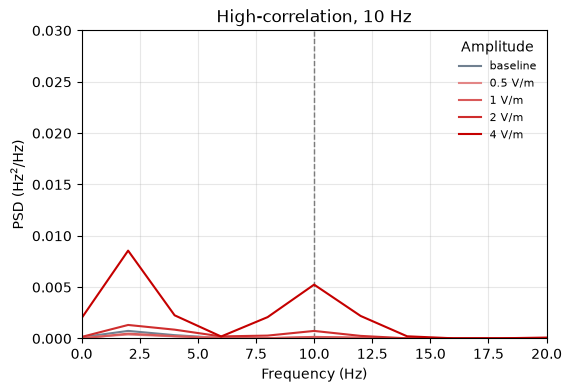

In [ ]:
for (state, freq), spectra in psd.spectra.items():
    amplitudes = sorted(spectra)
    colors = amp_colors(state, freq)
    fig = plot_psd_overlay(
        [spectra[amp] for amp in amplitudes],
        labels=["baseline" if amp == 0 else f"{amp:g} V/m" for amp in amplitudes],
        colors=[BASELINE_COLORS[state] if amp == 0 else colors[amp] for amp in amplitudes],
        stim_freq=freq, log_scale=False, normalize=False,
        state=STATE_LABELS[state], legend_title="Amplitude",
    )
    print(STATE_LABELS[state])
    fig.savefig(FIG_DIR / f"psd_overlay_{state}Correlation_{freq}Hz.svg", dpi=300, bbox_inches="tight")

## PSD relative to the corresponding baseline

For each network state and frequency, divide each stimulated PSD by the **same state's baseline PSD at the same frequency**:

`R(f) = mean_seed PSD_stim(f) / PSD_baseline(f)`.

**How it is calculated** (PSDs from the preceding `psd` cell, `utils.psd_by_amplitude`):

1. *Firing rate.* Spikes of the cell group are counted in 5 ms bins, divided by bin width × number of cells, and smoothed with a Gaussian of σ = 10 ms (`get_firingrate_hist`).
2. *Window.* Stimulated runs use their own `[delay, tstop]` from `data.csv` (1.5–2.5 s for the standard runs). The baselines use 1.5 s to their `tstop` (1.5–5 s).
3. *Welch PSD* (`scipy.signal.welch`): 100-sample (0.5 s) Hann segments, 50 % overlap, constant detrend, one-sided density scaling, giving 2 Hz frequency spacing. A 1 s stimulation window yields three segments.
4. *Seeds.* Runs of one state, frequency and amplitude are averaged as linear PSDs before division.
5. *Ratio.* Each mean PSD is divided by the same state's baseline PSD, frequency by frequency. The dB plots show `10*log10(R)`.
6. *Shared y-axis.* All dB plots (every state and stimulation frequency) use one y-range from `src.psd.shared_ylim`: the minimum and maximum of every plotted curve between 5 and 20 Hz, rounded outward to 5 dB. Only plotted frequencies count; autoscaling previously also fitted the hidden 0–5 Hz and >20 Hz bins. The linear fold-change plots keep their own axes, because high correlation at 4 V/m reaches several hundred-fold and would flatten the others.

A value of 1 means unchanged power, 2 means twice baseline, and 0.5 means half baseline. In decibels use `10*log10(R)` (0 dB unchanged; doubling is about +3 dB). This removes the baseline's frequency-dependent shape and expresses proportional changes relative to each network state's spontaneous activity. It does not normalize each spectrum to total power.

The existing pairings are `resting` for low correlation and `baseline_highCorrelation_stopStart` for high correlation, using the baseline interval 1.5–5 s. These are separate unstimulated runs, not the initial rest of each stimulated run. The numerator is the seed-mean linear PSD. All estimates must use matching bin size, smoothing, window, segment length, and frequency grid. The preceding computation currently uses 100-sample segments (0.5 s, 2 Hz spacing); a plotted line interpolates between those bins.

Small/noisy baseline values can produce large ratios. Zero or invalid baseline bins are masked, rather than stabilized by an arbitrary epsilon. Keep the absolute PSD plots for context: a large fold change need not mean large absolute power, and a ratio alone is not evidence of statistical significance or phase locking. Short stimulated intervals have few Welch segments. The timing metadata for `10Hz0.5Vm_seed2` requires verification (CSV ends at 2.5 s, config at 3.5 s).

Reference: [FieldTrip relative baseline normalization](https://www.fieldtriptoolbox.org/tutorial/sensor/timefrequencyanalysis/).


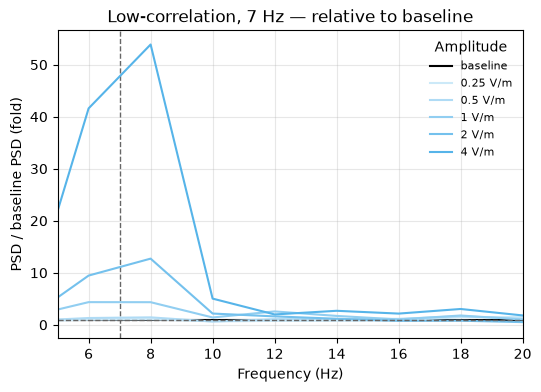

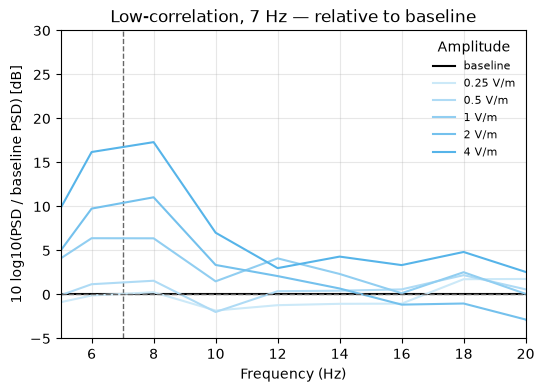

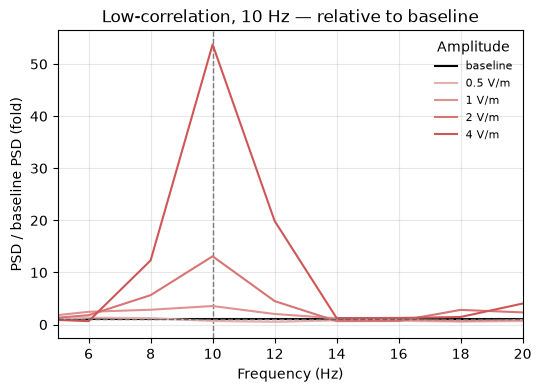

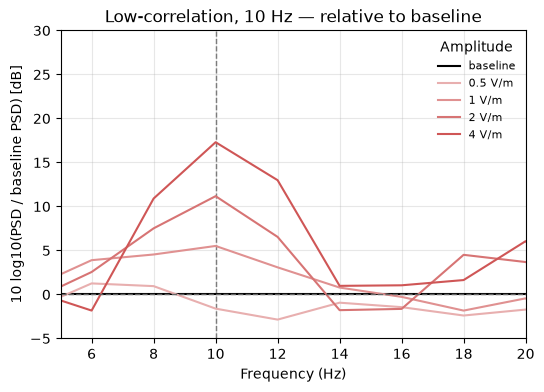

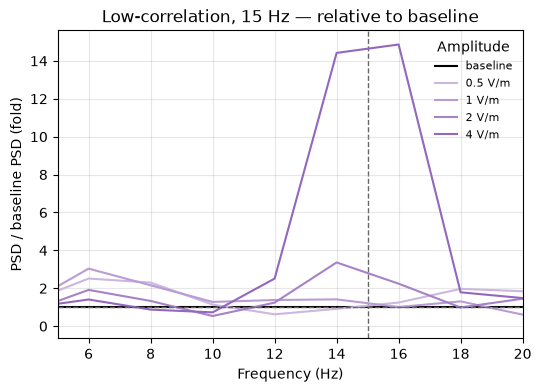

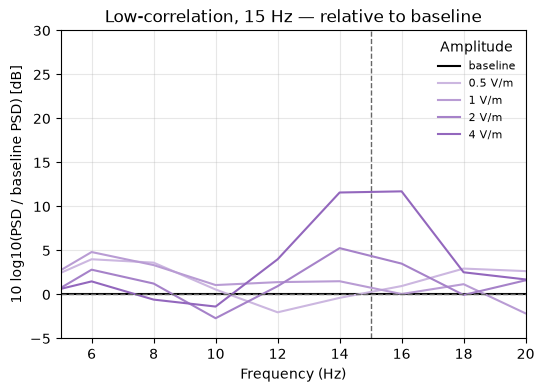

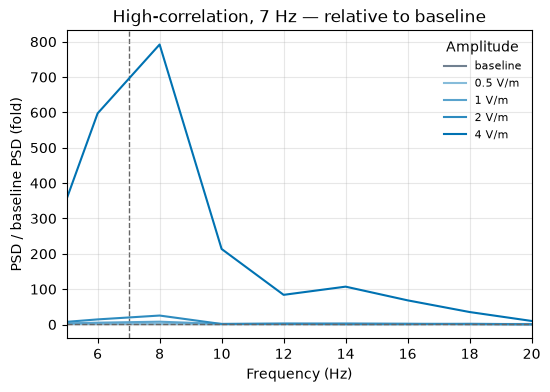

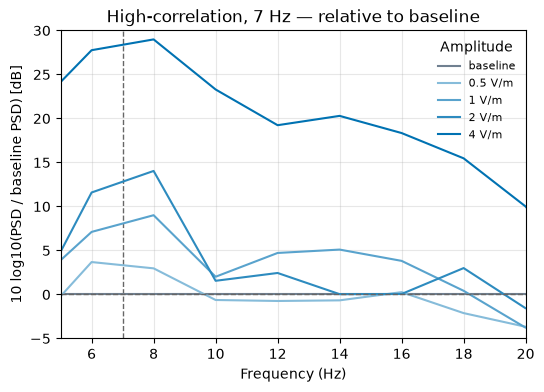

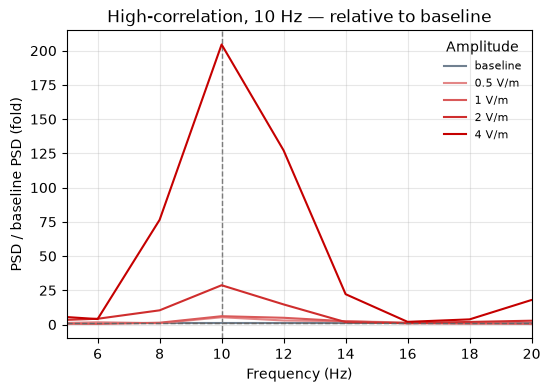

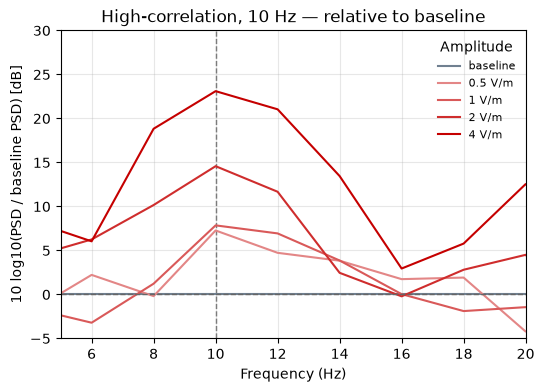

In [ ]:
# Reuse the exact PSD arrays and baseline from the preceding overlay section.
from src.psd import baseline_psd_ratio, shared_ylim

# One y-axis for every dB plot (all states and frequencies), from the plotted 5-20 Hz values.
psd.db_ylim = shared_ylim(
    [baseline_psd_ratio(spectrum, spectra[0.0], db=True)
     for spectra in psd.spectra.values() for spectrum in spectra.values()],
    xlim=(5, 20),
)
for (state, freq), spectra in psd.spectra.items():
    amplitudes = sorted(spectra)
    colors = amp_colors(state, freq)
    for in_db, suffix in ((False, "ratio"), (True, "ratio_db")):
        fig = plot_psd_overlay(
            [spectra[amp] for amp in amplitudes],
            labels=["baseline" if amp == 0 else f"{amp:g} V/m" for amp in amplitudes],
            colors=[BASELINE_COLORS[state] if amp == 0 else colors[amp] for amp in amplitudes],
            stim_freq=freq, normalize=False, log_scale=False, xlim=(5, 20),
            baseline_psd=spectra[0.0], baseline_db=in_db, ylim=psd.db_ylim if in_db else None,
            state=STATE_LABELS[state], legend_title="Amplitude",
            title=f"{STATE_LABELS[state]}, {freq} Hz — relative to baseline",
        )
        fig.savefig(FIG_DIR / f"psd_{suffix}_{state}Correlation_{freq}Hz.svg",
                    dpi=300, bbox_inches="tight")


# Long stimulation: first half, second half and full-period PSD / PLV

This section analyses **`10Hz1Vm_long` only**, using the complete configured stimulation interval (1100–3500 ms): **first half 1100–2300 ms**, **second half 2300–3500 ms**, and **full period 1100–3500 ms**. It runs independently of Setup and the earlier figure sections. Set `LONG_CONFIG` explicitly if the simulation is stored elsewhere.

**Signal and windows.** All reported population spikes are counted in 5 ms bins and divided by bin duration × the complete configured node-set size, including silent cells. As in the other population PSDs, a Gaussian with σ = 10 ms smooths the rate. Smoothing is applied separately within each window with reflected edges, so halves do not borrow activity across their boundary. Windows are half-open `[start, stop)`; the midpoint belongs only to the second half and the full window contains exactly their union. PLV uses unsmoothed spike times.

**Two complementary PSD views.** The left panel holds the estimator fixed: Hann Welch segments of **1200 ms**, 50% overlap, constant detrending and one-sided density scaling. Each half supplies one segment; the full period supplies three, including a segment crossing the midpoint. The right-hand difference panel subtracts these matched estimates, with signs explicitly labelled. The middle panel instead uses one Hann periodogram over each entire window (1200 / 1200 / 2400 ms) to show what changes when all available duration is used. Its full-period peak height and width also reflect the different spectral smoothing and should not be read directly as a power increase.

**What 2 Hz means here.** The full period contains **4.8 cycles at 2 Hz**, compared with **2.4 cycles per half**. Native Fourier-bin spacing is 0.4167 Hz for 2400 ms and 0.8333 Hz for 1200 ms; Hann equivalent-noise bandwidth is 0.625 and 1.25 Hz respectively. The common 0.2 Hz plotting grid comes from zero padding and adds no resolving power. The 2 Hz values in the tables are PSD density evaluated on that grid, not integrated band power. Low-frequency estimates from each half remain noisy because so few cycles are observed.

**PLV definition.** `abs(mean(exp(1j * 2*pi*10*(spike_time - stimulation_onset))))`, pooled across population spikes, at the **10 Hz stimulation frequency**. This is the population metric used elsewhere in the notebook, not an average of individual-neuron PLVs. Constant field-phase offsets cannot change its magnitude. Full-period PLV is the magnitude of the spike-count-weighted complex half-period vectors, not the mean of their magnitudes. The plots show values and signed absolute differences for second−first, first−full and second−full. Spike counts are reported because finite-sample PLV bias depends on sample size. These are descriptive comparisons of one simulation; halves versus their full union are not independent replicates, and no significance test is claimed.


,window,start_ms,stop_ms,duration_ms,n_spikes,mean_rate_hz,plv,welch_segments,native_bin_spacing_hz,matched_psd_2hz,matched_psd_10hz
0,First half,1100.0,2300.0,1200.0,6793,0.187507,0.052287,1,0.833333,0.000025,0.000120
1,Second half,2300.0,3500.0,1200.0,6966,0.192282,0.061842,1,0.833333,0.000031,0.000146
2,Full period,1100.0,3500.0,2400.0,13759,0.189895,0.055331,3,0.416667,0.000043,0.000143


,comparison,delta_plv,delta_matched_psd_2hz,delta_matched_psd_10hz
0,Second half minus First half,0.009556,0.000006,0.000026
1,First half minus Full period,-0.003045,-0.000018,-0.000023
2,Second half minus Full period,0.006511,-0.000012,0.000003


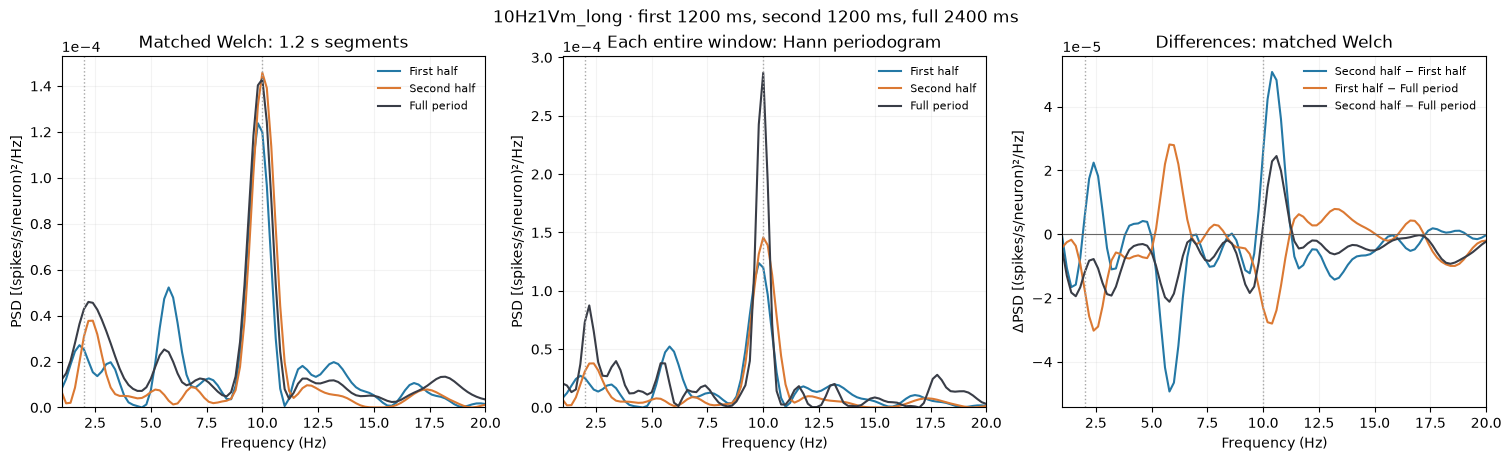

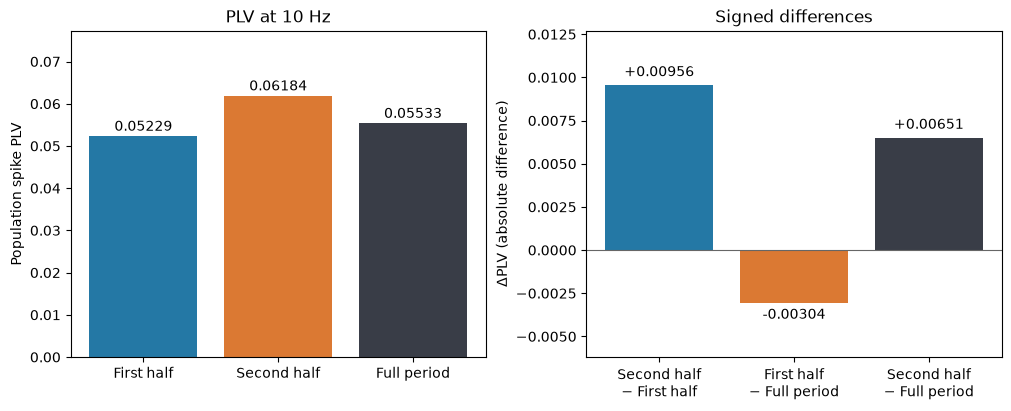

In [ ]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

long_root = Path.cwd() if (Path.cwd() / "data.csv").is_file() else Path.cwd().parent
if str(long_root) not in sys.path:
    sys.path.insert(0, str(long_root))
from src.stimulation_windows import find_long_config, load_long_run, export_comparison

LONG_CONFIG = None  # Optional: Path("/path/to/10Hz1Vm_long/sim_with_stim.json")
LONG_NODE_SETS = Path.home() / "Downloads/O1_data/node_sets.json"
long_config = Path(LONG_CONFIG) if LONG_CONFIG is not None else find_long_config(long_root)
long_windows = load_long_run(long_config, LONG_NODE_SETS)
long_output = long_root / "output/10Hz1Vm_long_windows"
long_summary, long_differences, long_figures = export_comparison(long_windows, long_output)
display(long_summary.drop(columns=["plv_real", "plv_imag"]))
display(long_differences)
for long_figure in long_figures:
    display(long_figure)
    plt.close(long_figure)


In [ ]:
long_first, long_second, long_full = [long_summary.iloc[i] for i in range(3)]
long_changes = {
    frequency: 100 * (long_second[f"matched_psd_{frequency}hz"] / long_first[f"matched_psd_{frequency}hz"] - 1)
    if long_first[f"matched_psd_{frequency}hz"] > 0 else float("nan")
    for frequency in (2, 10)
}
display(Markdown(f"""
**Results for this recording.** The first and second halves contain {int(long_first.n_spikes):,} and
{int(long_second.n_spikes):,} spikes. Population PLV at 10 Hz is **{long_first.plv:.5f}** in the first
half, **{long_second.plv:.5f}** in the second, and **{long_full.plv:.5f}** over the full period.
The second−first change is **{long_second.plv-long_first.plv:+.5f}**; first−full is
**{long_first.plv-long_full.plv:+.5f}**, and second−full is **{long_second.plv-long_full.plv:+.5f}**.

With matched Welch settings, second-half PSD relative to the first changes by
**{long_changes[2]:+.1f}% at 2 Hz** and **{long_changes[10]:+.1f}% at 10 Hz**.
The tables above give absolute densities and all pairwise differences. Full-period matched Welch
includes the central overlapping segment, so it need not equal the arithmetic mean of the two
half-period PSDs. Its three segments reduce variability but retain the same 1200 ms spectral
smoothing; only the separate full-period periodogram uses the longer 2400 ms spectral window.

Saved figures (PNG/SVG), numerical spectra (NPZ), window and difference tables (CSV), and the
source/parameter manifest are in `output/10Hz1Vm_long_windows/`.
"""))



**Results for this recording.** The first and second halves contain 6,793 and
6,966 spikes. Population PLV at 10 Hz is **0.05229** in the first
half, **0.06184** in the second, and **0.05533** over the full period.
The second−first change is **+0.00956**; first−full is
**-0.00304**, and second−full is **+0.00651**.

With matched Welch settings, second-half PSD relative to the first changes by
**+22.0% at 2 Hz** and **+21.6% at 10 Hz**.
The tables above give absolute densities and all pairwise differences. Full-period matched Welch
includes the central overlapping segment, so it need not equal the arithmetic mean of the two
half-period PSDs. Its three segments reduce variability but retain the same 1200 ms spectral
smoothing; only the separate full-period periodogram uses the longer 2400 ms spectral window.

Saved figures (PNG/SVG), numerical spectra (NPZ), window and difference tables (CSV), and the
source/parameter manifest are in `output/10Hz1Vm_long_windows/`.


# Figure 3: tACS entrains network activity

Low-correlation runs at 7, 10 and 15 Hz. Plots use seed-averaged rows (`fig3.merged`); statistics use every seed (`fig3.runs`).

In [124]:
assert "SETUP_DONE" in globals(), "Run the Setup section at the top of the notebook first."
fig3 = SimpleNamespace(
    freqs=FREQS["low"],
    colors=FREQ_COLORS["low"],
    runs=select_simulations(simulations, **SELECT["low"], freqs=FREQS["low"], amps=AMPS),
    baseline=sim_row(simulations, BASELINE_ID["low"]),
)
fig3.merged = {freq: merge_and_average(rows_at(fig3.runs, freq=freq)) for freq in fig3.freqs}
fig3.runs[["sim_id", "stim_freq", "stim_amp", "abs_plv", "plv"]]

,sim_id,stim_freq,stim_amp,abs_plv,plv
0,7Hz0.25Vm,7,0.25,0.022295,0.021665-0.005263j
1,7Hz0.25Vm_seed2,7,0.25,0.015638,0.006475+0.014234j
2,7Hz0.25Vm_seed3,7,0.25,0.026968,0.026865-0.002349j
3,7Hz0.5Vm,7,0.50,0.038298,0.037599-0.007281j
4,7Hz0.5Vm_seed2,7,0.50,0.023542,0.011869+0.020331j
5,7Hz0.5Vm_seed3,7,0.50,0.023542,0.011869+0.020331j
6,7Hz1Vm,7,1.00,0.047253,0.046949+0.005350j
7,7Hz1Vm_seed2,7,1.00,0.047253,0.046949+0.005350j
8,7Hz2Vm,7,2.00,0.097127,0.085981+0.045177j
9,7Hz4Vm,7,4.00,0.201545,0.149947+0.134671j


### Mean population firing rate and baseline-calibrated distribution changes

In [125]:
# Firing rates of both network states: each state's stimulated runs and its own baseline.
fig3.state_runs = {
    "low": fig3.runs,
    "high": select_simulations(simulations, **SELECT["high"], freqs=FREQS["high"], amps=AMPS),
}
fig3.state_baselines = {state: sim_row(simulations, BASELINE_ID[state]) for state in STATES}
fig3.firing_rates = pd.concat(
    [population_firing_rates(rows, start_ms=BASELINE_START_MS).assign(state=state, baseline=True)
     for state, rows in fig3.state_baselines.items()]
    + [population_firing_rates(rows).assign(state=state, baseline=False)
       for state, rows in fig3.state_runs.items()],
    ignore_index=True,
)
# Normalised firing rate: every run divided by the baseline firing rate of its own state.
fig3.baseline_rate_hz = fig3.firing_rates[fig3.firing_rates["baseline"]].groupby("state")["firing_rate_hz"].mean()
fig3.firing_rates["baseline_hz"] = fig3.firing_rates["state"].map(fig3.baseline_rate_hz)
fig3.firing_rates["firing_rate_norm"] = fig3.firing_rates["firing_rate_hz"] / fig3.firing_rates["baseline_hz"]
fig3.baseline_rate_hz

state
high    0.357507
low     0.221672
Name: firing_rate_hz, dtype: float64

In [126]:
fig3.firing_rates

,sim_id,stim_freq,stim_amp,firing_rate_hz,mean_firing_rates,state,baseline,baseline_hz,firing_rate_norm
0,resting,0,0.00,0.221672,"{11: 1.4285714285714286, 305: 5.14285714285714...",low,True,0.221672,1.000000
1,baseline_highCorrelation_stopStart,0,0.00,0.357507,"{11: 2.0, 305: 6.285714285714286, 350: 0.28571...",high,True,0.357507,1.000000
2,7Hz0.25Vm,7,0.25,0.222160,"{11: 2.0, 305: 5.0, 393: 3.0, 473: 0.0, 587: 1...",low,False,0.221672,1.002199
3,7Hz0.25Vm_seed2,7,0.25,0.223750,"{11: 2.0, 137: 0.0, 141: 1.0, 288: 0.0, 305: 5...",low,False,0.221672,1.009371
4,7Hz0.25Vm_seed3,7,0.25,0.222325,"{11: 1.0, 305: 5.0, 393: 3.0, 480: 0.0, 587: 0...",low,False,0.221672,1.002946
5,7Hz0.5Vm,7,0.50,0.222723,"{11: 2.0, 305: 5.0, 393: 3.0, 473: 0.0, 587: 1...",low,False,0.221672,1.004739
6,7Hz0.5Vm_seed2,7,0.50,0.224412,"{11: 2.0, 137: 0.0, 141: 1.0, 288: 0.0, 305: 5...",low,False,0.221672,1.012360
7,7Hz0.5Vm_seed3,7,0.50,0.224412,"{11: 2.0, 137: 0.0, 141: 1.0, 288: 0.0, 305: 5...",low,False,0.221672,1.012360
8,7Hz1Vm,7,1.00,0.226764,"{11: 2.0, 305: 5.0, 393: 3.0, 473: 0.0, 554: 1...",low,False,0.221672,1.022969
9,7Hz1Vm_seed2,7,1.00,0.226764,"{11: 2.0, 305: 5.0, 393: 3.0, 473: 0.0, 554: 1...",low,False,0.221672,1.022969


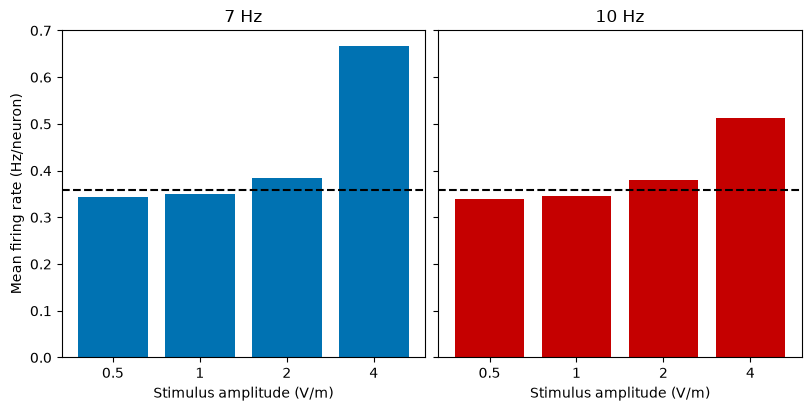

In [ ]:
# High-correlation state only (Figure 3).
low_rates = fig3.firing_rates[fig3.firing_rates["state"] == "high"]

fig, axes = plt.subplots(1, len([7,10]), figsize=(8, 4), sharey=True, layout="constrained")
for ax, freq in zip(axes, [7,10]):
    for position, amp in enumerate([0.5,1,2,4]):
        values = rows_at(low_rates[~low_rates["baseline"]], freq, amp)["firing_rate_hz"]
        if len(values):
            ax.errorbar(position, values.mean(), yerr=values.std(), color=FREQ_COLORS["high"][freq])
            ax.bar(position, values.mean(), color=FREQ_COLORS["high"][freq])
    ax.axhline(low_rates.loc[low_rates["baseline"], "firing_rate_hz"].mean(),
               color="black", linestyle="--")
    
    ax.set(xticks=range(len([0.5,1,2,4])), xticklabels=[0.5,1,2,4], xlabel="Stimulus amplitude (V/m)", title=f"{freq} Hz")
   
axes[0].set_ylabel("Mean firing rate (Hz/neuron)")
fig.savefig(FIG_DIR / "firing_rates_high.svg", dpi=300)

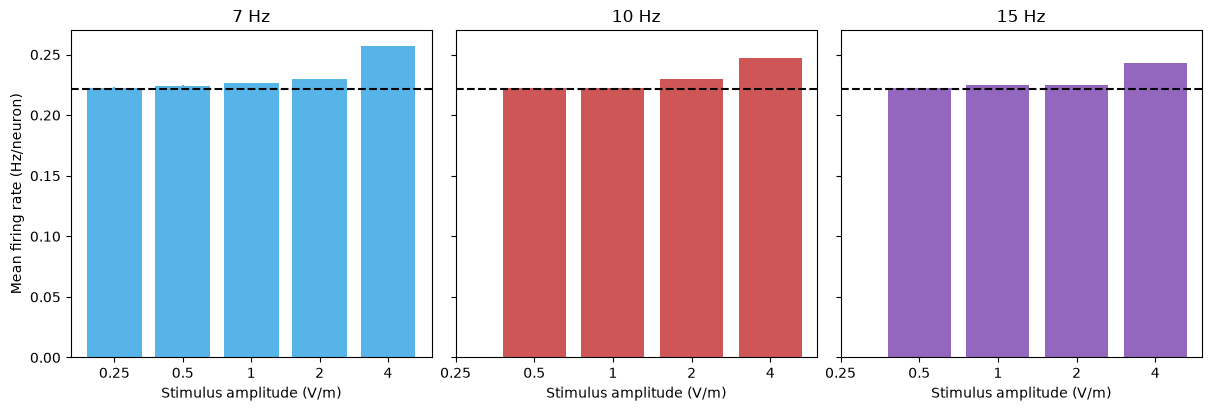

In [ ]:
# Low-correlation state only (Figure 3).
low_rates = fig3.firing_rates[fig3.firing_rates["state"] == "low"]

fig, axes = plt.subplots(1, len(fig3.freqs), figsize=(12, 4), sharey=True, layout="constrained")
for ax, freq in zip(axes, fig3.freqs):
    for position, amp in enumerate(AMPS):
        values = rows_at(low_rates[~low_rates["baseline"]], freq, amp)["firing_rate_hz"]
        if len(values):
            ax.errorbar(position, values.mean(), yerr=values.std(), color=fig3.colors[freq])
            ax.bar(position, values.mean(), color=fig3.colors[freq])
    ax.axhline(low_rates.loc[low_rates["baseline"], "firing_rate_hz"].mean(),
               color="black", linestyle="--")
    
    ax.set(xticks=range(len(AMPS)), xticklabels=AMPS, xlabel="Stimulus amplitude (V/m)", title=f"{freq} Hz")
   
axes[0].set_ylabel("Mean firing rate (Hz/neuron)")
fig.savefig(FIG_DIR / "firing_rates.svg", dpi=300)

TypeError: Axes.bar() missing 1 required positional argument: 'height'

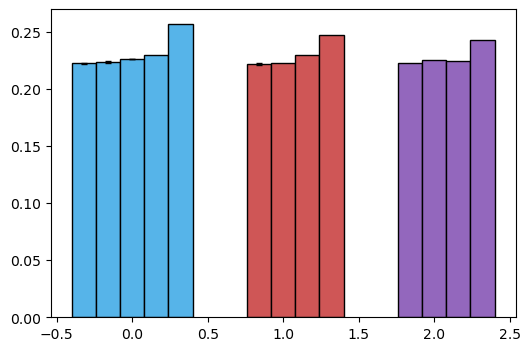

In [130]:
import numpy as np

low_rates = fig3.firing_rates[fig3.firing_rates["state"] == "low"]

fig, ax = plt.subplots(figsize=(6,4))

n = len(AMPS)
width = 0.8 / n

bar_x, bar_lab = [], []
for g, freq in enumerate(fig3.freqs):
    for k, amp in enumerate(AMPS):
        values = rows_at(low_rates[~low_rates["baseline"] & (low_rates["state"] == "low")], freq, amp)["firing_rate_hz"]
        if not len(values):
            continue
        x = g + (k - (n - 1) / 2) * width
        ax.bar(x, values.mean(), width=width,
               color=FREQ_COLORS['low'][freq], edgecolor="black")
        ax.errorbar(x, values.mean(), yerr=values.std() / np.sqrt(len(values)),
                    color="black", capsize=2, linewidth=1, zorder=4)
        bar_x.append(x); bar_lab.append(amp)

ax.bar(low_rates.loc[low_rates["baseline"], "firing_rate_hz"].mean(),
        color="black", linestyle="--", linewidth=1, zorder=3,
        label="Unstimulated baseline")

# amplitudes on every bar (minor ticks), frequency per group (major ticks)
ax.set_xticks(bar_x, minor=True)
ax.set_xticklabels(bar_lab, minor=True, fontsize=7)
ax.set_xticks(range(len(fig3.freqs)))
ax.set_xticklabels([f"{f} Hz" for f in fig3.freqs])
ax.tick_params(axis="x", which="major", length=0, pad=18)
ax.tick_params(axis="x", which="minor", length=3)

ax.set_xlabel("Stimulus amplitude (V/m)")
ax.set_ylabel("Mean firing rate (Hz/neuron)")
print(ax.get_ylim()[1] * 1.18)
ax.set_ylim(top=0.7)   # headroom for the legend
ax.legend(frameon=False, loc="upper right")
    # from matplotlib.patches import Patch

    # # keep a handle on the baseline line
    # base_line = ax.axhline(low_rates.loc[low_rates["baseline"], "firing_rate_hz"].mean(),
    #                        color="black", linestyle="--", linewidth=1, zorder=3,
    #                        label="Unstimulated baseline")

    # ax.set_ylim(top=ax.get_ylim()[1] * 1.30)   # more headroom than before, for two legends


    # leg_amp = ax.legend(handles=amp_handles, title="Amplitude (V/m)", frameon=False,
    #                     loc="upper left", ncol=len(AMPS), handlelength=1.2,
    #                     columnspacing=0.8, fontsize=8, title_fontsize=8)
    # ax.add_artist(leg_amp)                      # keeps it when the second legend is added
    # ax.legend(handles=[base_line], frameon=False, loc="upper right", fontsize=8)
fig.savefig(FIG_DIR / "firing_rates_low.svg", bbox_inches="tight")

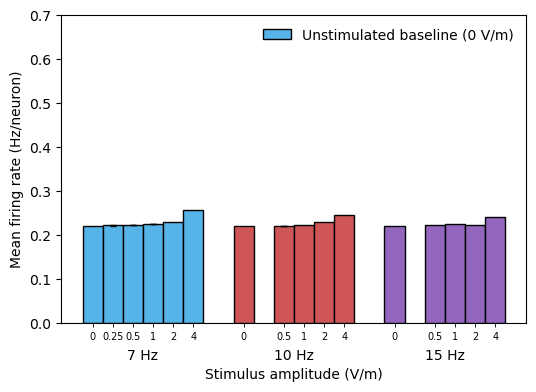

In [132]:
import numpy as np

low_rates = fig3.firing_rates[fig3.firing_rates["state"] == "low"]
baseline_values = low_rates.loc[low_rates["baseline"], "firing_rate_hz"].dropna()
stimulated_rates = low_rates[~low_rates["baseline"]]

fig, ax = plt.subplots(figsize=(6, 4))

amplitudes = [0] + [amp for amp in AMPS if amp != 0]
n = len(amplitudes)
width = 0.8 / n

bar_x, bar_lab = [], []
for g, freq in enumerate(fig3.freqs):
    for k, amp in enumerate(amplitudes):
        values = (baseline_values if amp == 0 else
                  rows_at(stimulated_rates, freq, amp)["firing_rate_hz"].dropna())
        if not len(values):
            continue
        x = g + (k - (n - 1) / 2) * width
        ax.bar(x, values.mean(), width=width,
               color=FREQ_COLORS["low"][freq],
               edgecolor="black",
               label="Unstimulated baseline (0 V/m)" if amp == 0 and g == 0 else None)
        # SEM requires at least two observations; a single baseline has no SEM.
        if len(values) > 1:
            ax.errorbar(x, values.mean(), yerr=values.std() / np.sqrt(len(values)),
                        color="black", capsize=2, linewidth=1, zorder=4)
        bar_x.append(x)
        bar_lab.append(f"{amp:g}")

# Amplitudes on every bar; frequency labels below each group.
ax.xaxis.remove_overlapping_locs = False
ax.set_xticks(bar_x, minor=True)
ax.set_xticklabels(bar_lab, minor=True, fontsize=7)
ax.set_xticks(range(len(fig3.freqs)))
ax.set_xticklabels([f"{f} Hz" for f in fig3.freqs])
ax.tick_params(axis="x", which="major", length=0, pad=18)
ax.tick_params(axis="x", which="minor", length=3)
ax.set_xlabel("Stimulus amplitude (V/m)")
ax.set_ylabel("Mean firing rate (Hz/neuron)")
ax.set_ylim(top=0.7)
ax.legend(frameon=False, loc="upper right")
fig.savefig(FIG_DIR / "firing_rates_low.svg", bbox_inches="tight")

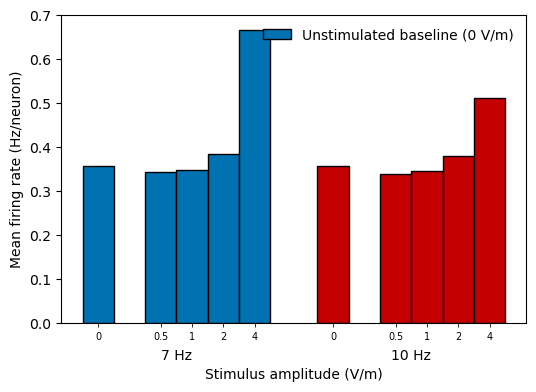

In [134]:
import numpy as np

low_rates = fig3.firing_rates[fig3.firing_rates["state"] == "high"]
baseline_values = low_rates.loc[low_rates["baseline"], "firing_rate_hz"].dropna()
stimulated_rates = low_rates[~low_rates["baseline"]]

fig, ax = plt.subplots(figsize=(6, 4))

amplitudes = [0] + [amp for amp in AMPS if amp != 0]
n = len(amplitudes)
width = 0.8 / n

bar_x, bar_lab = [], []
for g, freq in enumerate([7, 10]):
    for k, amp in enumerate(amplitudes):
        values = (baseline_values if amp == 0 else
                  rows_at(stimulated_rates, freq, amp)["firing_rate_hz"].dropna())
        if not len(values):
            continue
        x = g + (k - (n - 1) / 2) * width
        ax.bar(x, values.mean(), width=width,
               color=FREQ_COLORS["high"][freq],
               edgecolor="black",
               label="Unstimulated baseline (0 V/m)" if amp == 0 and g == 0 else None)
        # SEM requires at least two observations; a single baseline has no SEM.
        if len(values) > 1:
            ax.errorbar(x, values.mean(), yerr=values.std() / np.sqrt(len(values)),
                        color="black", capsize=2, linewidth=1, zorder=4)
        bar_x.append(x)
        bar_lab.append(f"{amp:g}")

# Amplitudes on every bar; frequency labels below each group.
ax.xaxis.remove_overlapping_locs = False
ax.set_xticks(bar_x, minor=True)
ax.set_xticklabels(bar_lab, minor=True, fontsize=7)
ax.set_xticks(range(len([7, 10])))
ax.set_xticklabels([f"{f} Hz" for f in [7, 10]])
ax.tick_params(axis="x", which="major", length=0, pad=18)
ax.tick_params(axis="x", which="minor", length=3)
ax.set_xlabel("Stimulus amplitude (V/m)")
ax.set_ylabel("Mean firing rate (Hz/neuron)")
ax.set_ylim(top=0.7)
ax.legend(frameon=False, loc="upper right")
fig.savefig(FIG_DIR / "firing_rates_high.svg", bbox_inches="tight")

### Firing rate relative to baseline

One figure per network state: firing rate divided by the baseline firing rate of that state, against
stimulation amplitude, with one line per stimulation frequency. The line starts at the baseline
itself (amplitude 0, ratio 1 by construction); dots are the individual seeds behind each mean.

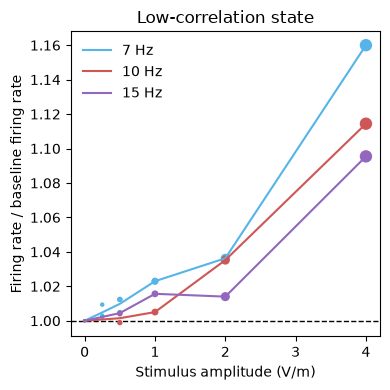

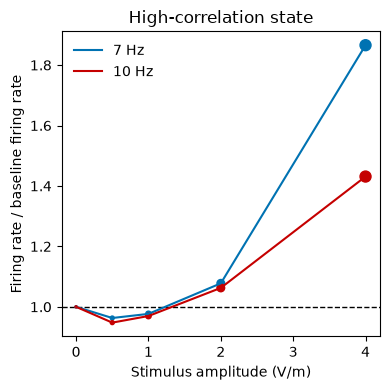

In [ ]:
for state in STATES:
    rates = fig3.firing_rates[(fig3.firing_rates["state"] == state) & (~fig3.firing_rates["baseline"])]
    fig, ax = plt.subplots(figsize=(4, 4))
    for freq in FREQS[state]:
        per_freq = rows_at(rates, freq=freq)
        if per_freq.empty:
            continue
        mean_by_amp = per_freq.groupby("stim_amp")["firing_rate_norm"].mean()
        mean_amps = np.r_[0, mean_by_amp.index]
        mean_rates = np.r_[1.0, mean_by_amp.to_numpy()]
        ax.plot(mean_amps, mean_rates, "-",
                color=FREQ_COLORS[state][freq], label=f"{freq} Hz")
        point_amps = np.r_[0, per_freq["stim_amp"].to_numpy(float)]
        point_rates = np.r_[1.0, per_freq["firing_rate_norm"].to_numpy(float)]
        ax.scatter(point_amps, point_rates, s=marker_sizes(point_amps),
                   color=FREQ_COLORS[state][freq])
    ax.axhline(1.0, color="black", linestyle="--", lw=1, zorder=0)
    ax.set(xlabel="Stimulus amplitude (V/m)", ylabel="Firing rate / baseline firing rate",
           title=f"{STATE_LABELS[state]} state")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"firing_rate_normalized_{state}Correlation.svg", dpi=300, bbox_inches="tight")

In [ ]:
fig3.firing_rates

,sim_id,stim_freq,stim_amp,firing_rate_hz,mean_firing_rates,state,baseline,baseline_hz,firing_rate_norm
0,resting,0,0.00,0.221672,"{11: 1.4285714285714286, 305: 5.14285714285714...",low,True,0.221672,1.000000
1,baseline_highCorrelation_stopStart,0,0.00,0.357507,"{11: 2.0, 305: 6.285714285714286, 350: 0.28571...",high,True,0.357507,1.000000
2,7Hz0.25Vm,7,0.25,0.222160,"{11: 2.0, 305: 5.0, 393: 3.0, 473: 0.0, 587: 1...",low,False,0.221672,1.002199
3,7Hz0.25Vm_seed2,7,0.25,0.223750,"{11: 2.0, 137: 0.0, 141: 1.0, 288: 0.0, 305: 5...",low,False,0.221672,1.009371
4,7Hz0.25Vm_seed3,7,0.25,0.222325,"{11: 1.0, 305: 5.0, 393: 3.0, 480: 0.0, 587: 0...",low,False,0.221672,1.002946
5,7Hz0.5Vm,7,0.50,0.222723,"{11: 2.0, 305: 5.0, 393: 3.0, 473: 0.0, 587: 1...",low,False,0.221672,1.004739
6,7Hz0.5Vm_seed2,7,0.50,0.224412,"{11: 2.0, 137: 0.0, 141: 1.0, 288: 0.0, 305: 5...",low,False,0.221672,1.012360
7,7Hz0.5Vm_seed3,7,0.50,0.224412,"{11: 2.0, 137: 0.0, 141: 1.0, 288: 0.0, 305: 5...",low,False,0.221672,1.012360
8,7Hz1Vm,7,1.00,0.226764,"{11: 2.0, 305: 5.0, 393: 3.0, 473: 0.0, 554: 1...",low,False,0.221672,1.022969
9,7Hz1Vm_seed2,7,1.00,0.226764,"{11: 2.0, 305: 5.0, 393: 3.0, 473: 0.0, 554: 1...",low,False,0.221672,1.022969


### Does the firing rate change with amplitude?

One row per network state and stimulation frequency. **Cells are the matched units**: every cell
contributes its rate at each amplitude of that frequency (seeds averaged), so this is a one-way
repeated-measures ANOVA with the cell as the block, plus a linear contrast across amplitudes.

* `anova_p` / `anova_partial_eta_sq`: is there any difference between amplitude levels, and how
  large. The p-value is Greenhouse-Geisser corrected for sphericity.
* `trend_slope` (Hz per V/m), `trend_percent_per_Vm`, `trend_p`, `trend_cohens_d`: the linear
  increase per V/m, tested against zero over cells. This is the number to quote for "the firing
  rate increases with amplitude".
* `page_p` (monotone increase) and `friedman_p` / `kendall_w`: rank-based versions that do not
  assume normal residuals.
* `run_slope` / `run_p`: the same slope with whole simulations as replicates. This does not rely on
  cells being matched units of a single network, but with only a few runs per condition it has
  little power; treat it as a sanity check on the sign and size, not as the test.

With thousands of cells almost any difference reaches significance, so read the effect sizes
(`trend_percent_per_Vm`, `anova_partial_eta_sq`, `trend_cohens_d`) alongside the p-values.

In [ ]:
fig3.firing_rate_trends = pd.DataFrame([
    dict(state=state, stim_freq=freq,
         **firing_rate_amplitude_trend(fig3.state_runs[state], freq, AMPS,
                                       baseline=fig3.state_baselines[state],
                                       cell_type="ALL", include_baseline=True))
    for state in STATES for freq in FREQS[state]
])
fig3.firing_rate_trends.to_csv(FIG_DIR / "firing_rate_amplitude_trends.csv", index=False)
display(fig3.firing_rate_trends[[
    "state", "stim_freq", "n_cells", "n_conditions", "baseline_rate_hz",
    "anova_F", "anova_p", "anova_partial_eta_sq", "greenhouse_geisser_epsilon",
    "trend_slope", "trend_percent_per_Vm", "trend_p", "trend_cohens_d",
    "page_p", "friedman_p", "kendall_w", "n_runs", "run_slope", "run_p",
]].round(4))


,state,stim_freq,n_cells,n_conditions,baseline_rate_hz,anova_F,anova_p,anova_partial_eta_sq,greenhouse_geisser_epsilon,trend_slope,trend_percent_per_Vm,trend_p,trend_cohens_d,page_p,friedman_p,kendall_w,n_runs,run_slope,run_p
0,low,7,30190,6,0.2217,136.9897,0.0,0.0045,0.6051,0.0086,3.8886,0.0,0.1029,0.9969,0.0,0.0024,10,0.0086,0.0000
1,low,10,30190,5,0.2217,109.5452,0.0,0.0036,0.7233,0.0066,2.9966,0.0,0.0911,0.9992,0.0,0.0027,5,0.0072,0.0017
2,low,15,30190,5,0.2217,81.0204,0.0,0.0027,0.7018,0.0052,2.3334,0.0,0.0825,1.0000,0.0,0.0063,4,0.0057,0.0600
3,high,7,30190,5,0.3575,4852.1640,0.0,0.1385,0.4958,0.0805,22.5183,0.0,0.4817,0.0000,0.0,0.1095,4,0.0955,0.0448
4,high,10,30190,5,0.3575,1963.9502,0.0,0.0611,0.6708,0.0421,11.7651,0.0,0.3384,0.0000,0.0,0.0418,4,0.0509,0.0192


### Figure 3a

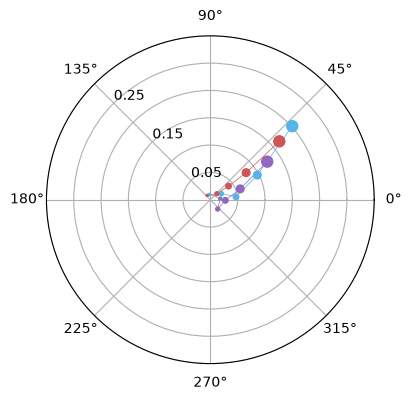

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4), subplot_kw={"projection": "polar"}, layout="constrained")
for freq, merged in fig3.merged.items():
    polar_scatter(ax, merged, get_baseline(fig3.baseline, "plv", freq), z_col="plv", color=fig3.colors[freq], means=True, edgecolors="face", rlim=(0, 0.3))
fig.savefig(FIG_DIR / "entrainmentPolar.svg", dpi=300, bbox_inches="tight")

### Figure 3b

In [ ]:
fig3.merged[7]  # seed-averaged rows of one frequency


,stim_amp,stim_freq,n_seeds,sim_id,time_import,dt,tstop,seed,simulator,node_set,delay,duration,stim_phase,stim_orientation,stim_rampup,stim_rampdown,analysis_start,analysis_stop,source_file,deployment,neurodamus,plv,ppc,deltafr,complex,amplitude_norm,power_norm,total_power,plv_PYR,ppc_PYR,deltafr_PYR,complex_PYR,amplitude_norm_PYR,power_norm_PYR,total_power_PYR,plv_INT_INH,ppc_INT_INH,deltafr_INT_INH,complex_INT_INH,amplitude_norm_INT_INH,power_norm_INT_INH,total_power_INT_INH,plv_INT_EXC,ppc_INT_EXC,deltafr_INT_EXC,complex_INT_EXC,amplitude_norm_INT_EXC,power_norm_INT_EXC,total_power_INT_EXC,abs_plv,abs_plv_PYR,abs_plv_INT_INH,abs_plv_INT_EXC,abs_plv_std,abs_plv_PYR_std,abs_plv_INT_INH_std,abs_plv_INT_EXC_std,ppc_std,ppc_PYR_std,ppc_INT_INH_std,ppc_INT_EXC_std
0,0.25,7,3,7Hz0.25Vm,2026-05-13,0.025,2500,843,NEURON,hex0,1500,1000,1.570796,3.1416,0.0,0.0,1500.0,2500.0,data/sim7Hz0.25Vm/sim_with_stim.json,Mimas,weji,0.018335+0.002207j,0.000341,1.121428,0.745381+0.002622j,0.019537,0.000399,0.049814,0.021960-0.000628j,0.000566,1.137932,0.774587+0.108288j,0.023715,0.000623,0.037967,0.008804+0.009602j,-0.000120,1.069577,0.751397-0.639639j,0.020859,0.000443,0.211965,-0.074459+0.083005j,0.016212,1.248227,-1.164564-1.449355j,0.167871,0.023003,0.014018,0.021634,0.026055,0.022404,0.187470,0.005694,0.011098,0.005418,0.086893,0.000241,0.000531,0.000259,0.026520
1,0.50,7,3,7Hz0.5Vm,2026-05-13,0.025,2500,843,NEURON,hex0,1500,1000,1.570796,3.1416,0.0,0.0,1500.0,2500.0,data/sim7Hz0.5Vm/sim_with_stim.json,Mimas,weji,0.020446+0.011127j,0.000711,1.125300,0.904982-0.357787j,0.026047,0.000703,0.050334,0.026991+0.005749j,0.001109,1.145717,1.001803-0.090697j,0.030480,0.001069,0.038651,0.004760+0.026843j,0.000152,1.061438,0.678547-2.193636j,0.026047,0.000697,0.209895,-0.204421+0.102965j,0.054175,1.255319,-3.401554-2.281887j,0.250644,0.042437,0.013880,0.028461,0.033146,0.027627,0.279193,0.008519,0.017458,0.007177,0.000131,0.000526,0.001332,0.000363,0.002301
2,1.00,7,2,7Hz1Vm,2026-05-13,0.025,2500,843,NEURON,hex0,1500,1000,1.570796,3.1416,0.0,0.0,1500.0,2500.0,data/sim7Hz1Vm/sim_with_stim.json,Mimas,weji,0.046949+0.005350j,0.002087,1.151556,1.903252-0.034815j,0.041973,0.001750,0.051770,0.062143+0.003462j,0.003684,1.185102,2.221231+0.111184j,0.055861,0.003093,0.039973,0.001721+0.009046j,-0.000558,1.059946,0.033809-0.864313j,0.009459,0.000088,0.211950,-0.187846+0.109309j,0.022805,0.851064,-2.986473-2.517078j,0.202121,0.029747,0.012820,0.047253,0.062239,0.009208,0.217335,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,2.00,7,1,7Hz2Vm,2026-05-13,0.025,2500,843,NEURON,hex0,1500,1000,1.570796,3.1416,0.0,0.0,1500.0,2500.0,data/sim7Hz2Vm/sim_with_stim.json,Mimas,wei,0.085981+0.045177j,0.009291,1.166526,3.744049-1.451228j,0.087402,0.007552,0.053379,0.111547+0.048055j,0.014568,1.206321,4.244499-1.300928j,0.109543,0.011799,0.041759,0.001308+0.030314j,0.000279,1.061989,0.357618-2.272224j,0.025104,0.000622,0.212588,-0.058375+0.288479j,0.057164,0.680851,-0.300253-4.277343j,0.277371,0.048695,0.009439,0.097127,0.121458,0.030343,0.294326,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4.00,7,1,7Hz4Vm,2026-06-16,0.025,2500,843,NEURON,hex0,1500,1000,1.570796,3.1416,0.0,0.0,1500.0,2500.0,data/sim7Hz4Vm/sim_with_stim.json,Mimas,weji,0.149947+0.134671j,0.040497,1.305803,7.611344-5.475625j,0.182320,0.031990,0.068706,0.195923+0.152603j,0.061519,1.368623,8.785652-5.418836j,0.224503,0.047706,0.055837,-0.014315+0.067056j,0.004104,1.136240,-0.600065-6.124561j,0.062775,0.003863,0.245060,0.001193+0.261592j,0.038381,0.680851,0.300705-3.759138j,0.243946,0.040141,0.008857,0.201545,0.248342,0.068567,0.261595,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


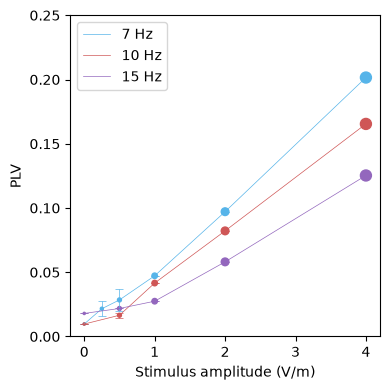

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))
for freq, merged in fig3.merged.items():
    plot_metric_vs_amplitude(ax, merged, get_baseline(fig3.baseline, "abs_plv", freq), fig3.colors[freq],
                             z_col="abs_plv", label=f"{freq} Hz", ylim=(0, 0.25))
ax.set(xlabel="Stimulus amplitude (V/m)", ylabel="PLV")
fig.tight_layout()
ax.legend()
fig.savefig(FIG_DIR / "entrainmentPLV.svg", dpi=300, bbox_inches="tight")

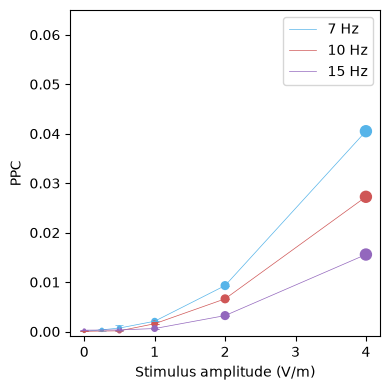

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))
for freq, merged in fig3.merged.items():
    plot_metric_vs_amplitude(ax, merged, get_baseline(fig3.baseline, "ppc", freq), fig3.colors[freq],
                             z_col="ppc", label=f"{freq} Hz", ylim=(-0.001, 0.065))
ax.set(xlabel="Stimulus amplitude (V/m)", ylabel="PPC")
fig.tight_layout()
ax.legend()
fig.savefig(FIG_DIR / "entrainmentPPC.svg", dpi=300, bbox_inches="tight")

### Figure 3c

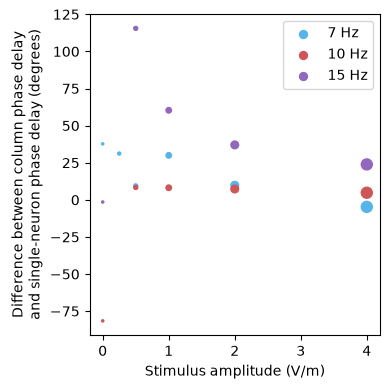

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))
for freq, single_cell_phase in {7: -31, 10: -36, 15: -44}.items():
    z = np.r_[get_baseline(fig3.baseline, "complex", freq), fig3.merged[freq]["complex"].to_numpy()]
    ax.scatter(np.r_[0, fig3.merged[freq]["stim_amp"]], (np.degrees(np.angle(z)) - single_cell_phase + 180) % 360 - 180,
               color=fig3.colors[freq], label=f"{freq} Hz", s=marker_sizes(np.r_[0, fig3.merged[freq]["stim_amp"]]))
ax.set(xlabel="Stimulus amplitude (V/m)",
       ylabel="Difference between column phase delay\nand single-neuron phase delay (degrees)")
# ax.set_ylim(0, 360)
# ax.set_yticks([0, 90, 180, 270, 360])
# ax.set_yticklabels([0, 90, 180, 270, 360])
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "entrainmentAngles.svg", dpi=600)

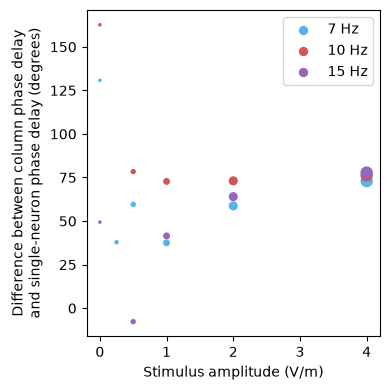

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))
for freq, single_cell_phase in {7: -31, 10: -36, 15: -44}.items():
    z = np.r_[get_baseline(fig3.baseline, "plv", freq), fig3.merged[freq]["plv"].to_numpy()]
    ax.scatter(np.r_[0, fig3.merged[freq]["stim_amp"]], (np.degrees(np.angle(z)) - single_cell_phase + 180) % 360 - 180,
               color=fig3.colors[freq], label=f"{freq} Hz", s=marker_sizes(np.r_[0, fig3.merged[freq]["stim_amp"]]))
ax.set(xlabel="Stimulus amplitude (V/m)",
       ylabel="Difference between column phase delay\nand single-neuron phase delay (degrees)")
# ax.set_ylim(0, 360)
# ax.set_yticks([0, 90, 180, 270, 360])
# ax.set_yticklabels([0, 90, 180, 270, 360])
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "entrainmentAngles_PLV.svg", dpi=600)

### Figure 3d (also Figure S2e) and Figure S2 f-g

Per-cell-type entrainment. Each panel is `(freq, metric, ylim)`; `metric` sets the scatter points, the mean lines and the baseline together (`"plv"`, `"amplitude_norm"` or `"power_norm"`).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from src.plotting import AMPLITUDE_MARKER_AREAS, marker_sizes


def amplitude_size_legend(ax=None, color="0.45",
                          title="Amplitude (V/m)", baseline_label="baseline",
                          loc="upper center", fontsize=7, frameon=False, figsize=(4.6, 0.8),
                          columnspacing=1.4, **legend_kwargs):
    """Horizontal legend of grey dots growing with stimulation amplitude, 0 (baseline) to 4 V/m.

    Sizes use the shared amplitude marker areas from Figure 4b, exactly like all amplitude plots.
    With ``ax`` the legend is added to that axes and returned; without, a small standalone
    figure containing only the key is created and returned.
    """
    amplitudes = np.asarray(sorted(AMPLITUDE_MARKER_AREAS), dtype=float)
    areas = marker_sizes(amplitudes)
    handles = [
        Line2D([], [], linestyle="None", marker="o", color=color,
               # scatter takes an area in points squared, Line2D a diameter in points
               markersize=float(np.sqrt(area)),
               label=baseline_label if (amplitude == 0 and baseline_label) else f"{amplitude:g}")
        for amplitude, area in zip(amplitudes, areas)
    ]
    options = dict(handles=handles, title=title, ncol=len(handles), fontsize=fontsize,
                   title_fontsize=fontsize, frameon=frameon, columnspacing=columnspacing,
                   handletextpad=0.4, **legend_kwargs)
    if ax is None:
        figure, ax = plt.subplots(figsize=figsize)
        ax.axis("off")
        ax.legend(loc="center", **options)
        plt.savefig("amplitude_size_legend.svg", dpi=300, bbox_inches="tight")
        return figure
    legend = ax.legend(loc=loc, **options)
    ax.add_artist(legend)
    return legend

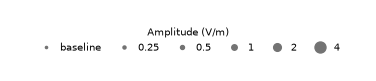

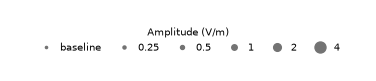

In [ ]:
amplitude_size_legend()       

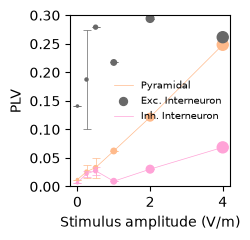

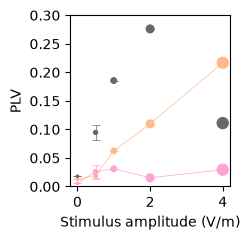

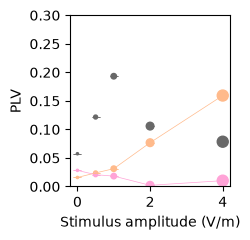

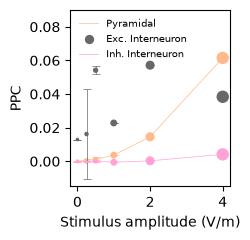

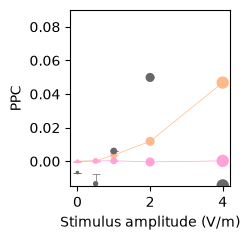

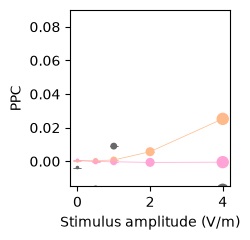

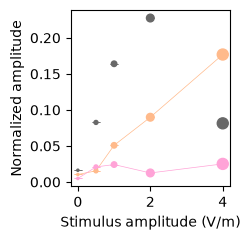

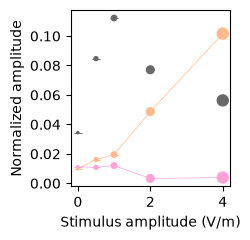

In [ ]:
for freq, metric, ylim in [(7, "plv", (0, 0.3)), (10, "plv", (0, 0.3)), (15, "plv", (0, 0.3)), (7, "ppc", (-0.015,0.09)), (10, "ppc", (-0.015,0.09)), (15, "ppc", (-0.015,0.09)),   # 3d / S2e
                           (10, "amplitude_norm", None), (15, "amplitude_norm", None)]:       # S2 f-g
    # The stored plv is a complex vector; these panels show its magnitude.
    column_metric = "abs_plv" if metric == "plv" else metric
    fig, ax = plt.subplots(figsize=(2.5, 2.5))
    for cell_type in CELL_TYPES:
        plot_metric_vs_amplitude(ax, fig3.merged[freq], get_baseline(fig3.baseline, column_metric, freq, cell_type),
                                 CELL_COLORS["low"][cell_type], z_col=f"{column_metric}_{cell_type}",
                                 label=CELL_LABELS[cell_type], mean_line=cell_type != "INT_EXC", linewidth=0.5)
    ax.set(xlabel="Stimulus amplitude (V/m)", ylabel={metric: "PLV" if metric == "plv" else "PPC" if metric == "ppc" else "Normalized amplitude" if metric == "amplitude_norm" else "Normalized power"}[metric], ylim=ylim)
    if freq == 7:
        ax.legend(frameon=False,fontsize=7)
    fig.tight_layout()

    fig.savefig(FIG_DIR / f"entrainmentCellType_{freq}Hz_{metric}.svg", dpi=600)

### Phase-distribution statistics

Baseline-vs-simulation Moore tests are reported directly below the corresponding rose histograms in Figures S2--S4.

In [ ]:
# See the rose-histogram sections below for the paired baseline Moore tests.

### Exploratory: linear fits vs amplitude (all seeds)

In [ ]:
pd.DataFrame([
    dict(stim_freq=freq, feature=column, **stats.linregress(runs["stim_amp"], runs[column])._asdict())
    for freq, runs in [(f, rows_at(fig3.runs, freq=f)) for f in fig3.freqs] + [("all", fig3.runs)]
    for column in ("abs_plv", "amplitude_norm", "abs_plv_PYR", "abs_plv_INT_INH", "abs_plv_INT_EXC")
]).assign(r_squared=lambda table: table["rvalue"] ** 2)

,stim_freq,feature,slope,intercept,rvalue,pvalue,stderr,intercept_stderr,r_squared
0,7,abs_plv,0.048009,0.005137,0.993489,7.800586e-09,0.001946,0.002948,0.987021
1,7,amplitude_norm,0.043364,0.004593,0.993779,6.503140e-09,0.001718,0.002602,0.987597
2,7,abs_plv_PYR,0.059635,0.006062,0.988782,6.834614e-08,0.003185,0.004824,0.977691
3,7,abs_plv_INT_INH,0.011062,0.015404,0.765204,9.904475e-03,0.003290,0.004983,0.585537
4,7,abs_plv_INT_EXC,0.014379,0.224320,0.281549,4.306552e-01,0.017326,0.026240,0.079270
5,10,abs_plv,0.042369,-0.003331,0.999508,1.311396e-05,0.000768,0.001592,0.999016
6,10,amplitude_norm,0.034566,-0.002860,0.999201,2.711292e-05,0.000798,0.001655,0.998402
7,10,abs_plv_PYR,0.055636,-0.003492,0.996182,2.830296e-04,0.002815,0.005837,0.992379
8,10,abs_plv_INT_INH,0.000075,0.025511,0.013128,9.832852e-01,0.003299,0.006842,0.000172
9,10,abs_plv_INT_EXC,0.006596,0.141879,0.123110,8.436488e-01,0.030699,0.063659,0.015156


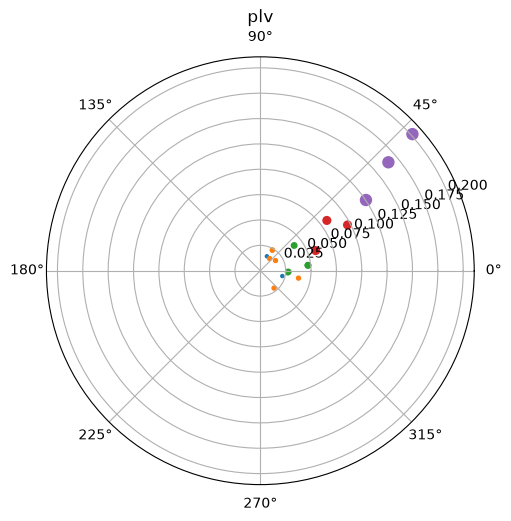

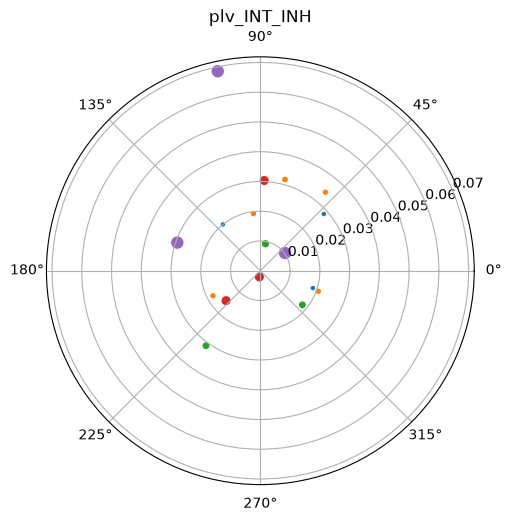

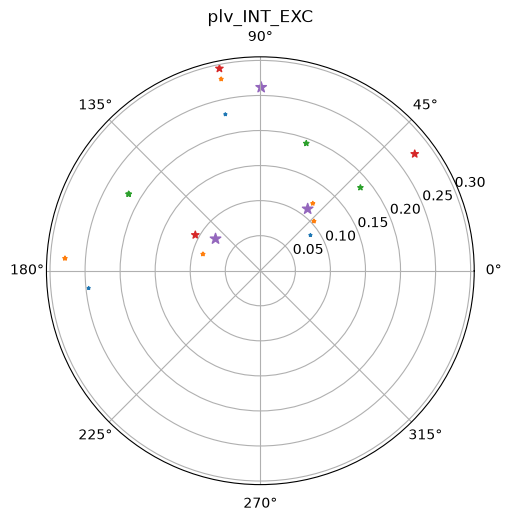

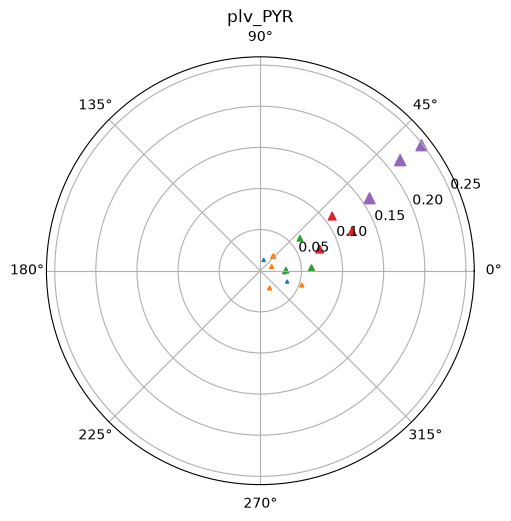

In [ ]:
for z_col, marker in (("plv", "o"), ("plv_INT_INH", "o"), ("plv_INT_EXC", "*"), ("plv_PYR", "^")):
    fig, ax = plt.subplots(figsize=(5, 8), subplot_kw={"projection": "polar"}, layout="constrained")
    ax.scatter(np.angle(fig3.runs[z_col]), np.abs(fig3.runs[z_col]), marker=marker,
               s=marker_sizes(fig3.runs["stim_amp"]),
               color=[f"C{AMPS.index(amp)}" for amp in fig3.runs["stim_amp"]])
    ax.set_title(z_col)

# Figure 4: network state (low vs high correlation)

In [ ]:
assert "SETUP_DONE" in globals(), "Run the Setup section at the top of the notebook first."
fig4 = SimpleNamespace(
    freqs=FREQS["high"],
    runs={state: select_simulations(simulations, **SELECT[state], freqs=FREQS["high"], amps=AMPS) for state in STATES},
    baseline={state: sim_row(simulations, BASELINE_ID[state]) for state in STATES},
)

In [ ]:
fig4.merged_high = {freq: merge_and_average(rows_at(fig4.runs['high'], freq=freq)) for freq in fig4.freqs}

### Figure 4a

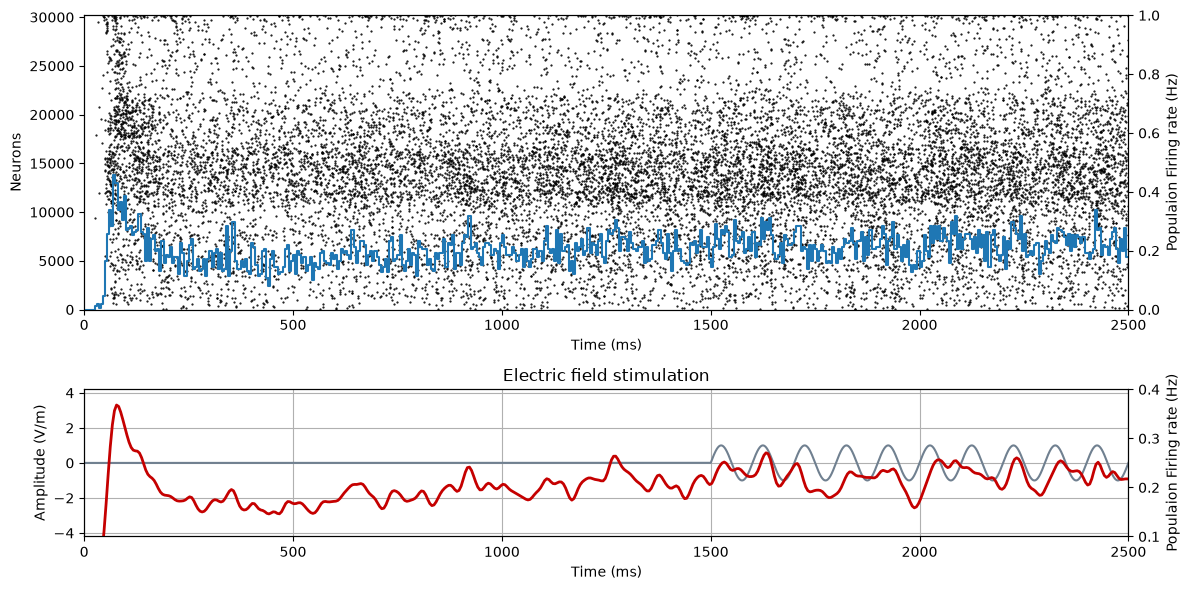

In [ ]:
fig4.psth = load_simulation(sim_row(simulations, "10Hz1Vm")["source_file"].iloc[0])
psth_plot(fig4.psth.spikes, "all cells", fig4.psth.cell_to_rank, fig4.psth.simulation, bin_width=5, smoothed=True,
          figsize=(12, 6), save_histogram=FIG_DIR / "psth_highCorrelation_10Hz4Vm_5bin_smoothed10_intro_plot.svg");

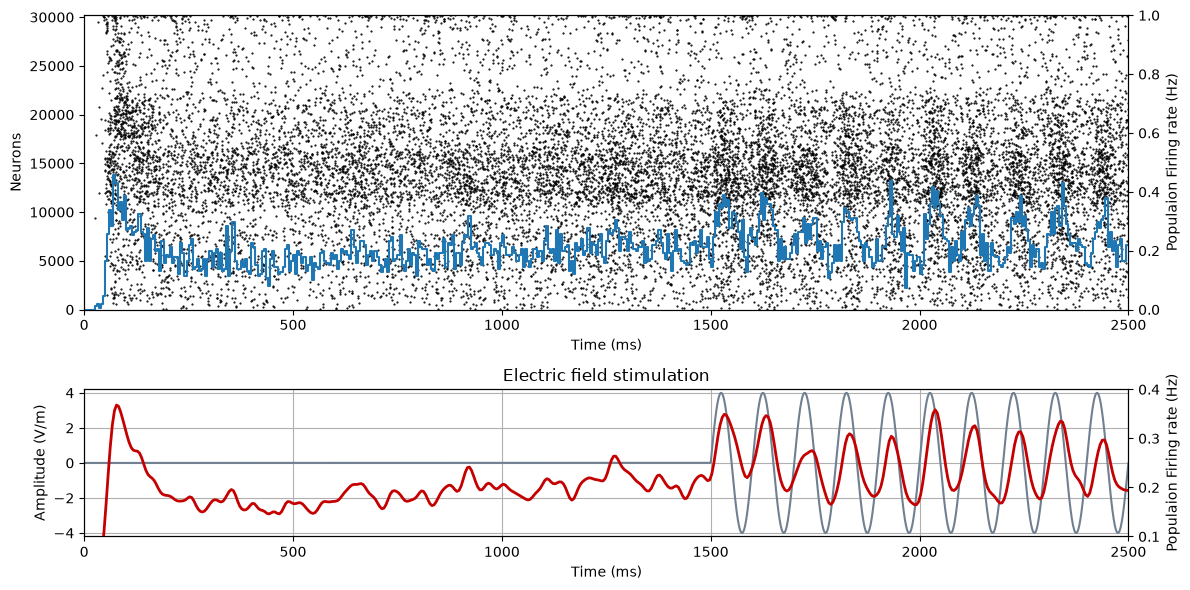

In [ ]:
fig4.psth = load_simulation(sim_row(simulations, "10Hz4Vm")["source_file"].iloc[0])
psth_plot(fig4.psth.spikes, "all cells", fig4.psth.cell_to_rank, fig4.psth.simulation, bin_width=5, smoothed=True,
          figsize=(12, 6), save_histogram=FIG_DIR / "psth_highCorrelation_10Hz4Vm_5bin_smoothed10_intro_plot.svg");

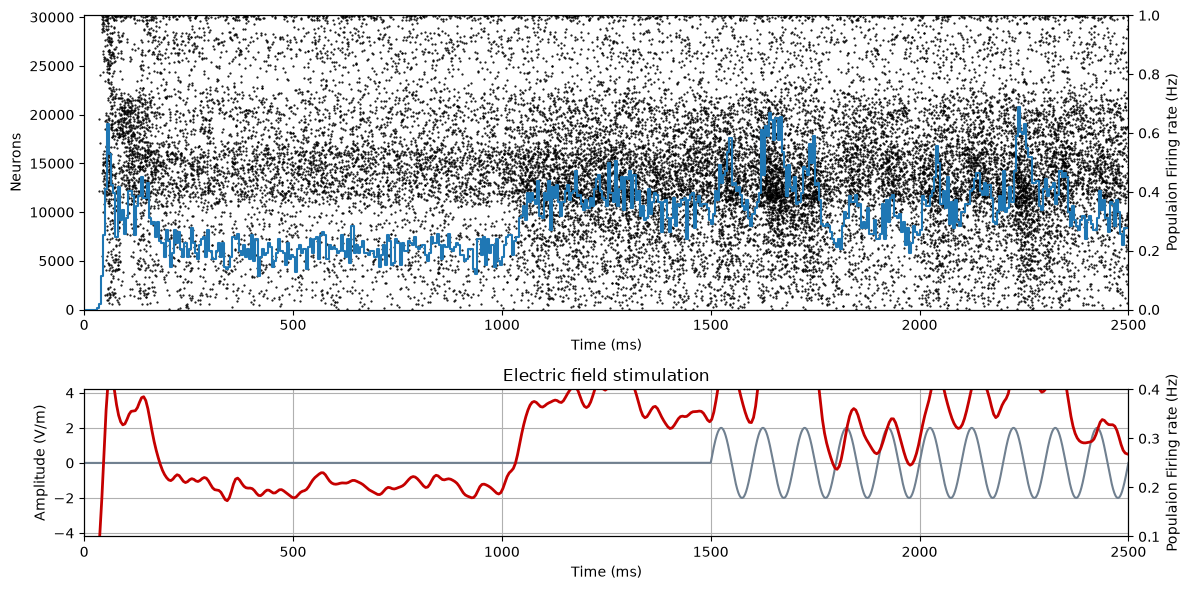

In [ ]:
fig4.psth = load_simulation(sim_row(simulations, "highCorrelation_10Hz2Vm")["source_file"].iloc[0])
psth_plot(fig4.psth.spikes, "all cells", fig4.psth.cell_to_rank, fig4.psth.simulation, bin_width=5, smoothed=True,
          figsize=(12, 6), save_histogram=FIG_DIR / "psth_highCorrelation_10Hz2Vm_5bin_smoothed10.svg");

### Figure 4b

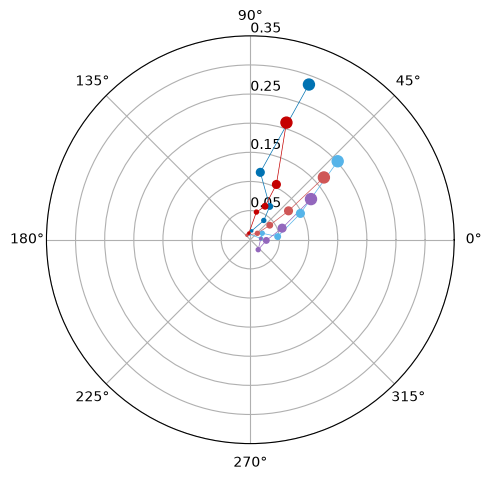

In [ ]:
from turtle import color


fig, ax = plt.subplots(figsize=(4*1.2, 4*1.2), subplot_kw={"projection": "polar"}, layout="constrained")
for state in STATES:
    for freq in fig4.freqs:
        polar_scatter(ax, rows_at(fig4.runs[state], freq=freq), get_baseline(fig4.baseline[state], "plv", freq),
                      FREQ_COLORS[state][freq], f"{STATE_LABELS[state]} network state, {freq} Hz",
                      z_col="plv", means=True,  rlim=(0, 0.35), rlabel_position=90, linewidth=0.5)
    if state == "low":
        polar_scatter(ax, merged, get_baseline(fig3.baseline, "plv", 15), z_col="plv", color=fig3.colors[15], means=True, linewidth=0.5)

fig.savefig(FIG_DIR / "brainstatePolar.svg", dpi=600)

Processing low correlation for freq 7
Single cell phase for freq 7: -31
Low correlation z values for freq 7: [-6.71722253 -0.20154405 21.57150041  1.04797397 21.18679294 35.73136154]
Processing high correlation for freq 7
High correlation z values for freq 7: [-98.38122228  47.46989078  53.71104489  75.13391181  63.11269488]
Processing low correlation for freq 10
Single cell phase for freq 10: -36
Low correlation z values for freq 10: [117.53732222  27.66428072  27.84599088  28.68497863  31.21172987]
Processing high correlation for freq 10
High correlation z values for freq 10: [95.20156242 68.31266134 56.55876216 55.50549067 63.75025463]
Processing low correlation for freq 15
Single cell phase for freq 15: -44
Low correlation z values for freq 15: [ 45.46365261 -71.51161716 -16.32770753   6.99516861  20.13436732]


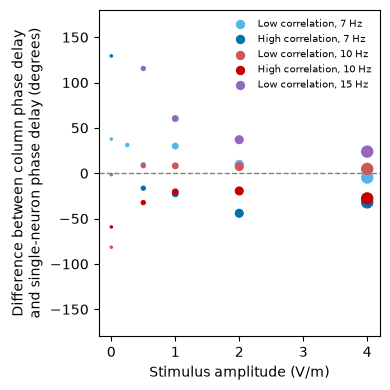

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))
for freq, single_cell_phase in {7: -31, 10: -36, 15: -44}.items():
       print(f"Processing low correlation for freq {freq}")
       print(f"Single cell phase for freq {freq}: {single_cell_phase}")

       z = np.r_[get_baseline(fig3.baseline, "complex", freq), fig3.merged[freq]["complex"].to_numpy()]
       angle = np.degrees(np.angle(z))*-1
       print(f"Low correlation z values for freq {freq}: {angle}")
       ax.scatter(np.r_[0, fig3.merged[freq]["stim_amp"]], (np.degrees(np.angle(z)) - single_cell_phase + 180) % 360 - 180,
               color=fig3.colors[freq], label=f"Low correlation, {freq} Hz", s=marker_sizes(np.r_[0, fig3.merged[freq]["stim_amp"]]))
       if freq in [7, 10]:
              z = np.r_[get_baseline(fig4.baseline["high"], "complex", freq), fig4.merged_high[freq]["complex"].to_numpy()]
              print(f"Processing high correlation for freq {freq}")
              angle = np.degrees(np.angle(z))*-1
              print(f"High correlation z values for freq {freq}: {angle}")
              ax.scatter(np.r_[0, fig4.merged_high[freq]["stim_amp"]], (np.degrees(np.angle(z)) - single_cell_phase + 180) % 360 - 180,
                     facecolors=FREQ_COLORS["high"][freq], edgecolors=FREQ_COLORS["high"][freq], label=f"High correlation, {freq} Hz", s=marker_sizes(np.r_[0, fig4.merged_high[freq]["stim_amp"]]))
ax.set(xlabel="Stimulus amplitude (V/m)",
       ylabel="Difference between column phase delay\nand single-neuron phase delay (degrees)")
ax.set_ylim(-180, 180)
# ax.set_yticks([0, 90, 180, 270, 360])
# ax.set_yticklabels([0, 90, 180, 270, 360])
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.legend(frameon=False, fontsize=7, loc="best")
fig.tight_layout()
fig.savefig(FIG_DIR / "entrainmentAngles_all.svg", dpi=600)

Processing low correlation for freq 7
Single cell phase for freq 7: 31
Low correlation z values for freq 7: [99.77580433  6.86451533 28.55620131  6.50075879 27.71853307 41.92777265]
Processing high correlation for freq 7
High correlation z values for freq 7: [81.37691881 55.09432536 59.75926082 81.58683272 69.31311793]
Processing low correlation for freq 10
Single cell phase for freq 10: 36
Low correlation z values for freq 10: [126.60402981  42.39426565  36.76174389  37.09423463  40.25554464]
Processing high correlation for freq 10
High correlation z values for freq 10: [102.23613268  77.65654386  66.29556331  64.77265887  72.86656238]
Processing low correlation for freq 15
Single cell phase for freq 15: 44
Low correlation z values for freq 15: [  5.41600282 -51.72722848  -2.50653205  20.00558834  33.8014314 ]


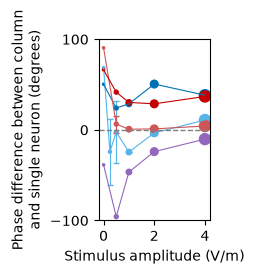

In [ ]:
fig, ax = plt.subplots(figsize=(2.3, 2.6))

def phase_error_by_amplitude(runs, freq, amplitudes):
       """Circular SD across seed phases in degrees; no estimate for <2 seeds."""
       phase_sd = rows_at(runs, freq=freq).groupby("stim_amp")["plv"].agg(
              lambda values: np.degrees(stats.circstd(np.angle(values.to_numpy())))
              if len(values) > 1 else np.nan
       )
       return np.r_[np.nan, phase_sd.reindex(amplitudes).to_numpy()]


for freq, single_cell_phase in {7: 31, 10: 36, 15: 44}.items():
       print(f"Processing low correlation for freq {freq}")
       print(f"Single cell phase for freq {freq}: {single_cell_phase}")

       amps = np.r_[0, fig3.merged[freq]["stim_amp"]]
       z = np.r_[get_baseline(fig3.baseline, "plv", freq), fig3.merged[freq]["plv"].to_numpy()]
       angle = np.degrees(np.angle(z))
       print(f"Low correlation z values for freq {freq}: {angle}")
       phase_difference = (angle - single_cell_phase + 180) % 360 - 180
       phase_sd = phase_error_by_amplitude(fig3.runs, freq, amps[1:])
       ax.errorbar(amps, phase_difference, yerr=phase_sd, 
                   color=fig3.colors[freq], linewidth=0.8, elinewidth=0.8,
                   capsize=2, zorder=1)
       ax.scatter(amps, (np.degrees(np.angle(z)) - single_cell_phase + 180) % 360 - 180,
               color=fig3.colors[freq], label=f"Low correlation, {freq} Hz",
               s=marker_sizes(amps))
       if freq in [7, 10]:
              amps_high = np.r_[0, fig4.merged_high[freq]["stim_amp"]]
              z = np.r_[get_baseline(fig4.baseline["high"], "plv", freq), fig4.merged_high[freq]["plv"].to_numpy()]
              print(f"Processing high correlation for freq {freq}")
              angle = np.degrees(np.angle(z))
              print(f"High correlation z values for freq {freq}: {angle}")
              phase_difference = (angle - single_cell_phase + 180) % 360 - 180
              phase_sd = phase_error_by_amplitude(fig4.runs["high"], freq, amps_high[1:])
              ax.errorbar(amps_high, phase_difference, yerr=phase_sd,
                          color=FREQ_COLORS["high"][freq], linewidth=0.8, elinewidth=0.8,
                          capsize=2, zorder=1)
              ax.scatter(amps_high, (np.degrees(np.angle(z)) - single_cell_phase + 180) % 360 - 180,
                     color=FREQ_COLORS["high"][freq], label=f"High correlation, {freq} Hz",
                     s=marker_sizes(amps_high))
ax.set(xlabel="Stimulus amplitude (V/m)",
       ylabel="Phase difference between column\nand single neuron (degrees)")
ax.set_ylim(-100, 100)
ax.set_yticks([-100, 0, 100])
ax.set_xticks([0,2,4])
# ax.set_yticklabels([0, 90, 180, 270, 360])
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
# ax.legend(frameon=False, fontsize=7, loc="best")
fig.tight_layout()
fig.savefig(FIG_DIR / "entrainmentAngles_allPLV.svg", dpi=600)

### Figure 4c

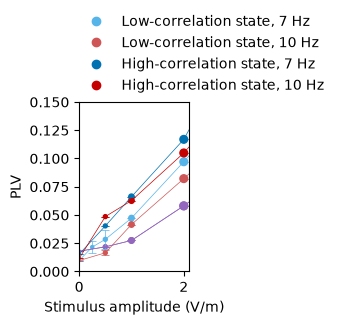

In [ ]:
fig, ax = plt.subplots(figsize=(2, 3))
for state in STATES:
    for freq in fig4.freqs:
        plot_metric_vs_amplitude(ax, rows_at(fig4.runs[state], freq=freq), get_baseline(fig4.baseline[state], "abs_plv", freq),
                                 FREQ_COLORS[state][freq], z_col="abs_plv", ylim=(0, 0.15), xlim=(0, 2.1))
        if state == "low":
                plot_metric_vs_amplitude(ax, merged, get_baseline(fig3.baseline, "abs_plv", 15), fig3.colors[15],
                                         z_col="abs_plv", label=f"15 Hz", ylim=(-0.001, 0.065),linewidth=0.5)
ax.set(xlabel="Stimulus amplitude (V/m)", ylabel="PLV")
fig.tight_layout()
ax.legend(handles=[Line2D([], [], marker="o", linestyle="None", color=FREQ_COLORS[state][freq],
                          label=f"{STATE_LABELS[state]} state, {freq} Hz", markerfacecolor=FREQ_COLORS[state][freq]) for state in STATES for freq in fig4.freqs],
          loc="lower left", bbox_to_anchor=(-0.02, 1.02), frameon=False, borderaxespad=0)
fig.subplots_adjust(top=0.76)
fig.savefig(FIG_DIR / "brainStatePLV.svg", dpi=300, bbox_inches="tight")

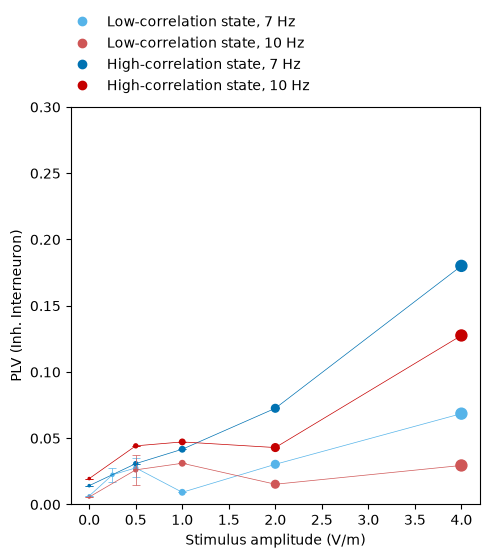

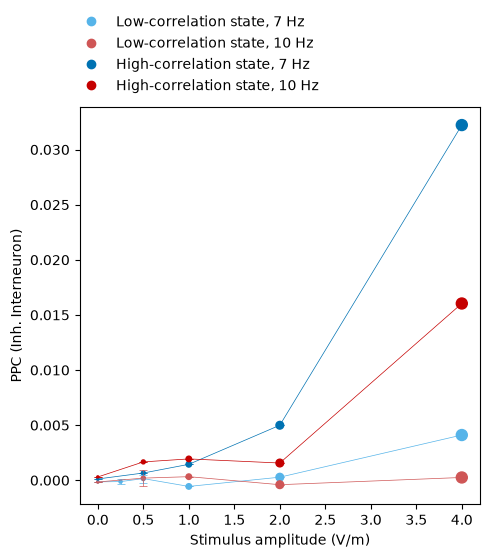

In [ ]:
# One cell type across every network state and stimulation frequency.
# Switch cell_type to "PYR" or "INT_EXC" for the other groups.
cell_type = "INT_INH"
for metric, metric_label, ylim in (("abs_plv", "PLV", (0, 0.3)), ("ppc", "PPC", None)):
    fig, ax = plt.subplots(figsize=(5, 6))
    for state in STATES:
        for freq in fig4.freqs:
            plot_metric_vs_amplitude(
                ax, rows_at(fig4.runs[state], freq=freq),
                get_baseline(fig4.baseline[state], metric, freq, cell_type=cell_type),
                FREQ_COLORS[state][freq], z_col=f"{metric}_{cell_type}", ylim=ylim,
            )
    ax.set(xlabel="Stimulus amplitude (V/m)", ylabel=f"{metric_label} ({CELL_LABELS[cell_type]})")
    fig.tight_layout()
    ax.legend(handles=[Line2D([], [], marker="o", linestyle="None", color=FREQ_COLORS[state][freq],
                              label=f"{STATE_LABELS[state]} state, {freq} Hz", markerfacecolor=FREQ_COLORS[state][freq])
                       for state in STATES for freq in fig4.freqs],
              loc="lower left", bbox_to_anchor=(-0.02, 1.02), frameon=False, borderaxespad=0)
    fig.subplots_adjust(top=0.76)
    fig.savefig(FIG_DIR / f"brainState{metric_label}_{cell_type}.svg", dpi=300, bbox_inches="tight")

In [ ]:
rows_at(fig4.runs['low'], freq=7)

,sim_id,time_import,dt,tstop,seed,simulator,node_set,delay,duration,stim_freq,stim_phase,stim_amp,stim_orientation,stim_rampup,stim_rampdown,analysis_start,analysis_stop,source_file,plv,ppc,deltafr,complex,amplitude_norm,power_norm,total_power,plv_PYR,ppc_PYR,deltafr_PYR,complex_PYR,amplitude_norm_PYR,power_norm_PYR,total_power_PYR,plv_INT_INH,ppc_INT_INH,deltafr_INT_INH,complex_INT_INH,amplitude_norm_INT_INH,power_norm_INT_INH,total_power_INT_INH,plv_INT_EXC,ppc_INT_EXC,deltafr_INT_EXC,complex_INT_EXC,amplitude_norm_INT_EXC,power_norm_INT_EXC,total_power_INT_EXC,deployment,neurodamus,abs_plv,abs_plv_PYR,abs_plv_INT_INH,abs_plv_INT_EXC
0,7Hz0.25Vm,2026-05-13,0.025,2500,843,NEURON,hex0,1500,1000,7,1.570796,0.25,3.1416,0.0,0.0,1500.0,2500.0,data/sim7Hz0.25Vm/sim_with_stim.json,0.021665-0.005263j,0.000348,1.128175,0.789753+0.328243j,0.019249,0.000369,0.049588,0.032602-0.013185j,0.001041,1.153950,1.055956+0.602382j,0.031359,0.000977,0.037808,-0.012568+0.015573j,-0.000241,1.062670,-1.130492-1.321708j,0.018970,0.000354,0.213593,-0.049908+0.223074j,0.024378,0.744681,-0.384156-3.572906j,0.212530,0.030742,0.010501,Mimas,weji,0.022295,0.035167,0.020012,0.228588
1,7Hz0.25Vm_seed2,2026-08-11,0.025,2500,84,NEURON,hex0,1500,1000,7,1.570796,0.25,3.1416,0.0,0.0,1500.0,2500.0,data/sim7Hz0.25Vm_seed2/sim_with_stim.json,0.006475+0.014234j,0.000097,1.119119,0.359684-0.536988j,0.014443,0.000208,0.050265,0.004028+0.013089j,-0.000007,1.131781,0.230708-0.439230j,0.012696,0.000160,0.038414,0.021325+0.019067j,0.000177,1.072165,1.953357-1.351048j,0.025905,0.000665,0.212027,-0.244917-0.024830j,0.037689,1.500000,-4.523856-0.073081j,0.222991,0.034545,0.014815,Mimas,weji,0.015638,0.013695,0.028606,0.246172
2,7Hz0.25Vm_seed3,2026-08-11,0.025,2500,8,NEURON,hex0,1500,1000,7,1.570796,0.25,3.1416,0.0,0.0,1500.0,2500.0,data/sim7Hz0.25Vm_seed3/sim_with_stim.json,0.026865-0.002349j,0.000578,1.116991,1.086707+0.216611j,0.024920,0.000619,0.049589,0.029249-0.001788j,0.000663,1.128064,1.037097+0.161712j,0.027091,0.000731,0.037679,0.017656-0.005833j,-0.000298,1.073895,1.431326+0.753840j,0.017701,0.000311,0.210276,0.071447+0.050771j,-0.013431,1.500000,1.414321-0.702077j,0.068094,0.003724,0.016737,Mimas,weji,0.026968,0.029304,0.018595,0.087649
3,7Hz0.5Vm,2026-05-13,0.025,2500,843,NEURON,hex0,1500,1000,7,1.570796,0.50,3.1416,0.0,0.0,1500.0,2500.0,data/sim7Hz0.5Vm/sim_with_stim.json,0.037599-0.007281j,0.001318,1.131034,1.419292+0.456614j,0.033471,0.001114,0.049878,0.050414-0.017314j,0.002647,1.157336,1.663922+0.811959j,0.047619,0.002251,0.038070,-0.002336+0.019199j,-0.000267,1.063351,-0.246752-1.698937j,0.018713,0.000344,0.213896,-0.055854+0.273395j,0.051518,0.765957,-0.469783-4.461682j,0.257965,0.044575,0.011288,Mimas,weji,0.038298,0.053304,0.019340,0.279042
4,7Hz0.5Vm_seed2,2026-08-11,0.025,2500,84,NEURON,hex0,1500,1000,7,1.570796,0.50,3.1416,0.0,0.0,1500.0,2500.0,data/sim7Hz0.5Vm_seed2/sim_with_stim.json,0.011869+0.020331j,0.000407,1.122432,0.647827-0.764988j,0.022335,0.000497,0.050563,0.015279+0.017280j,0.000339,1.139908,0.670743-0.542025j,0.021911,0.000477,0.038941,0.008308+0.030665j,0.000362,1.060481,1.141196-2.440985j,0.029714,0.000873,0.207895,-0.278704+0.017751j,0.055503,1.500000,-4.867439-1.191990j,0.246984,0.041369,0.015176,Mimas,weji,0.023542,0.023066,0.031771,0.279269
5,7Hz0.5Vm_seed3,2026-08-11,0.025,2500,8,NEURON,hex0,1500,1000,7,1.570796,0.50,3.1416,0.0,0.0,1500.0,2500.0,data/sim7Hz0.5Vm_seed3/sim_with_stim.json,0.011869+0.020331j,0.000407,1.122432,0.647827-0.764988j,0.022335,0.000497,0.050563,0.015279+0.017280j,0.000339,1.139908,0.670743-0.542025j,0.021911,0.000477,0.038941,0.008308+0.030665j,0.000362,1.060481,1.141196-2.440985j,0.029714,0.000873,0.207895,-0.278704+0.017751j,0.055503,1.500000,-4.867439-1.191990j,0.246984,0.041369,0.015176,Mimas,weji,0.023542,0.023066,0.031771,0.279269
6,7Hz1Vm,2026-05-13,0.025,2500,843,NEURON,hex0,1500,1000,7,1.570796,1.00,3.1416,0.0,0.0,1500.0,2500.0,data/sim7Hz1Vm/sim_with_stim.json,0.046949+0.005350j,0.002087,1.151556,1.

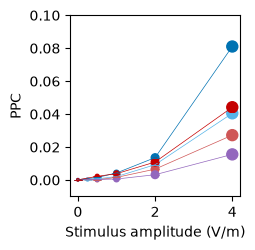

In [ ]:
fig, ax = plt.subplots(figsize=(2.6,2.6))
for state in STATES:
    for freq in fig4.freqs:
        plot_metric_vs_amplitude(ax, rows_at(fig4.runs[state], freq=freq), get_baseline(fig4.baseline[state], "ppc", freq),
                                 FREQ_COLORS[state][freq], z_col="ppc", ylim=(-0.01, 0.1),linewidth=0.5)
    if state == "low":
        plot_metric_vs_amplitude(ax, merged, get_baseline(fig3.baseline, "ppc", 15), fig3.colors[15],
                                 z_col="ppc", label=f"15 Hz", ylim=(-0.001, 0.065),linewidth=0.5)
ax.set(xlabel="Stimulus amplitude (V/m)", ylabel="PPC")
fig.tight_layout()
# ax.legend(handles=[Line2D([], [], marker="o", linestyle="None", color=FREQ_COLORS[state][freq],
                          # label=f"{STATE_LABELS[state]} state, {freq} Hz") for state in STATES for freq in fig4.freqs],
          # loc="lower left", bbox_to_anchor=(-0.02, 1.02), frameon=False, borderaxespad=0)
# fig.subplots_adjust(top=0.76)
fig.savefig(FIG_DIR / "brainStatePPC.svg", dpi=300, bbox_inches="tight")

### Figure 4d (also Figure S3g) and Figure S3e

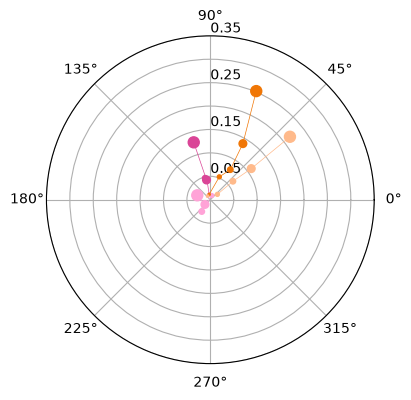

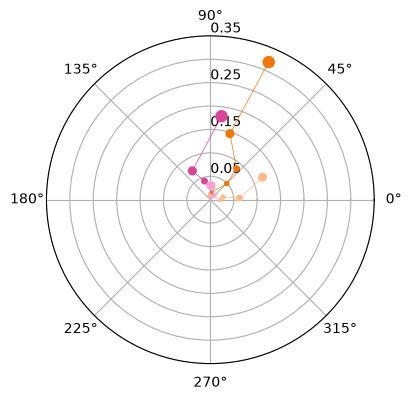

In [ ]:
# The mean lines start from the all-cells baseline (cell_type=None), as in the original notebook.
for freq, low_max_amp in ((10, None), (7, 2)):
    fig, ax = plt.subplots(figsize=(4, 4), subplot_kw={"projection": "polar"}, layout="constrained")
    for cell_type in ("INT_INH", "PYR"):
        for state, max_amp in (("high", None), ("low", low_max_amp)):
            polar_scatter(ax, rows_at(fig4.runs[state], freq=freq), get_baseline(fig4.baseline[state], "plv", freq),
                          CELL_COLORS[state][cell_type], z_col=f"plv_{cell_type}", max_amp=max_amp, means=True, edgecolors="face", rlim=(0, 0.35), rlabel_position=90,linewidth=0.5)
    fig.savefig(FIG_DIR / f"cellTypePolar_{freq}Hz.svg", dpi=600)

### Figure 4e (also Figure S3f and S3h)

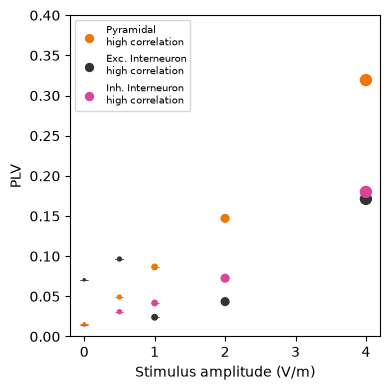

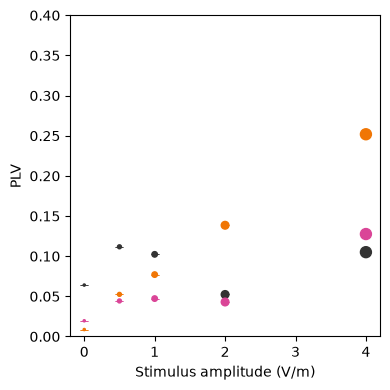

In [ ]:
for freq in fig4.freqs:
    fig, ax = plt.subplots(figsize=(4, 4))
    for cell_type in CELL_TYPES:
        plot_metric_vs_amplitude(ax, rows_at(fig4.runs["high"], freq=freq),
                                 get_baseline(fig4.baseline["high"], "abs_plv", freq, cell_type),
                                 CELL_COLORS["high"][cell_type], z_col=f"abs_plv_{cell_type}", label=CELL_LABELS[cell_type]+'\nhigh correlation', mean_line=None)
    ax.set(xlabel="Stimulus amplitude (V/m)", ylabel="PLV", ylim=(0, 0.4))
    if freq == 7:
        ax.legend(fontsize=7)
    ax.set_ylim(0, 0.4)
    fig.tight_layout()
    # However, sample estimates of PPC can dip slightly below zero due to finite-sample variance, low firing/trial counts
    fig.savefig(FIG_DIR / f"cellTypeHighCorrelation_condition{freq}.svg", dpi=600)

7
10


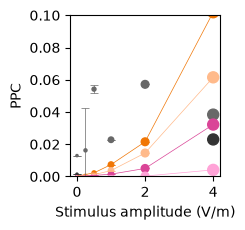

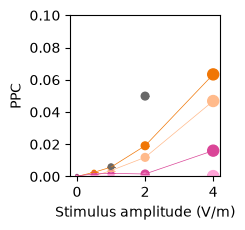

In [ ]:
for freq in fig4.freqs:
    fig, ax = plt.subplots(figsize=(2.4, 2.4))
    print(freq)
    for cell_type in CELL_TYPES:
        plot_metric_vs_amplitude(ax, rows_at(fig4.runs["high"], freq=freq),
                                 get_baseline(fig4.baseline["high"], "ppc", freq, cell_type),
                                 CELL_COLORS["high"][cell_type], z_col=f"ppc_{cell_type}", label=CELL_LABELS[cell_type], mean_line=cell_type != "INT_EXC", ylim=(-0.01, 0.12),linewidth=0.5)
        plot_metric_vs_amplitude(ax, fig3.merged[freq], get_baseline(fig3.baseline, "ppc", freq, cell_type),
                                         CELL_COLORS["low"][cell_type], z_col=f"ppc_{cell_type}",
                                         label=CELL_LABELS[cell_type], mean_line=cell_type != "INT_EXC",linewidth=0.5)
    ax.set(xlabel="Stimulus amplitude (V/m)", ylabel="PPC")
    # if freq == 7:
    #     ax.legend()
    ax.set_ylim(0, 0.1)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"cellTypeHighCorrelation_PPC_condition{freq}_together.svg", dpi=600)

# Cross-frequency PLV by stimulation amplitude

Each panel fixes the **stimulation frequency** and compares population PLV evaluated at every frequency available for that network state. Thus, the three low-correlation panels contain 7, 10 and 15 Hz PLV lines, while the two high-correlation panels contain 7 and 10 Hz PLV lines. Faint points are individual simulations (including seed replicates), and the connected markers are the mean at each amplitude. The 0 V/m point is the corresponding network-state baseline.

PLV is recomputed from the spike times with the same analysis window and timing reference as the stored `plv` feature. The validation below checks that recomputing at the stimulation frequency reproduces that stored value.

In [ ]:
assert "SETUP_DONE" in globals(), "Run the Setup section at the top of the notebook first."

def population_plv_at_frequency(row, evaluation_freq):
    """Population spike PLV at `evaluation_freq`, using the stored-feature timing window."""
    sim = load_simulation(row["source_file"])
    spike_times_ms = sim.spikes.index.to_numpy(dtype=float)
    in_window = (
        (spike_times_ms > float(row["analysis_start"]))
        & (spike_times_ms < float(row["analysis_stop"]))
    )
    if not np.any(in_window):
        return np.nan
    phases = (
        2 * np.pi * evaluation_freq
        * (spike_times_ms[in_window] - float(row["delay"])) * 1e-3
        + float(row["stim_phase"]) + float(row["stim_orientation"])
    )
    return float(np.abs(np.mean(np.exp(1j * phases))))

cross_plv = SimpleNamespace(
    freqs=FREQS,
    colors=FREQ_COLORS,
    runs={
        state: select_simulations(
            simulations, **SELECT[state], freqs=FREQS[state], amps=AMPS
        )
        for state in STATES
    },
    baseline={state: sim_row(simulations, BASELINE_ID[state]) for state in STATES},
)
cross_plv.values = pd.DataFrame.from_records([
    {
        "state": state,
        "sim_id": row["sim_id"],
        "seed": row["seed"],
        "stim_freq": float(row["stim_freq"]),
        "stim_amp": float(row["stim_amp"]),
        "evaluation_freq": float(evaluation_freq),
        "plv": population_plv_at_frequency(row, evaluation_freq),
        "stored_plv": float(np.abs(row["plv"])),  # the stored plv is complex
    }
    for state in STATES
    for _, row in cross_plv.runs[state].iterrows()
    for evaluation_freq in FREQS[state]
])

same_frequency = cross_plv.values[np.isclose(
    cross_plv.values["stim_freq"], cross_plv.values["evaluation_freq"]
)]
assert np.allclose(
    same_frequency["plv"], same_frequency["stored_plv"],
    rtol=1e-9, atol=1e-12, equal_nan=True,
)
cross_plv.values


,state,sim_id,seed,stim_freq,stim_amp,evaluation_freq,plv,stored_plv
0,low,7Hz0.25Vm,843,7.0,0.25,7.0,0.022295,0.022295
1,low,7Hz0.25Vm,843,7.0,0.25,10.0,0.005074,0.022295
2,low,7Hz0.25Vm,843,7.0,0.25,15.0,0.026521,0.022295
3,low,7Hz0.25Vm_seed2,84,7.0,0.25,7.0,0.015638,0.015638
4,low,7Hz0.25Vm_seed2,84,7.0,0.25,10.0,0.000974,0.015638
...,...,...,...,...,...,...,...,...
68,high,10Hz1Vm_highCorrelation,843,10.0,1.00,10.0,0.062728,0.062728
69,high,highCorrelation_10Hz2Vm,843,10.0,2.00,7.0,0.013097,0.104909
70,high,highCorrelation_10Hz2Vm,843,10.0,2.00,10.0,0.104909,0.104909
71,high,highCorrelation_10Hz4Vm,843,10.0,4.00,7.0,0.030892,0.210363


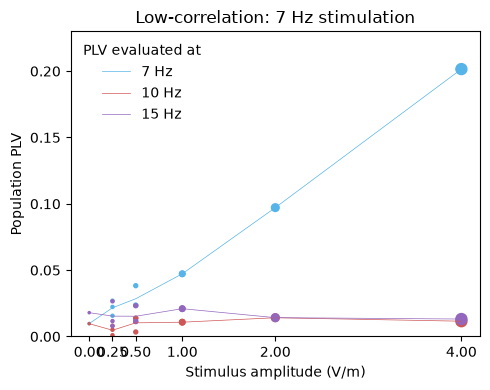

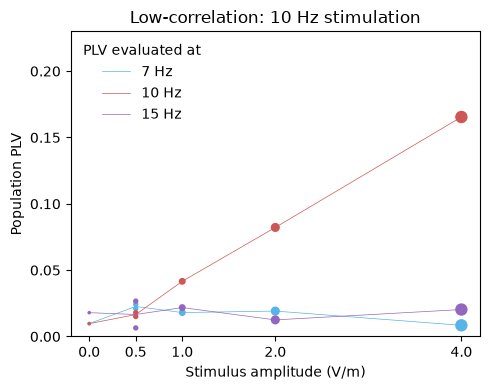

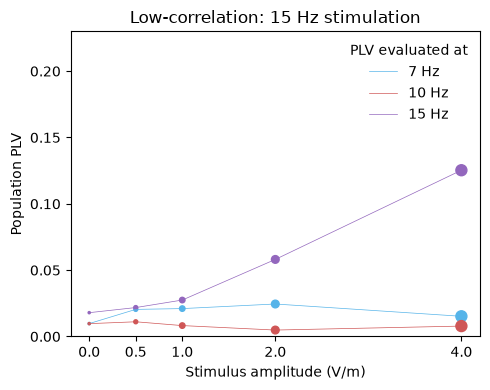

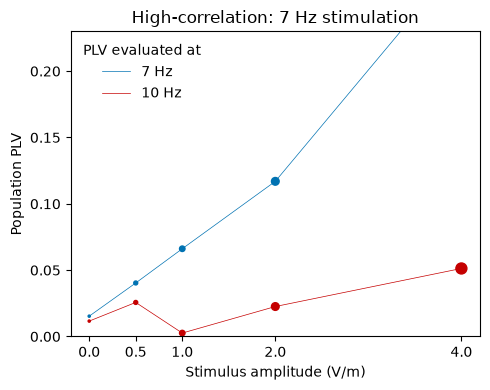

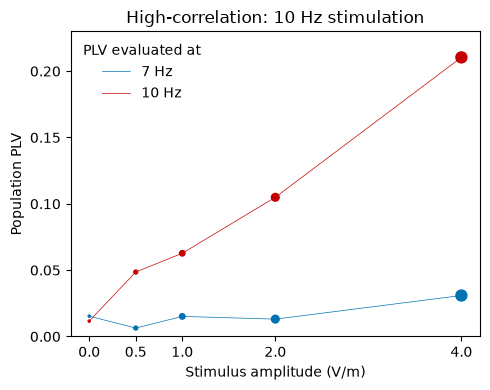

In [ ]:
for state in STATES:
    for stim_freq in FREQS[state]:
        panel = cross_plv.values[
            (cross_plv.values["state"] == state)
            & np.isclose(cross_plv.values["stim_freq"], stim_freq)
        ]
        fig, ax = plt.subplots(figsize=(5, 4))
        for evaluation_freq in FREQS[state]:
            values = panel[np.isclose(panel["evaluation_freq"], evaluation_freq)]
            color = cross_plv.colors[state][evaluation_freq]
            means = values.groupby("stim_amp", sort=True)["plv"].mean()
            baseline = get_baseline(
                cross_plv.baseline[state], "abs_plv", evaluation_freq
            )

            # Individual simulations remain visible; the line is the seed mean at each amplitude.
            point_amps = np.r_[0.0, values["stim_amp"].to_numpy(float)]
            point_plvs = np.r_[baseline, values["plv"].to_numpy(float)]
            ax.scatter(
                point_amps, point_plvs, s=marker_sizes(point_amps),
                color=color,
            )
            ax.plot(
                np.r_[0.0, means.index.to_numpy(float)],
                np.r_[baseline, means.to_numpy(float)],
                color=color, linewidth=0.5,
                label=f"{evaluation_freq:g} Hz",
            )

        amplitudes = sorted(panel["stim_amp"].unique())
        ax.set(
            title=f"{STATE_LABELS[state]}: {stim_freq:g} Hz stimulation",
            xlabel="Stimulus amplitude (V/m)",
            ylabel="Population PLV",
            xticks=[0, *amplitudes],
        )
        ax.set_ylim(bottom=0, top=0.23)
        ax.legend(title="PLV evaluated at", frameon=False)
        fig.tight_layout()
        fig.savefig(
            FIG_DIR / f"crossFrequencyPLV_{state}_{stim_freq:g}HzStim.jpg",
            dpi=300, bbox_inches="tight",
        )


# Figure S2: phase preferences of individual neurons, low-correlation circuit

`figS2.grids[cell_type][i][j]` holds one preferred phase per active cell for `figS2.freqs[i]` and `AMP_LABELS[j]` (column 0 is the baseline).

In [ ]:
assert "SETUP_DONE" in globals(), "Run the Setup section at the top of the notebook first."
figS2 = SimpleNamespace(
    freqs=FREQS["low"],
    runs=select_simulations(simulations, **SELECT["low"], freqs=FREQS["low"], amps=AMPS),
    baseline=sim_row(simulations, BASELINE_ID["low"]),
)
figS2.grids = {cell_type: cell_phase_grid(figS2.runs, figS2.baseline, figS2.freqs, AMPS, cell_type, min_spikes=MIN_SPIKES_PER_CELL)
               for cell_type in ("ALL", "PYR", "INT_INH", "INT_EXC")}
figS2.row_labels = [f"{freq} Hz" for freq in figS2.freqs]

### Figure S2a: all cells

angle=1.686 (96.6°)
plv=0.013
angle=0.251 (14.4°)
plv=0.023
angle=0.459 (26.3°)
plv=0.029
angle=0.013 (0.8°)
plv=0.055
angle=0.457 (26.2°)
plv=0.120
angle=0.710 (40.7°)
plv=0.233
angle=2.785 (159.6°)
plv=0.014
angle=0.302 (17.3°)
plv=0.021
angle=0.586 (33.6°)
plv=0.054
angle=0.635 (36.4°)
plv=0.108
angle=0.680 (38.9°)
plv=0.200
angle=0.030 (1.7°)
plv=0.031
angle=-1.151 (-65.9°)
plv=0.027
angle=-0.176 (-10.1°)
plv=0.029
angle=0.267 (15.3°)
plv=0.063
angle=0.576 (33.0°)
plv=0.150


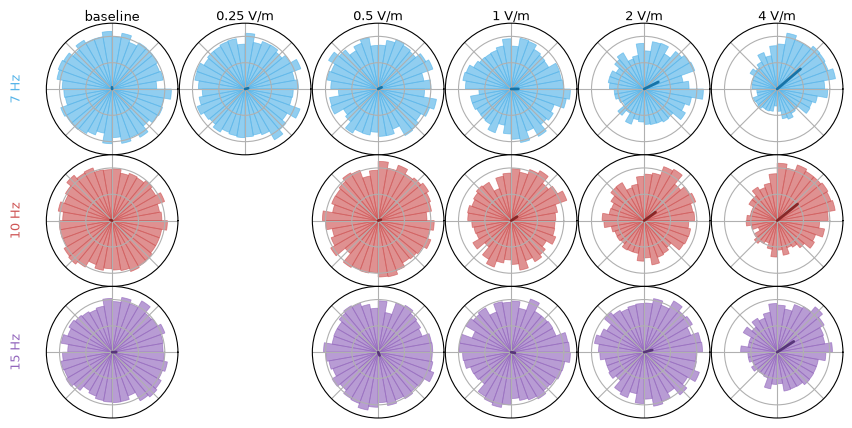

In [ ]:
plot_rose_grid(figS2.grids["ALL"], figS2.row_labels, AMP_LABELS, colors=[FREQ_COLORS["low"][f] for f in figS2.freqs], **ROSE_GRID_KWARGS
               ).savefig(FIG_DIR / "rose_grid.svg", dpi=600, bbox_inches="tight", pad_inches=0)

Paired Moore tests: frequency-matched baseline vs each Figure S2 simulation

In [ ]:
cell_types = ['ALL', 'PYR', 'INT_INH']

In [ ]:
AMPS

(0.25, 0.5, 1, 2, 4)

In [ ]:
# Column 0 is the same unstimulated network evaluated at each row's reference frequency.
# These paired Moore rows replace the former one-sample Kuiper tests for the rose distributions.
figS2.baseline_tests = pd.DataFrame([
    row
    for cell_type, grid in figS2.grids.items()
    if cell_type in ("ALL", "INT_INH")
    for freq, grid_row in zip(figS2.freqs, grid)
    for j, amp in enumerate(AMPS, start=1)
    if len(grid_row[0]) > 1 and len(grid_row[j]) > 1
    for row in cell_phase_contrasts(
        (condition(freq, 0, "low"), grid_row[0]),
        (condition(freq, amp, "low"), grid_row[j]),
        labels={"cell_type": cell_type}, **CELL_TEST_KWARGS,
    )
])
figS2.freq_pair_amp = [2,4]
figS2.freq_pairs = ((7, 10), (7,15))
figS2.freq_pair_cell_types = ("ALL",)   # add "PYR" / "INT_INH" / "INT_EXC" for cell-type versions

figS2.frequency_tests = pd.DataFrame([
    row
    for cell_type in figS2.freq_pair_cell_types
    for freq_a, freq_b in figS2.freq_pairs
    for amp in figS2.freq_pair_amp
    for phases in [{freq: grid_row[AMPS.index(amp) + 1]
                    for freq, grid_row in zip(figS2.freqs, figS2.grids[cell_type])}]
    if len(phases[freq_a]) > 1 and len(phases[freq_b]) > 1
    for row in cell_phase_contrasts(
        (condition(freq_a, amp, "low"), phases[freq_a]),
        (condition(freq_b, amp, "low"), phases[freq_b]),
        labels={"cell_type": cell_type}, **CELL_TEST_KWARGS,
    )
])
# Pyramidal vs inhibitory interneurons: do the two groups change their preferred phases differently?
figS2.cell_type_tests = pd.DataFrame([
    cell_type_contrast(figS2.grids, i, j, freq, amp, "low")
    for i, freq in enumerate(figS2.freqs)
    for j, amp in enumerate(AMPS, start=1)
    if all(len(figS2.grids[group][i][j]) > 1 for group in CELL_TYPE_PAIR)
])
figS2.baseline_tests.to_csv(FIG_DIR / "figS2_baseline_vs_stimulated_phase_tests.csv", index=False)
figS2.frequency_tests.to_csv(FIG_DIR / "figS2_frequency_pair_phase_tests.csv", index=False)
figS2.cell_type_tests.to_csv(FIG_DIR / "figS2_pyr_vs_intinh_phase_change_tests.csv", index=False)
display(figS2.baseline_tests)
display(figS2.frequency_tests)
display(figS2.cell_type_tests)

,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_cells_a,n_cells_b,kuiper_V,kuiper_p,moore_n_pairs,moore_n_moore,moore_R,moore_p_asymptotic,moore_mean_shift_deg,moore_p,moore_method
0,ALL,7,7,0,0.25,True,True,low,low,7079,6597,0.024871,2.143441e-01,5023,5023,1.163127,1.729424e-02,-90.432321,0.01780,randomization (19999 within-cell label swaps)
1,ALL,7,7,0,0.50,True,True,low,low,7079,5517,0.030823,5.797327e-02,4653,4653,0.953698,6.536679e-02,-91.496765,0.06625,randomization (19999 within-cell label swaps)
2,ALL,7,7,0,1.00,True,True,low,low,7079,4063,0.043809,1.770807e-03,3970,3970,1.367926,3.655415e-03,-92.618921,0.00395,randomization (19999 within-cell label swaps)
3,ALL,7,7,0,2.00,True,True,low,low,7079,4126,0.083717,1.562040e-14,3967,3967,2.781782,8.350071e-11,-91.768645,0.00005,randomization (19999 within-cell label swaps)
4,ALL,7,7,0,4.00,True,True,low,low,7079,4546,0.154159,1.708968e-55,4178,4178,5.617432,7.971829e-42,-95.223394,0.00005,randomization (19999 within-cell label swaps)
5,ALL,10,10,0,0.50,True,True,low,low,7079,5980,0.033767,1.639060e-02,4843,4843,1.117339,2.365508e-02,-91.132276,0.02425,randomization (19999 within-cell label swaps)
6,ALL,10,10,0,1.00,True,True,low,low,7079,4016,0.050639,9.190313e-05,3921,3921,1.322048,5.292703e-03,-89.952277,0.00495,randomization (19999 within-cell label swaps)
7,ALL,10,10,0,2.00,True,True,low,low,7079,4121,0.082996,2.961979e-14,3970,3970,2.693481,3.559249e-10,-92.063056,0.00005,randomization (19999 within-cell label swaps)
8,ALL,10,10,0,4.00,True,True,low,low,7079,4426,0.142792,1.327359e-46,4168,4168,4.900271,5.315757e-32,-94.684921,0.00005,randomization (19999 within-cell label swaps)
9,ALL,15,15,0,0.50,True,True,low,low,7079,4011,0.033271,6.936498e-02,3947,3947,0.430714,5.733079e-01,-92.252258,0.56845,randomization (19999 within-cell label swaps)


,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_cells_a,n_cells_b,kuiper_V,kuiper_p,moore_n_pairs,moore_n_moore,moore_R,moore_p_asymptotic,moore_mean_shift_deg,moore_p,moore_method
0,ALL,7,10,2,2,True,True,low,low,4126,4121,0.028428,3.985034e-01,3793,3793,0.419716,0.589621,54.979115,0.59045,randomization (19999 within-cell label swaps)
1,ALL,7,10,4,4,True,True,low,low,4546,4426,0.031149,1.942159e-01,3968,3968,0.587831,0.354784,19.542677,0.35505,randomization (19999 within-cell label swaps)
2,ALL,7,15,2,2,True,True,low,low,4126,4048,0.049035,1.893315e-03,3761,3761,1.198954,0.013423,6.026644,0.01525,randomization (19999 within-cell label swaps)
3,ALL,7,15,4,4,True,True,low,low,4546,4327,0.070635,1.850361e-08,3911,3911,1.844314,0.000037,18.624137,0.00010,randomization (19999 within-cell label swaps)


,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_pairs_a,R_base_a,R_stim_a,change_a,change_deg_a,n_pairs_b,R_base_b,R_stim_b,change_b,change_deg_b,change_difference,wald_chi2,wald_p
0,PYR vs INT_INH,7,7,0.25,0.25,True,True,low,low,4140,0.020393,0.038575,0.037440,-30.228213,838,0.034627,0.041878,0.075825,52.671258,-0.038384,4.381820,1.118150e-01
1,PYR vs INT_INH,7,7,0.50,0.50,True,True,low,low,3807,0.020665,0.043989,0.038552,-21.091923,811,0.035399,0.027407,0.062056,64.394643,-0.023504,3.261596,1.957732e-01
2,PYR vs INT_INH,7,7,1.00,1.00,True,True,low,low,3187,0.032070,0.072560,0.068493,-26.766584,754,0.032868,0.004004,0.029238,61.962327,0.039255,3.192344,2.026708e-01
3,PYR vs INT_INH,7,7,2.00,2.00,True,True,low,low,3194,0.034925,0.139186,0.125623,5.739901,747,0.031912,0.026130,0.053544,76.215385,0.072079,8.265040,1.604240e-02
4,PYR vs INT_INH,7,7,4.00,4.00,True,True,low,low,3383,0.032040,0.268246,0.249383,29.557691,770,0.030983,0.045396,0.072085,88.393427,0.177298,28.895243,5.314688e-07
5,PYR vs INT_INH,10,10,0.50,0.50,True,True,low,low,3968,0.020325,0.027168,0.044736,-5.034464,835,0.025493,0.034275,0.029522,-40.975182,0.015214,0.508322,7.755670e-01
6,PYR vs INT_INH,10,10,1.00,1.00,True,True,low,low,3145,0.022385,0.070039,0.073925,19.592201,750,0.033296,0.033145,0.065777,-116.173221,0.008148,10.289561,5.829754e-03
7,PYR vs INT_INH,10,10,2.00,2.00,True,True,low,low,3187,0.024676,0.127619,0.132289,24.695649,755,0.029876,0.018345,0.047965,-120.305189,0.084323,18.945798,7.690814e-05
8,PYR vs INT_INH,10,10,4.00,4.00,True,True,low,low,3372,0.025914,0.231311,0.234250,31.551535,769,0.033088,0.016062,0.048290,-110.923199,0.185961,47.013605,6.181949e-11
9,PYR vs INT_INH,15,15,0.50,0.50,True,True,low,low,3166,0.041711,0.030208,0.029524,-163.887922,755,0.052434,0.031732,0.034436,-112.196855,-0.004912,0.471601,7.899381e-01


### Figure S2b: pyramidal

angle=1.421 (81.4°)
plv=0.020
angle=0.005 (0.3°)
plv=0.026
angle=0.346 (19.8°)
plv=0.034
angle=0.006 (0.4°)
plv=0.071
angle=0.401 (23.0°)
plv=0.144
angle=0.666 (38.2°)
plv=0.279
angle=2.986 (171.1°)
plv=0.017
angle=0.397 (22.8°)
plv=0.019
angle=0.642 (36.8°)
plv=0.072
angle=0.626 (35.9°)
plv=0.134
angle=0.678 (38.8°)
plv=0.247
angle=-0.132 (-7.5°)
plv=0.027
angle=-1.350 (-77.3°)
plv=0.029
angle=-0.123 (-7.0°)
plv=0.032
angle=0.316 (18.1°)
plv=0.083
angle=0.586 (33.5°)
plv=0.180


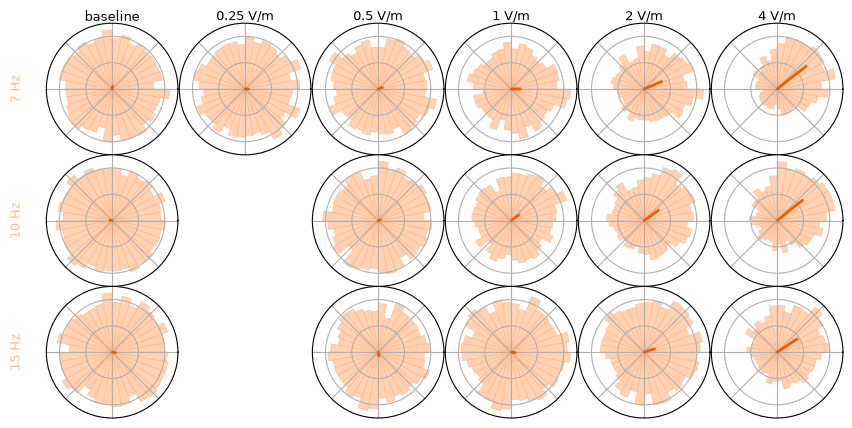

In [ ]:
plot_rose_grid(figS2.grids["PYR"], figS2.row_labels, AMP_LABELS, colors=peru, **ROSE_GRID_KWARGS
               ).savefig(FIG_DIR / "rose_grid_pyr.svg", dpi=600, bbox_inches="tight", pad_inches=0)

### Figure S2c: inhibitory interneurons

angle=-2.129 (-122.0°)
plv=0.029
angle=1.185 (67.9°)
plv=0.033
angle=1.175 (67.3°)
plv=0.012
angle=-2.367 (-135.6°)
plv=0.003
angle=1.531 (87.7°)
plv=0.030
angle=1.874 (107.4°)
plv=0.055
angle=1.009 (57.8°)
plv=0.022
angle=0.029 (1.7°)
plv=0.040
angle=-1.908 (-109.3°)
plv=0.032
angle=-2.677 (-153.4°)
plv=0.015
angle=-2.718 (-155.7°)
plv=0.012
angle=0.370 (21.2°)
plv=0.060
angle=-0.360 (-20.6°)
plv=0.030
angle=-0.738 (-42.3°)
plv=0.023
angle=-1.897 (-108.7°)
plv=0.026
angle=0.151 (8.7°)
plv=0.027


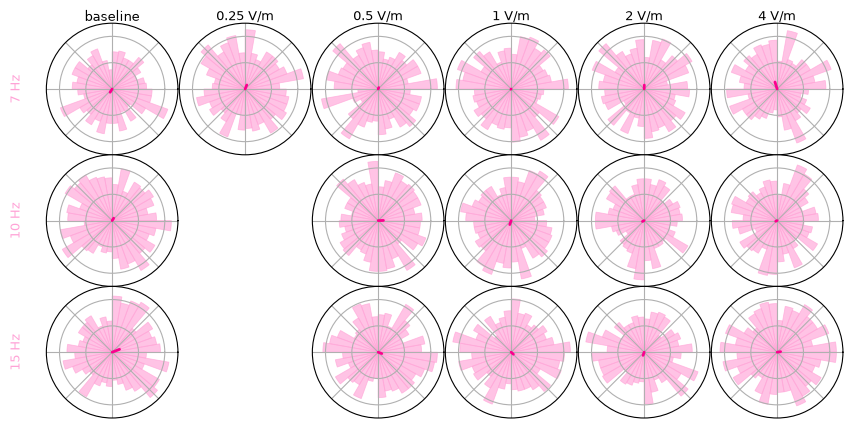

In [ ]:
plot_rose_grid(figS2.grids["INT_INH"], figS2.row_labels, AMP_LABELS, colors=pink, **ROSE_GRID_KWARGS
               ).savefig(FIG_DIR / "rose_grid_intinh.svg", dpi=600, bbox_inches="tight", pad_inches=0)

Inhibitory-cell subset of the Figure S2 tests

### Figure S2d: excitatory interneurons

angle=-2.736 (-156.8°)
plv=0.192
angle=2.352 (134.8°)
plv=0.193
angle=2.466 (141.3°)
plv=0.276
angle=2.702 (154.8°)
plv=0.232
angle=1.525 (87.4°)
plv=0.304
angle=1.601 (91.7°)
plv=0.235
angle=2.921 (167.4°)
plv=0.043
angle=-3.027 (-173.5°)
plv=0.062
angle=0.951 (54.5°)
plv=0.185
angle=0.836 (47.9°)
plv=0.326
angle=0.269 (15.4°)
plv=0.057
angle=0.961 (55.1°)
plv=0.108
angle=0.138 (7.9°)
plv=0.089
angle=1.707 (97.8°)
plv=0.159
angle=2.706 (155.0°)
plv=0.154
angle=2.473 (141.7°)
plv=0.070


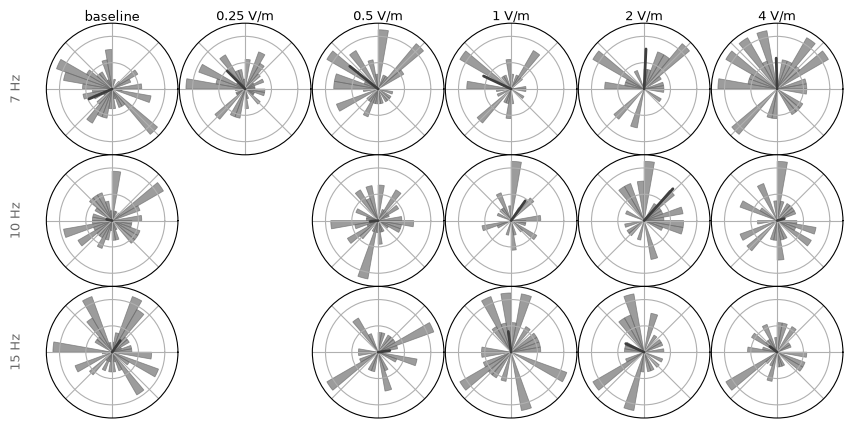

In [ ]:
plot_rose_grid(figS2.grids["INT_EXC"], figS2.row_labels, AMP_LABELS, colors=darkgrey, **ROSE_GRID_KWARGS
               ).savefig(FIG_DIR / "rose_grid_intexc.svg", dpi=600, bbox_inches="tight", pad_inches=0)

# Figure S3: phase preferences of individual neurons, high-correlation circuit

In [ ]:
assert "SETUP_DONE" in globals(), "Run the Setup section at the top of the notebook first."
figS3 = SimpleNamespace(
    freqs=FREQS["high"],
    runs=select_simulations(simulations, **SELECT["high"], freqs=FREQS["high"], amps=AMPS),
    baseline=sim_row(simulations, BASELINE_ID["high"]),
)
figS3.grids = {cell_type: cell_phase_grid(figS3.runs, figS3.baseline, figS3.freqs, AMPS, cell_type, min_spikes=MIN_SPIKES_PER_CELL)
               for cell_type in ("ALL", "PYR", "INT_INH", "INT_EXC")}
# Low-correlation data at the same frequencies for state comparisons.
figS3.low_runs = select_simulations(simulations, **SELECT["low"], freqs=FREQS["high"], amps=AMPS)
figS3.low_baseline = sim_row(simulations, BASELINE_ID["low"])
figS3.low_grids = {
    cell_type: cell_phase_grid(figS3.low_runs, figS3.low_baseline,
                          figS3.freqs, AMPS, cell_type, min_spikes=MIN_SPIKES_PER_CELL)
    for cell_type in ("ALL", "PYR", "INT_INH", "INT_EXC")
}
figS3.row_labels = [f"{freq} Hz" for freq in figS3.freqs]

### Figure S3a: all cells

angle=1.435 (82.2°)
plv=0.034
angle=0.913 (52.3°)
plv=0.053
angle=1.068 (61.2°)
plv=0.085
angle=1.408 (80.6°)
plv=0.155
angle=1.222 (70.0°)
plv=0.354
angle=2.344 (134.3°)
plv=0.018
angle=1.356 (77.7°)
plv=0.065
angle=1.139 (65.2°)
plv=0.084
angle=1.074 (61.5°)
plv=0.147
angle=1.278 (73.2°)
plv=0.269


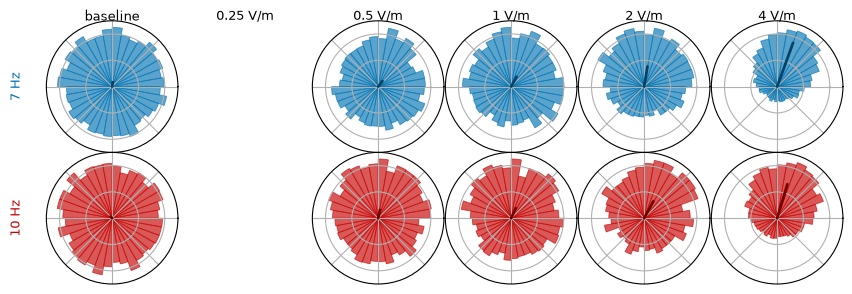

In [ ]:
plot_rose_grid(figS3.grids["ALL"], figS3.row_labels, AMP_LABELS, colors=[FREQ_COLORS["high"][f] for f in figS3.freqs], **ROSE_GRID_KWARGS
               ).savefig(FIG_DIR / "rose_grid_hc.svg", dpi=600, bbox_inches="tight", pad_inches=0)

Paired Moore tests: frequency-matched baseline vs each Figure S3 simulation

In [ ]:
# Column 0 is the same unstimulated network evaluated at each row's reference frequency.
# These paired Moore rows replace the former one-sample Kuiper tests for the rose distributions.
figS3.baseline_tests = pd.DataFrame([
    row
    for cell_type, grid in figS3.grids.items()
    if cell_type in ("ALL", "INT_INH")
    for freq, grid_row in zip(figS3.freqs, grid)
    for j, amp in enumerate(AMPS, start=1)
    if len(grid_row[0]) > 1 and len(grid_row[j]) > 1
    for row in cell_phase_contrasts(
        (condition(freq, 0, "high"), grid_row[0]),
        (condition(freq, amp, "high"), grid_row[j]),
        labels={"cell_type": cell_type}, **CELL_TEST_KWARGS,
    )
])

figS3.freq_pair_amp = [2,4]
figS3.freq_pairs = ((7, 10),)
figS3.freq_pair_cell_types = ("ALL",)   # add "PYR" / "INT_INH" / "INT_EXC" for cell-type versions

figS3.frequency_tests = pd.DataFrame([
    row
    for cell_type in figS3.freq_pair_cell_types
    for freq_a, freq_b in figS3.freq_pairs
    for amp in figS3.freq_pair_amp
    for phases in [{freq: grid_row[AMPS.index(amp) + 1]
                    for freq, grid_row in zip(figS3.freqs, figS3.grids[cell_type])}]
    if len(phases[freq_a]) > 1 and len(phases[freq_b]) > 1
    for row in cell_phase_contrasts(
        (condition(freq_a, amp, "high"), phases[freq_a]),
        (condition(freq_b, amp, "high"), phases[freq_b]),
        labels={"cell_type": cell_type}, **CELL_TEST_KWARGS,
    )
])
# Pyramidal vs inhibitory interneurons: do the two groups change their preferred phases differently?
figS3.cell_type_tests = pd.DataFrame([
    cell_type_contrast(figS3.grids, i, j, freq, amp, "high")
    for i, freq in enumerate(figS3.freqs)
    for j, amp in enumerate(AMPS, start=1)
    if all(len(figS3.grids[group][i][j]) > 1 for group in CELL_TYPE_PAIR)
])
figS3.baseline_tests.to_csv(FIG_DIR / "figS3_baseline_vs_stimulated_phase_tests.csv", index=False)
figS3.frequency_tests.to_csv(FIG_DIR / "figS3_frequency_tests.csv", index=False)
figS3.cell_type_tests.to_csv(FIG_DIR / "figS3_pyr_vs_intinh_phase_change_tests.csv", index=False)
display(figS3.baseline_tests)
display(figS3.frequency_tests)
display(figS3.cell_type_tests)

,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_cells_a,n_cells_b,kuiper_V,kuiper_p,moore_n_pairs,moore_n_moore,moore_R,moore_p_asymptotic,moore_mean_shift_deg,moore_p,moore_method
0,ALL,7,7,0,0.5,True,True,high,high,7442,5009,0.032875,3.580537e-02,4806,4806,0.558082,3.929490e-01,-85.946030,0.39205,randomization (19999 within-cell label swaps)
1,ALL,7,7,0,1.0,True,True,high,high,7442,5113,0.051492,5.979124e-06,4880,4880,1.517513,1.001339e-03,-88.507281,0.00075,randomization (19999 within-cell label swaps)
2,ALL,7,7,0,2.0,True,True,high,high,7442,5537,0.083314,9.860675e-18,5197,5197,3.612161,1.012195e-17,-89.095582,0.00005,randomization (19999 within-cell label swaps)
3,ALL,7,7,0,4.0,True,True,high,high,7442,9820,0.212439,2.622844e-164,6465,6465,9.844286,5.846568e-127,-86.644853,0.00005,randomization (19999 within-cell label swaps)
4,ALL,10,10,0,0.5,True,True,high,high,7442,4938,0.044311,3.632690e-04,4764,4764,1.202947,1.303816e-02,-90.593385,0.01365,randomization (19999 within-cell label swaps)
5,ALL,10,10,0,1.0,True,True,high,high,7442,5014,0.058227,1.067135e-07,4798,4798,2.051905,3.282212e-06,-95.201246,0.00005,randomization (19999 within-cell label swaps)
6,ALL,10,10,0,2.0,True,True,high,high,7442,5505,0.094675,3.795526e-23,5181,5181,3.921727,9.279566e-21,-99.184861,0.00005,randomization (19999 within-cell label swaps)
7,ALL,10,10,0,4.0,True,True,high,high,7442,7309,0.171537,1.590304e-92,5948,5948,7.890892,7.850410e-82,-97.992757,0.00005,randomization (19999 within-cell label swaps)
8,INT_INH,7,7,0,0.5,True,True,high,high,1469,1269,0.039867,7.612363e-01,1254,1254,0.184712,9.028192e-01,-91.581310,0.90185,randomization (19999 within-cell label swaps)
9,INT_INH,7,7,0,1.0,True,True,high,high,1469,1277,0.055660,2.083622e-01,1265,1265,0.567767,3.806285e-01,-96.228362,0.37805,randomization (19999 within-cell label swaps)


,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_cells_a,n_cells_b,kuiper_V,kuiper_p,moore_n_pairs,moore_n_moore,moore_R,moore_p_asymptotic,moore_mean_shift_deg,moore_p,moore_method
0,ALL,7,10,2,2,True,True,high,high,5537,5505,0.046528,2.763406e-04,4892,4892,1.261209,8.476282e-03,28.180580,0.00845,randomization (19999 within-cell label swaps)
1,ALL,7,10,4,4,True,True,high,high,9820,7309,0.064985,5.026972e-14,6972,6972,3.746036,5.258318e-19,17.773833,0.00005,randomization (19999 within-cell label swaps)


,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_pairs_a,R_base_a,R_stim_a,change_a,change_deg_a,n_pairs_b,R_base_b,R_stim_b,change_b,change_deg_b,change_difference,wald_chi2,wald_p
0,PYR vs INT_INH,7,7,0.5,0.5,True,True,high,high,3508,0.038523,0.061238,0.028634,12.346313,1254,0.021756,0.032908,0.016406,127.598869,0.012228,1.410861,4.938960e-01
1,PYR vs INT_INH,7,7,1.0,1.0,True,True,high,high,3571,0.037793,0.107834,0.072234,42.923171,1265,0.028330,0.060171,0.042772,140.228227,0.029463,7.392136,2.482093e-02
2,PYR vs INT_INH,7,7,2.0,2.0,True,True,high,high,3865,0.038049,0.185098,0.147356,69.798232,1283,0.022254,0.100348,0.085722,127.850368,0.061634,15.634201,4.027878e-04
3,PYR vs INT_INH,7,7,4.0,4.0,True,True,high,high,5032,0.034509,0.378877,0.346465,58.500635,1363,0.026268,0.186973,0.161240,87.699739,0.185225,53.699231,2.184541e-12
4,PYR vs INT_INH,10,10,0.5,0.5,True,True,high,high,3461,0.019937,0.067934,0.054003,60.365679,1261,0.053949,0.060805,0.025398,34.383841,0.028605,0.991714,6.090488e-01
5,PYR vs INT_INH,10,10,1.0,1.0,True,True,high,high,3503,0.023178,0.094970,0.093610,42.563836,1255,0.052920,0.079478,0.032343,78.934328,0.061267,4.459748,1.075420e-01
6,PYR vs INT_INH,10,10,2.0,2.0,True,True,high,high,3849,0.017885,0.178574,0.178846,51.607191,1283,0.056852,0.057965,0.028506,15.528101,0.150339,23.086210,9.702715e-06
7,PYR vs INT_INH,10,10,4.0,4.0,True,True,high,high,4553,0.016123,0.307821,0.311835,59.323484,1340,0.054585,0.140929,0.088096,100.831729,0.223739,64.790744,8.528421e-15


Two-sample Kuiper and paired Moore tests between high- and low-correlation circuits

In [ ]:
# Column 0 of every grid row is the baseline of that network at the same reference frequency.
figS3.state_tests = pd.DataFrame([
    row
    for cell_type in ["ALL", "INT_INH"]
    for freq, low_row, high_row in zip(figS3.freqs, figS3.low_grids[cell_type], figS3.grids[cell_type])
    for j, amp in enumerate(AMPS, start=1)
    if len(low_row[j]) > 1 and len(high_row[j]) > 1
    for row in cell_phase_contrasts(
        (condition(freq, amp, "low"), low_row[j]),
        (condition(freq, amp, "high"), high_row[j]),
        labels={"cell_type": cell_type}, **CELL_TEST_KWARGS,
    )
])

figS3.state_tests.to_csv(FIG_DIR / "figS3_low_vs_high_phase_tests.csv", index=False)
figS3.state_tests

,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_cells_a,n_cells_b,kuiper_V,kuiper_p,moore_n_pairs,moore_n_moore,moore_R,moore_p_asymptotic,moore_mean_shift_deg,moore_p,moore_method
0,ALL,7,7,0.5,0.5,True,True,low,high,5517,5009,0.039744,7.449063e-03,3632,3631,0.629210,3.050667e-01,-5.035434,0.30235,randomization (19999 within-cell label swaps)
1,ALL,7,7,1.0,1.0,True,True,low,high,4063,5113,0.054869,5.798069e-05,3145,3144,1.326329,5.118337e-03,-3.523250,0.00450,randomization (19999 within-cell label swaps)
2,ALL,7,7,2.0,2.0,True,True,low,high,4126,5537,0.088635,8.505896e-15,3308,3307,2.514456,5.838072e-09,-0.576982,0.00005,randomization (19999 within-cell label swaps)
3,ALL,7,7,4.0,4.0,True,True,low,high,4546,9820,0.138761,2.588341e-50,3988,3988,4.200214,1.055436e-23,2.312268,0.00005,randomization (19999 within-cell label swaps)
4,ALL,10,10,0.5,0.5,True,True,low,high,5980,4938,0.047104,2.637723e-04,3725,3724,1.222672,1.129978e-02,4.244960,0.01195,randomization (19999 within-cell label swaps)
5,ALL,10,10,1.0,1.0,True,True,low,high,4016,5014,0.038842,2.867971e-02,3128,3128,1.216566,1.181989e-02,-5.753466,0.01175,randomization (19999 within-cell label swaps)
6,ALL,10,10,2.0,2.0,True,True,low,high,4121,5505,0.051474,1.675490e-04,3266,3266,1.285650,7.038159e-03,4.254153,0.00710,randomization (19999 within-cell label swaps)
7,ALL,10,10,4.0,4.0,True,True,low,high,4426,7309,0.105250,5.026621e-25,3730,3729,2.503817,6.845028e-09,5.574507,0.00005,randomization (19999 within-cell label swaps)
8,INT_INH,7,7,0.5,0.5,True,True,low,high,869,1269,0.055427,4.360552e-01,806,806,0.506824,4.633928e-01,29.286812,0.46345,randomization (19999 within-cell label swaps)
9,INT_INH,7,7,1.0,1.0,True,True,low,high,764,1277,0.065232,2.335127e-01,732,732,0.708731,2.222805e-01,-80.714283,0.22650,randomization (19999 within-cell label swaps)


### Figure S3b: pyramidal

angle=1.434 (82.1°)
plv=0.036
angle=0.809 (46.3°)
plv=0.064
angle=0.906 (51.9°)
plv=0.104
angle=1.290 (73.9°)
plv=0.182
angle=1.191 (68.3°)
plv=0.378
angle=2.712 (155.4°)
plv=0.010
angle=1.252 (71.7°)
plv=0.065
angle=0.967 (55.4°)
plv=0.094
angle=1.017 (58.3°)
plv=0.179
angle=1.204 (69.0°)
plv=0.308


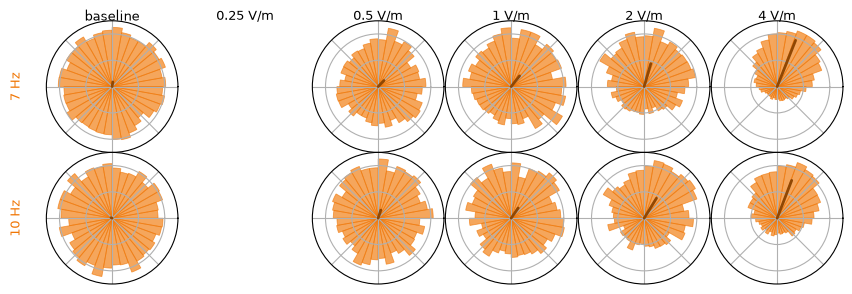

In [ ]:
plot_rose_grid(figS3.grids["PYR"], figS3.row_labels, AMP_LABELS, colors=lighterorange, **ROSE_GRID_KWARGS
               ).savefig(FIG_DIR / "rose_grid_hcPyr.svg", dpi=600, bbox_inches="tight", pad_inches=0)

### Figure S3c: inhibitory interneurons

angle=1.250 (71.6°)
plv=0.022
angle=1.701 (97.4°)
plv=0.033
angle=1.987 (113.8°)
plv=0.060
angle=2.092 (119.8°)
plv=0.105
angle=1.443 (82.7°)
plv=0.250
angle=2.107 (120.7°)
plv=0.062
angle=1.665 (95.4°)
plv=0.064
angle=1.797 (103.0°)
plv=0.081
angle=1.552 (88.9°)
plv=0.063
angle=1.890 (108.3°)
plv=0.163


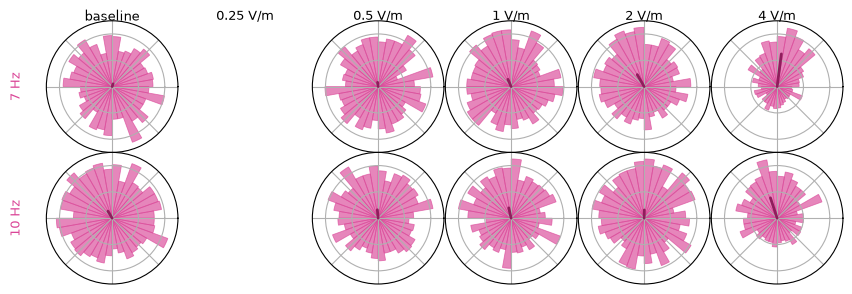

In [ ]:
plot_rose_grid(figS3.grids["INT_INH"], figS3.row_labels, AMP_LABELS, colors=lighterpink, **ROSE_GRID_KWARGS
               ).savefig(FIG_DIR / "rose_grid_hcInh.svg", dpi=600, bbox_inches="tight", pad_inches=0)

### Figure S3d: excitatory interneurons

angle=1.902 (109.0°)
plv=0.155
angle=-0.280 (-16.1°)
plv=0.115
angle=2.018 (115.6°)
plv=0.056
angle=-2.497 (-143.1°)
plv=0.060
angle=1.567 (89.8°)
plv=0.188
angle=-0.870 (-49.9°)
plv=0.115
angle=1.274 (73.0°)
plv=0.169
angle=-1.387 (-79.5°)
plv=0.147
angle=3.105 (177.9°)
plv=0.089
angle=-1.769 (-101.3°)
plv=0.143


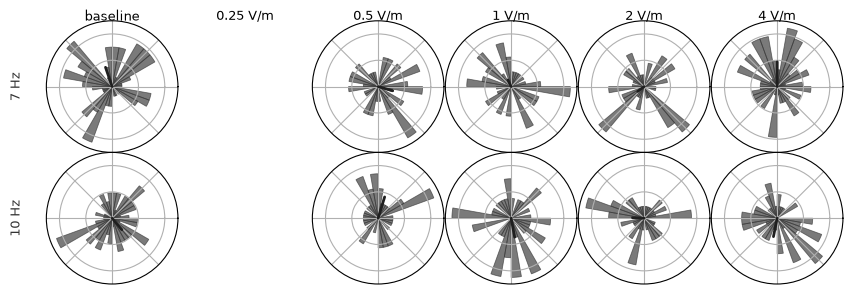

In [ ]:
plot_rose_grid(figS3.grids["INT_EXC"], figS3.row_labels, AMP_LABELS, colors=midgrey, **ROSE_GRID_KWARGS
               ).savefig(FIG_DIR / "rose_grid_hcIntExc.svg", dpi=600, bbox_inches="tight", pad_inches=0)

# Figure 5: replay (disconnected) vs connected network

In [ ]:
assert "SETUP_DONE" in globals(), "Run the Setup section at the top of the notebook first."
fig5 = SimpleNamespace(
    freq=10,
    amp=2,
    connectivity={"connected": True, "replay": False},
    rows={state: {"connected": sim_row(simulations, connected), "replay": sim_row(simulations, replay)}
          for state, (connected, replay) in {"low": ("10Hz2Vm", "replay_10Hz2Vm_invert"),
                                             "high": ("highCorrelation_10Hz2Vm", "replay_10Hz2Vm_highCorrelation")}.items()},
    colors={"low": red, "high": magenta},
    kinds=("connected", "replay"),
    cell_types=("ALL", "PYR", "INT_INH", "INT_EXC"),
)
fig5.phases = {
    state: {
        kind: {cell_type: cell_phases(fig5.rows[state][kind], fig5.freq, cell_type, min_spikes=MIN_SPIKES_PER_CELL)
               for cell_type in fig5.cell_types}
        for kind in fig5.kinds
    }
    for state in STATES
}
# Unstimulated connected network of each state. The disconnected (replay) network has no
# unstimulated run, so replay conditions are also compared with this connected baseline.
fig5.baselines = {state: sim_row(simulations, BASELINE_ID[state]) for state in STATES}
fig5.baseline_phases = {
    state: {cell_type: cell_phases(fig5.baselines[state], fig5.freq, cell_type, baseline=True,
                                   min_spikes=MIN_SPIKES_PER_CELL)
            for cell_type in fig5.cell_types}
    for state in STATES
}

### Figure 5a.i

In [ ]:
fig5.rows["low"]["connected"]

,sim_id,time_import,dt,tstop,seed,simulator,node_set,delay,duration,stim_freq,stim_phase,stim_amp,stim_orientation,stim_rampup,stim_rampdown,analysis_start,analysis_stop,source_file,plv,ppc,deltafr,complex,amplitude_norm,power_norm,total_power,plv_PYR,ppc_PYR,deltafr_PYR,complex_PYR,amplitude_norm_PYR,power_norm_PYR,total_power_PYR,plv_INT_INH,ppc_INT_INH,deltafr_INT_INH,complex_INT_INH,amplitude_norm_INT_INH,power_norm_INT_INH,total_power_INT_INH,plv_INT_EXC,ppc_INT_EXC,deltafr_INT_EXC,complex_INT_EXC,amplitude_norm_INT_EXC,power_norm_INT_EXC,total_power_INT_EXC,deployment,neurodamus,abs_plv,abs_plv_PYR,abs_plv_INT_INH,abs_plv_INT_EXC
38,10Hz2Vm,2026-05-13,0.025,2500,843,NEURON,hex0,1500,1000,10,1.570796,2.0,3.1416,0.0,0.0,1500.0,2500.0,data/sim10Hz2Vm_newNeurodamus/sim_with_stim.json,0.065563+0.049575j,0.006613,1.165349,2.708799-1.482101j,0.067277,0.004488,0.053114,0.087368+0.066461j,0.011864,1.2,3.169329-1.752896j,0.089839,0.007962,0.041186,-0.011519-0.010058j,-0.000401,1.073569,-0.955983+0.661584j,0.012552,0.000156,0.216788,0.220245+0.166598j,0.04987,0.765957,3.495500-1.852381j,0.227469,0.036499,0.010719,Mimas,wejji,0.082196,0.109774,0.015292,0.276157


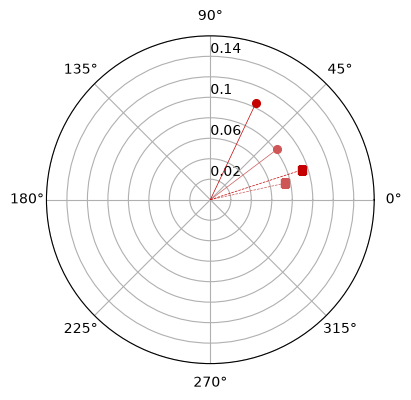

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4), subplot_kw={"projection": "polar"}, layout="constrained")
for state in STATES:
    polar_scatter(ax, fig5.rows[state]["connected"], None, fig5.colors[state], z_col="plv", line=True, rlim=(0, 0.15), rlabel_position=90)
    polar_scatter(ax, fig5.rows[state]["replay"], None, fig5.colors[state], z_col="plv", marker="s", linestyle="--", line=True, rlim=(0, 0.15), rlabel_position=90)
fig.savefig(FIG_DIR / "replayPolar.svg", dpi=300)

### Figure 5b.i and 5c.i

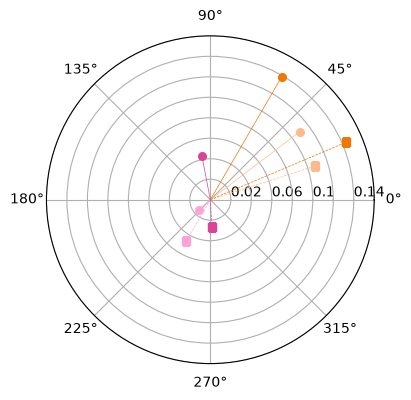

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4), subplot_kw={"projection": "polar"}, layout="constrained")
for state in STATES:
    polar_scatter(ax, fig5.rows[state]["connected"], None, CELL_COLORS[state]["PYR"],
                    z_col=f"plv_PYR", line=True, rlim = (0, 0.15))
    polar_scatter(ax, fig5.rows[state]["replay"], None, CELL_COLORS[state]["PYR"],
                    z_col=f"plv_PYR", marker="s", linestyle="--", line=True, rlim = (0, 0.15))
    polar_scatter(ax, fig5.rows[state]["connected"], None, CELL_COLORS[state]["INT_INH"],
                        z_col=f"plv_INT_INH", line=True)
    polar_scatter(ax, fig5.rows[state]["replay"], None, CELL_COLORS[state]["INT_INH"],
                        z_col=f"plv_INT_INH", marker="s", linestyle="--", line=True, rlabel_position=0)
fig.savefig(FIG_DIR / f"replayPolar_cellType{'PYR'.capitalize()}.svg", dpi=300)

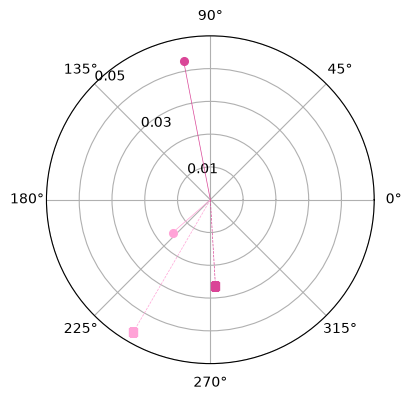

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4), subplot_kw={"projection": "polar"}, layout="constrained")
for state in STATES:
    polar_scatter(ax, fig5.rows[state]["connected"], None, CELL_COLORS[state]["INT_INH"],
                    z_col=f"plv_INT_INH", line=True, rlim = (0, 0.05))
    polar_scatter(ax, fig5.rows[state]["replay"], None, CELL_COLORS[state]["INT_INH"],
                    z_col=f"plv_INT_INH", marker="s", linestyle="--", line=True, rlim = (0, 0.05))
fig.savefig(FIG_DIR / f"replayPolar_cellType{'INT_INH'.capitalize()}.svg", dpi=300)

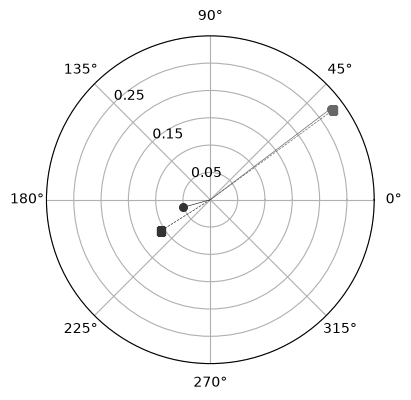

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4), subplot_kw={"projection": "polar"}, layout="constrained")
for state in STATES:
    polar_scatter(ax, fig5.rows[state]["connected"], None, CELL_COLORS[state]["INT_EXC"],
                    z_col=f"plv_INT_EXC", line=True, rlim = (0, 0.3))
    polar_scatter(ax, fig5.rows[state]["replay"], None, CELL_COLORS[state]["INT_EXC"],
                    z_col=f"plv_INT_EXC", marker="s", linestyle="--", line=True, rlim = (0, 0.3))
fig.savefig(FIG_DIR / f"replayPolar_cellType{'INT_EXC'.capitalize()}.svg", dpi=300)

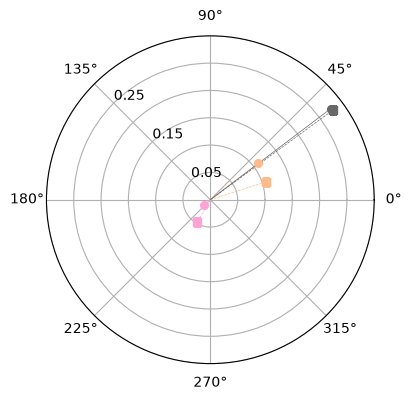

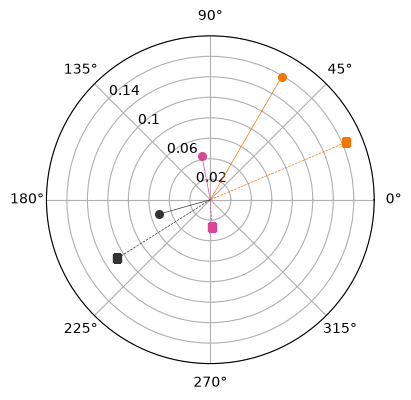

In [ ]:
limits = [(0, 0.3), (0, 0.16)]  # Example limits for each state, adjust as needed
for state, limit in zip(STATES, limits):
    fig, ax = plt.subplots(figsize=(4, 4), subplot_kw={"projection": "polar"}, layout="constrained")
    for cell_type in ("PYR", "INT_INH", "INT_EXC"):
        polar_scatter(ax, fig5.rows[state]["connected"], None, CELL_COLORS[state][cell_type],
                      z_col=f"plv_{cell_type}", line=True, rlim=limit, rlabel_position=135)
        polar_scatter(ax, fig5.rows[state]["replay"], None, CELL_COLORS[state][cell_type],
                      z_col=f"plv_{cell_type}", marker="s", linestyle="--", line=True, rlim=limit, rlabel_position=135)
    fig.savefig(FIG_DIR / f"replayPolar_cellType{state.capitalize()}.svg", dpi=300)

### Figure 5a.ii (rows: connected / replay; columns: low / high correlation)

angle=0.635 (36.4°)
plv=0.108
angle=1.074 (61.5°)
plv=0.147
angle=0.245 (14.1°)
plv=0.098
angle=0.292 (16.7°)
plv=0.136


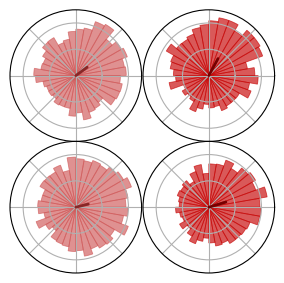

In [ ]:
plot_rose_grid([[fig5.phases[state][kind]["ALL"] for state in STATES] for kind in fig5.kinds],
               colors=[[fig5.colors[state] for state in STATES]] * 2, **ROSE_GRID_KWARGS
               ).savefig(FIG_DIR / "roseplotsReplay.svg", dpi=600)

### Figure 5b.ii and 5c.ii (rows: connected / replay; columns: PYR, INT_INH, INT_EXC)

In [ ]:
fig5.kinds

('connected', 'replay')

angle=0.626 (35.9°)
plv=0.134
angle=-2.677 (-153.4°)
plv=0.015
angle=0.836 (47.9°)
plv=0.326
angle=0.340 (19.5°)
plv=0.125
angle=-1.723 (-98.7°)
plv=0.060
angle=0.716 (41.0°)
plv=0.363
angle=1.017 (58.3°)
plv=0.179
angle=1.552 (88.9°)
plv=0.063
angle=3.105 (177.9°)
plv=0.089
angle=0.371 (21.2°)
plv=0.179
angle=-0.915 (-52.4°)
plv=0.043
angle=-2.083 (-119.4°)
plv=0.096


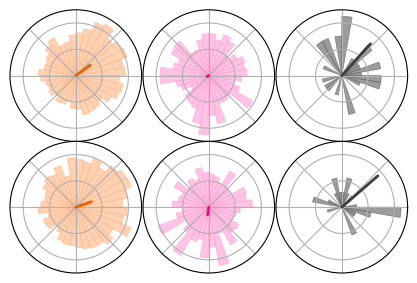

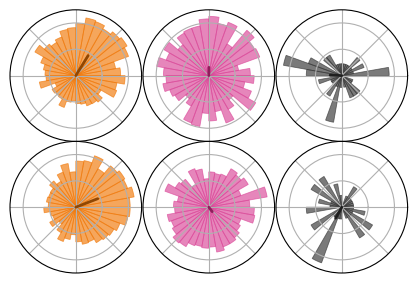

In [ ]:
for state in STATES:
    plot_rose_grid([[fig5.phases[state][kind][cell_type] for cell_type in ("PYR", "INT_INH", "INT_EXC")]
                    for kind in fig5.kinds],
                   colors=[[CELL_COLORS[state][ct] for ct in ("PYR", "INT_INH", "INT_EXC")]] * 2, **ROSE_GRID_KWARGS
                   ).savefig(FIG_DIR / f"roseplots_Replay{state.capitalize()}_CellTypes.svg", dpi=600)

Paired Moore tests for baseline effects, connectivity, and network state

In [ ]:
def fig5_side(state, kind, cell_type):
    """(condition, cells) of one Figure 5 sample."""
    return (condition(fig5.freq, fig5.amp, state, fig5.connectivity[kind]),
            fig5.phases[state][kind][cell_type])


def fig5_baseline(state, cell_type):
    """(condition, cells) of the connected, unstimulated network of one state."""
    return (condition(fig5.freq, 0, state, True), fig5.baseline_phases[state][cell_type])


# Connected stimulated runs already appear in the Figure S2/S3 baseline tables. Add the replay
# distributions here, paired with the connected unstimulated network of the same state.
fig5.baseline_tests = pd.DataFrame([
    row
    for state in STATES for cell_type in ("ALL", "INT_INH")
    if len(fig5.baseline_phases[state][cell_type]) > 1 and len(fig5.phases[state]["replay"][cell_type]) > 1
    for row in cell_phase_contrasts(
        fig5_baseline(state, cell_type), fig5_side(state, "replay", cell_type),
        labels={"cell_type": cell_type}, **CELL_TEST_KWARGS,
    )
])


fig5.connectivity_tests = pd.DataFrame([
    row
    for state in STATES for cell_type in ["ALL", "INT_INH"]
    if len(fig5.phases[state]["connected"][cell_type]) > 1 and len(fig5.phases[state]["replay"][cell_type]) > 1
    for row in cell_phase_contrasts(
        fig5_side(state, "connected", cell_type), fig5_side(state, "replay", cell_type),
        labels={"cell_type": cell_type}, **CELL_TEST_KWARGS,
    )
])
fig5.state_tests = pd.DataFrame([
    row
    for kind in fig5.kinds for cell_type in ["ALL", "INT_INH"]
    if len(fig5.phases["low"][kind][cell_type]) > 1 and len(fig5.phases["high"][kind][cell_type]) > 1
    for row in cell_phase_contrasts(
        fig5_side("low", kind, cell_type), fig5_side("high", kind, cell_type),
        labels={"cell_type": cell_type}, **CELL_TEST_KWARGS,
    )
])
fig5.baseline_tests.to_csv(FIG_DIR / "fig5_baseline_vs_replay_phase_tests.csv", index=False)
fig5.connectivity_tests.to_csv(FIG_DIR / "fig5_connected_vs_disconnected_phase_tests.csv", index=False)
fig5.state_tests.to_csv(FIG_DIR / "fig5_low_vs_high_phase_tests.csv", index=False)
display(fig5.baseline_tests)
display(fig5.connectivity_tests)
display(fig5.state_tests)

,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_cells_a,n_cells_b,kuiper_V,kuiper_p,moore_n_pairs,moore_n_moore,moore_R,moore_p_asymptotic,moore_mean_shift_deg,moore_p,moore_method
0,ALL,10,10,0,2,True,False,low,low,7079,3867,0.077133,1.160393e-11,3743,3743,2.670818,5.127465e-10,-89.460761,0.00005,randomization (19999 within-cell label swaps)
1,INT_INH,10,10,0,2,True,False,low,low,956,736,0.085581,4.659843e-02,730,730,1.116942,2.387317e-02,-87.164849,0.02345,randomization (19999 within-cell label swaps)
2,ALL,10,10,0,2,True,False,high,high,7442,5125,0.102373,4.143620e-26,4887,4887,4.071796,2.543536e-22,-91.258501,0.00005,randomization (19999 within-cell label swaps)
3,INT_INH,10,10,0,2,True,False,high,high,1469,1264,0.087035,1.180225e-03,1254,1254,1.501988,1.159438e-03,-85.330986,0.00120,randomization (19999 within-cell label swaps)


,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_cells_a,n_cells_b,kuiper_V,kuiper_p,moore_n_pairs,moore_n_moore,moore_R,moore_p_asymptotic,moore_mean_shift_deg,moore_p,moore_method
0,ALL,10,10,2,2,True,False,low,low,4121,3867,0.039722,4.118137e-02,3601,3100,0.841543,1.196056e-01,2.646998,0.11875,randomization (19999 within-cell label swaps)
1,INT_INH,10,10,2,2,True,False,low,low,766,736,0.074008,2.246907e-01,712,623,0.549073,4.056473e-01,3.201091,0.40495,randomization (19999 within-cell label swaps)
2,ALL,10,10,2,2,True,False,high,high,5505,5125,0.083824,7.444960e-15,4419,4380,2.732780,1.876224e-10,0.136234,0.00005,randomization (19999 within-cell label swaps)
3,INT_INH,10,10,2,2,True,False,high,high,1306,1264,0.090065,1.046866e-03,1206,1173,1.214528,1.203923e-02,3.159466,0.01155,randomization (19999 within-cell label swaps)


,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_cells_a,n_cells_b,kuiper_V,kuiper_p,moore_n_pairs,moore_n_moore,moore_R,moore_p_asymptotic,moore_mean_shift_deg,moore_p,moore_method
0,ALL,10,10,2,2,True,True,low,high,4121,5505,0.051474,0.000168,3266,3266,1.285650,0.007038,4.254153,0.00710,randomization (19999 within-cell label swaps)
1,INT_INH,10,10,2,2,True,True,low,high,766,1306,0.065240,0.226462,738,738,0.675424,0.255172,35.960390,0.25275,randomization (19999 within-cell label swaps)
2,ALL,10,10,2,2,False,False,low,high,3867,5125,0.036613,0.056834,3081,3081,1.050728,0.036499,-0.533949,0.03800,randomization (19999 within-cell label swaps)
3,INT_INH,10,10,2,2,False,False,low,high,736,1264,0.053333,0.596455,713,713,1.057033,0.035263,31.468959,0.03640,randomization (19999 within-cell label swaps)


### Connected vs disconnected: PPC and PLV, with paired-test significance

Bar height is the stored feature of that simulation. Brackets show Moore's paired test: connected vs replay within each state (`fig5.connectivity_tests`) and low vs high correlation for the connected and the replay runs (`fig5.state_tests`). When the *Statistical testing* section has been run, comparisons that belong to a test family show their corrected value: connected vs replay (family 3) and low vs high for the connected runs (family 2, 10 Hz, 2 V/m). Low vs high for the replay runs is not part of a family and is shown uncorrected, labelled as such.


### Figure S4: replay per layer, high correlation (rows: connected / replay; columns: L1, L2/3, L4, L5, L6)

angle=-0.621 (-35.6°)
plv=0.100
angle=0.756 (43.3°)
plv=0.109
angle=0.945 (54.2°)
plv=0.272
angle=1.501 (86.0°)
plv=0.138
angle=-0.873 (-50.0°)
plv=0.104
angle=0.352 (20.2°)
plv=0.135
angle=0.418 (24.0°)
plv=0.276
angle=0.411 (23.5°)
plv=0.091
angle=-1.191 (-68.2°)
plv=0.040
angle=-1.345 (-77.1°)
plv=0.022
angle=2.235 (128.0°)
plv=0.148
angle=1.349 (77.3°)
plv=0.064
angle=1.493 (85.5°)
plv=0.141
angle=-2.318 (-132.8°)
plv=0.098
angle=-1.280 (-73.3°)
plv=0.107
angle=-0.662 (-37.9°)
plv=0.047
angle=-2.381 (-136.4°)
plv=0.065
angle=0.409 (23.5°)
plv=0.134
angle=3.105 (177.9°)
plv=0.089
angle=-2.083 (-119.4°)
plv=0.096


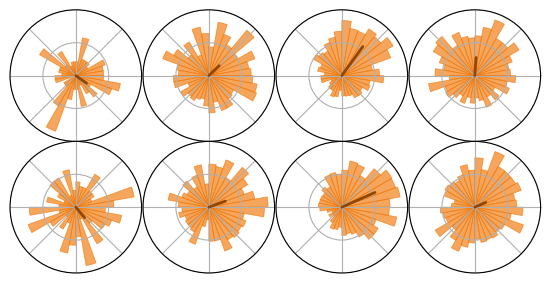

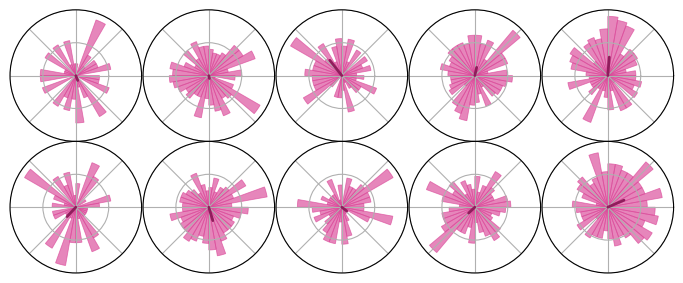

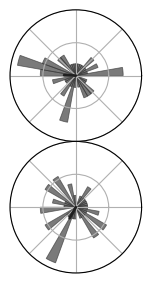

In [ ]:
fig5.layer_groups = ((1,), (2, 3), (4,), (5,), (6,))
fig5.layer_phases = {
    cell_type: {
        kind: {layers: cell_phases(fig5.rows["high"][kind], fig5.freq, cell_type, layers=layers,
                                    min_spikes=MIN_SPIKES_PER_CELL)
               for layers in fig5.layer_groups}
        for kind in fig5.kinds
    }
    for cell_type in ("PYR", "INT_INH", "INT_EXC")
}

for cell_type, tag in (("PYR", "Pyr"), ("INT_INH", "Inh"), ("INT_EXC", "Exc")):
    fig = plot_rose_grid(
        [[fig5.layer_phases[cell_type][kind][layers] for layers in fig5.layer_groups]
         for kind in fig5.kinds],
        colors=CELL_COLORS["high"][cell_type], normalize=ROSE_NORMALIZE, shared_scale=False, rticks=[0.25, 0.5], show_n=False,
    )
    # fig.legend(handles=[Patch(facecolor=color, edgecolor="none", label=CELL_LABELS[ct]) for ct, color in CELL_COLORS["high"].items()],
    #            loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=3, frameon=False, fontsize=8)
    fig.savefig(FIG_DIR / f"roseplots_ReplayHigh_layers{tag}.svg", dpi=600)



# Statistical testing of phase preferences

Run Figures S2, S3 and 5 first. Each family supports one conclusion and controls its own familywise error rate at `ALPHA`. The Moore families (1–3) are run separately for **all cells** (`PRIMARY_CELL_TYPE`, the population response, primary) and for **inhibitory interneurons in isolation** (secondary: at which stimulation paradigms they become entrained). See *Statistical methods* at the top for the procedures.

| Family | Comparison | Chains / tests | Procedure |
|---|---|---|---|
| 1 | Baseline vs stimulated (Fig. S2, S3) | one chain per state × frequency (5) | step down from 4 V/m at `ALPHA`/5; the lowest significant amplitude is the minimum effective amplitude |
| 2 | Low vs high correlation (Fig. S3) | one chain per frequency (2) | step down at `ALPHA`/2, only where family 1 found a baseline effect (`STATE_GATE`) |
| 3 | Connected vs disconnected (Fig. 5, 10 Hz, 2 V/m) | one test per state (2) | `CORRECTION_METHOD` |
| 4 | Pyramidal vs inhibitory interneurons (Fig. S2, S3) | one chain per state × frequency (5) | step down at `ALPHA`/5, only where all cells show a baseline effect; two-sample Wald test on per-cell phase changes |
| 5 | Different stimulation frequencies at the same amplitude and network state (all cells) | 12 low-state + 4 high-state comparisons | Holm–Bonferroni across all 16 comparisons, separately for Moore and Kuiper p-values |

Families 1–4 use the common result format in `phase_stats.dose`, `phase_stats.state`, `phase_stats.connectivity`, and `phase_stats.cell_type`. Family 5 collects the cross-frequency comparisons in `all_two_sample_tests` and `paper_table`.

### Family 1: baseline vs stimulated (all cells and inhibitory interneurons)

In [ ]:
missing = [name for name in ("figS2", "figS3", "fig5") if name not in globals()]
assert not missing, f"Run these sections first: {missing}"
phase_stats = SimpleNamespace()
P = MOORE_P_COLUMN


def family_results(tests, family, p_col, adjusted_col, correction, tested_col=None):
    """One test family in the common result format: p, tested, p_adjusted, significant, paper string."""
    tested = tests[tested_col].astype(bool) if tested_col else pd.Series(True, index=tests.index)
    result = tests.assign(family=family, correction=correction, p=tests[p_col], tested=tested,
                          p_adjusted=tests[adjusted_col].where(tested))
    result["significant"] = result["tested"] & result["p_adjusted"].le(ALPHA)
    result["p_adjusted_paper"] = result["p_adjusted"].map(paper_p_value).where(result["tested"], "not tested")
    return result


def family_summary(results, by="cell_type"):
    """Number of tests, tests reached and significant tests."""
    return results.groupby(by, sort=False).agg(tests=("p", "size"), tested=("tested", "sum"),
                                               significant=("significant", "sum"), correction=("correction", "first"))


def sort_by_chain(results, chain_cols):
    """Rows in testing order: chain by chain, highest amplitude first."""
    return results.sort_values([*chain_cols, "amp_b"], ascending=[True] * len(chain_cols) + [False])


# One family per cell type; one chain per network state x frequency, stepping down from the
# highest amplitude at ALPHA / n_chains.
dose_tests = pd.concat([figS2.baseline_tests, figS3.baseline_tests], ignore_index=True)
assert dose_tests["amp_a"].eq(0).all(), "Every row must have the baseline as sample A"
dose_tests = fixed_sequence_pvalues(dose_tests, [P], family_cols=["cell_type"], chain_cols=["correlation_b", "freq_b"],
                                    order_col="amp_b", alpha=ALPHA)
phase_stats.dose = family_results(
    dose_tests, "baseline vs stimulated", P, f"{P}_fixed_seq",
    correction="step-down over amplitude, ALPHA/" + dose_tests[f"{P}_n_chains"].astype(str),
    tested_col=f"{P}_tested",
)
display(family_summary(phase_stats.dose))
display(sort_by_chain(phase_stats.dose, ["cell_type", "correlation_b", "freq_b"])[[
    "cell_type", "correlation_b", "freq_b", "amp_b", "moore_n_pairs",
    "p", "moore_p_asymptotic", "tested", "p_adjusted", "significant", "p_adjusted_paper",
]].reset_index(drop=True))
phase_stats.dose.to_csv(FIG_DIR / "phase_tests_family1_baseline_vs_stimulated.csv", index=False)

,tests,tested,significant,correction
cell_type,,,,
ALL,21,18,13,"step-down over amplitude, ALPHA/5"
INT_INH,21,7,2,"step-down over amplitude, ALPHA/5"


,cell_type,correlation_b,freq_b,amp_b,moore_n_pairs,p,moore_p_asymptotic,tested,p_adjusted,significant,p_adjusted_paper
0,ALL,high,7,4.00,6465,0.00005,5.846568e-127,True,0.00025,True,< 0.0005
1,ALL,high,7,2.00,5197,0.00005,1.012195e-17,True,0.00025,True,< 0.0005
2,ALL,high,7,1.00,4880,0.00075,1.001339e-03,True,0.00375,True,< 0.005
3,ALL,high,7,0.50,4806,0.39205,3.929490e-01,True,1.00000,False,n.s.
4,ALL,high,10,4.00,5948,0.00005,7.850410e-82,True,0.00025,True,< 0.0005
5,ALL,high,10,2.00,5181,0.00005,9.279566e-21,True,0.00025,True,< 0.0005
6,ALL,high,10,1.00,4798,0.00005,3.282212e-06,True,0.00025,True,< 0.0005
7,ALL,high,10,0.50,4764,0.01365,1.303816e-02,True,0.06825,False,n.s.
8,ALL,low,7,4.00,4178,0.00005,7.971829e-42,True,0.00025,True,< 0.0005
9,ALL,low,7,2.00,3967,0.00005,8.350071e-11,True,0.00025,True,< 0.0005


In [ ]:
# Where does stimulation change the phase preference? Rows: cell group x network state x
# frequency; columns: amplitude, highest first. Corrected p in reporting form, "not tested" where the
# chain had already stopped, empty where the condition was not simulated. The INT_INH rows answer at
# which stimulation paradigms the inhibitory interneurons become entrained.
phase_stats.entrainment_map = (
    phase_stats.dose.pivot(index=["cell_type", "correlation_b", "freq_b"], columns="amp_b", values="p_adjusted_paper")
    .sort_index(axis=1, ascending=False)
    .fillna("")
)
phase_stats.min_effective_amp = minimum_effective_levels(
    phase_stats.dose, "significant", group_cols=["cell_type", "correlation_b", "freq_b"], order_col="amp_b",
)
phase_stats.entrainment_map.to_csv(FIG_DIR / "entrainment_map_family1.csv")
phase_stats.min_effective_amp.to_csv(FIG_DIR / "minimum_effective_amplitude_family1.csv", index=False)
display(phase_stats.entrainment_map)
display(phase_stats.min_effective_amp)

amp_b                               4.00        2.00        1.00        0.50  \
cell_type correlation_b freq_b                                                 
ALL       high          7       < 0.0005    < 0.0005     < 0.005        n.s.   
                        10      < 0.0005    < 0.0005    < 0.0005        n.s.   
          low           7       < 0.0005    < 0.0005      < 0.05        n.s.   
                        10      < 0.0005    < 0.0005      < 0.05        n.s.   
                        15      < 0.0005        n.s.  not tested  not tested   
INT_INH   high          7       < 0.0005        n.s.  not tested  not tested   
                        10        < 0.05        n.s.  not tested  not tested   
          low           7           n.s.  not tested  not tested  not tested   
                        10          n.s.  not tested  not tested  not tested   
                        15          n.s.  not tested  not tested  not tested   

amp_b                                 0.25  
cell_type correlation_b freq_b              
ALL       high          7                   
                        10                  
          low           7       not tested  
                        10                  
                        15                  
INT_INH   high          7                   
                        10                  
          low           7       not tested  
                        10                  
                        15

,cell_type,correlation_b,freq_b,min_effective_amp_b
0,ALL,low,7,1.0
1,ALL,low,10,1.0
2,ALL,low,15,4.0
3,INT_INH,low,7,NaN
4,INT_INH,low,10,NaN
5,INT_INH,low,15,NaN
6,ALL,high,7,1.0
7,ALL,high,10,1.0
8,INT_INH,high,7,4.0
9,INT_INH,high,10,4.0


### Family 2: low vs high correlation, where there is a stimulation effect

In [ ]:
# Low vs high correlation, one family per cell type. One chain per frequency, stepping down from
# the highest amplitude at ALPHA / n_chains. A step is tested only where family 1 (same cell group)
# found a stimulation effect at that frequency and amplitude in STATE_GATE ("any" or "all") of the
# two network states; the chain stops at the first step that fails the gate or is not significant.
assert STATE_GATE in ("any", "all"), STATE_GATE
baseline_effect = (
    phase_stats.dose.pivot(index=["cell_type", "freq_b", "amp_b"], columns="correlation_b", values="significant")
    .reindex(columns=list(STATES)).astype("boolean").fillna(False).astype(bool)
)
gate = baseline_effect.any(axis=1) if STATE_GATE == "any" else baseline_effect.all(axis=1)
baseline_effect = baseline_effect.add_prefix("baseline_effect_").assign(baseline_effect=gate).reset_index()
gate_columns = [column for column in baseline_effect.columns if column.startswith("baseline_effect")]

state_tests = figS3.state_tests.merge(baseline_effect, on=["cell_type", "freq_b", "amp_b"], how="left")
state_tests[gate_columns] = state_tests[gate_columns].astype("boolean").fillna(False).astype(bool)
state_tests = fixed_sequence_pvalues(state_tests, [P], family_cols=["cell_type"], chain_cols=["freq_b"],
                                     order_col="amp_b", alpha=ALPHA, gate="baseline_effect")
phase_stats.state = family_results(
    state_tests, "low vs high correlation", P, f"{P}_fixed_seq",
    correction=f"step-down over amplitude, gated by a baseline effect in {STATE_GATE} state(s), ALPHA/"
               + state_tests[f"{P}_n_chains"].astype(str),
    tested_col=f"{P}_tested",
)
display(family_summary(phase_stats.state))
display(sort_by_chain(phase_stats.state, ["cell_type", "freq_b"])[[
    "cell_type", "freq_b", "amp_b", *gate_columns, "moore_n_pairs", "moore_mean_shift_deg",
    "p", "tested", "p_adjusted", "significant", "p_adjusted_paper",
]].reset_index(drop=True))
phase_stats.state.to_csv(FIG_DIR / "phase_tests_family2_low_vs_high.csv", index=False)

,tests,tested,significant,correction
cell_type,,,,
ALL,8,6,6,"step-down over amplitude, gated by a baseline ..."
INT_INH,8,2,2,"step-down over amplitude, gated by a baseline ..."


,cell_type,freq_b,amp_b,baseline_effect_low,baseline_effect_high,baseline_effect,moore_n_pairs,moore_mean_shift_deg,p,tested,p_adjusted,significant,p_adjusted_paper
0,ALL,7,4.0,True,True,True,3988,2.312268,0.00005,True,0.0001,True,< 0.0005
1,ALL,7,2.0,True,True,True,3308,-0.576982,0.00005,True,0.0001,True,< 0.0005
2,ALL,7,1.0,True,True,True,3145,-3.523250,0.00450,True,0.0090,True,< 0.05
3,ALL,7,0.5,False,False,False,3632,-5.035434,0.30235,False,NaN,False,not tested
4,ALL,10,4.0,True,True,True,3730,5.574507,0.00005,True,0.0001,True,< 0.0005
5,ALL,10,2.0,True,True,True,3266,4.254153,0.00710,True,0.0142,True,< 0.05
6,ALL,10,1.0,True,True,True,3128,-5.753466,0.01175,True,0.0235,True,< 0.05
7,ALL,10,0.5,False,False,False,3725,4.244960,0.01195,False,NaN,False,not tested
8,INT_INH,7,4.0,False,True,True,778,13.953450,0.00005,True,0.0001,True,< 0.0005
9,INT_INH,7,2.0,False,False,False,738,-33.690830,0.09310,False,NaN,False,not tested


### Family 3: connected vs disconnected network

In [ ]:
# Connected vs disconnected (replay) network at 10 Hz, 2 V/m, one family per cell type: one test
# per network state, CORRECTION_METHOD over the two states.
connectivity_tests = pd.concat(
    [correct_pvalues(tests, [P], key_cols=TEST_KEY_COLUMNS, method=CORRECTION_METHOD)
     for _, tests in fig5.connectivity_tests.groupby("cell_type", sort=False)],
    ignore_index=True,
)
phase_stats.connectivity = family_results(
    connectivity_tests, "connected vs disconnected", P, f"{P}_{CORRECTION_METHOD}",
    correction=CORRECTION_METHOD + " over " + connectivity_tests[f"{P}_n_tests"].astype(str) + " network states",
)
display(family_summary(phase_stats.connectivity))
display(phase_stats.connectivity[[
    "cell_type", "correlation_a", "connectivity_a", "connectivity_b", "moore_n_pairs", "moore_mean_shift_deg",
    "p", "p_adjusted", "significant", "p_adjusted_paper",
]])
phase_stats.connectivity.to_csv(FIG_DIR / "phase_tests_family3_connected_vs_disconnected.csv", index=False)

,tests,tested,significant,correction
cell_type,,,,
ALL,2,2,1,holm over 2 network states
INT_INH,2,2,1,holm over 2 network states


,cell_type,correlation_a,connectivity_a,connectivity_b,moore_n_pairs,moore_mean_shift_deg,p,p_adjusted,significant,p_adjusted_paper
0,ALL,low,True,False,3601,2.646998,0.11875,0.11875,False,n.s.
1,ALL,high,True,False,4419,0.136234,0.00005,0.00010,True,< 0.0005
2,INT_INH,low,True,False,712,3.201091,0.40495,0.40495,False,n.s.
3,INT_INH,high,True,False,1206,3.159466,0.01155,0.02310,True,< 0.05


### Family 4: pyramidal cells vs inhibitory interneurons

In [ ]:
# Pyramidal vs inhibitory interneurons (CELL_TYPE_PAIR). One chain per network state x frequency,
# stepping down from the highest amplitude at ALPHA / n_chains. A step is tested only where the
# population (PRIMARY_CELL_TYPE, family 1) shows a stimulation effect at that state, frequency and
# amplitude.
population_effect = (
    phase_stats.dose.loc[phase_stats.dose["cell_type"] == PRIMARY_CELL_TYPE,
                         ["correlation_b", "freq_b", "amp_b", "significant"]]
    .rename(columns={"significant": "baseline_effect"})
)
cell_type_tests = (pd.concat([figS2.cell_type_tests, figS3.cell_type_tests], ignore_index=True)
                   .merge(population_effect, on=["correlation_b", "freq_b", "amp_b"], how="left"))
cell_type_tests["baseline_effect"] = cell_type_tests["baseline_effect"].astype("boolean").fillna(False).astype(bool)
cell_type_tests = fixed_sequence_pvalues(cell_type_tests, ["wald_p"], chain_cols=["correlation_b", "freq_b"],
                                         order_col="amp_b", alpha=ALPHA, gate="baseline_effect")
phase_stats.cell_type = family_results(
    cell_type_tests, "pyramidal vs inhibitory interneurons", "wald_p", "wald_p_fixed_seq",
    correction="step-down over amplitude, gated by a population baseline effect, ALPHA/"
               + cell_type_tests["wald_p_n_chains"].astype(str),
    tested_col="wald_p_tested",
)
display(family_summary(phase_stats.cell_type))
display(sort_by_chain(phase_stats.cell_type, ["correlation_b", "freq_b"])[[
    "correlation_b", "freq_b", "amp_b", "baseline_effect", "n_pairs_a", "n_pairs_b",
    "R_base_a", "R_stim_a", "R_base_b", "R_stim_b", "change_a", "change_b", "change_difference",
    "p", "tested", "p_adjusted", "significant", "p_adjusted_paper",
]].round(4).reset_index(drop=True))
phase_stats.cell_type.to_csv(FIG_DIR / "phase_tests_family4_pyr_vs_intinh.csv", index=False)

,tests,tested,significant,correction
cell_type,,,,
PYR vs INT_INH,21,12,9,"step-down over amplitude, gated by a populatio..."


,correlation_b,freq_b,amp_b,baseline_effect,n_pairs_a,n_pairs_b,R_base_a,R_stim_a,R_base_b,R_stim_b,change_a,change_b,change_difference,p,tested,p_adjusted,significant,p_adjusted_paper
0,high,7,4.00,True,5032,1363,0.0345,0.3789,0.0263,0.1870,0.3465,0.1612,0.1852,0.0000,True,0.0000,True,< 0.000005
1,high,7,2.00,True,3865,1283,0.0380,0.1851,0.0223,0.1003,0.1474,0.0857,0.0616,0.0004,True,0.0020,True,< 0.005
2,high,7,1.00,True,3571,1265,0.0378,0.1078,0.0283,0.0602,0.0722,0.0428,0.0295,0.0248,True,0.1241,False,n.s.
3,high,7,0.50,False,3508,1254,0.0385,0.0612,0.0218,0.0329,0.0286,0.0164,0.0122,0.4939,False,NaN,False,not tested
4,high,10,4.00,True,4553,1340,0.0161,0.3078,0.0546,0.1409,0.3118,0.0881,0.2237,0.0000,True,0.0000,True,< 0.000005
5,high,10,2.00,True,3849,1283,0.0179,0.1786,0.0569,0.0580,0.1788,0.0285,0.1503,0.0000,True,0.0000,True,< 0.00005
6,high,10,1.00,True,3503,1255,0.0232,0.0950,0.0529,0.0795,0.0936,0.0323,0.0613,0.1075,True,0.5377,False,n.s.
7,high,10,0.50,False,3461,1261,0.0199,0.0679,0.0539,0.0608,0.0540,0.0254,0.0286,0.6090,False,NaN,False,not tested
8,low,7,4.00,True,3383,770,0.0320,0.2682,0.0310,0.0454,0.2494,0.0721,0.1773,0.0000,True,0.0000,True,< 0.000005
9,low,7,2.00,True,3194,747,0.0349,0.1392,0.0319,0.0261,0.1256,0.0535,0.0721,0.0160,True,0.0802,False,n.s.


### Family 5: different stimulation frequencies at each amplitude

Compare **different stimulated simulations** at the same amplitude and within the same network state. Low correlation includes **7 vs 10, 10 vs 15, and 7 vs 15 Hz**; high correlation includes **7 vs 10 Hz**, because no 15 Hz stimulation run is available there. Amplitudes are **0.5, 1, 2, and 4 V/m**. The current tests use **all cells** (`freq_pair_cell_types = ("ALL",)`).

The cells' preferred phases come from the existing `figS2.grids` and `figS3.grids`. Each condition uses its own actual stimulation frequency, phase reference, and `delay < t < tstop` window; seeds are pooled per cell. Moore's paired test matches cell IDs across the two stimulation conditions. It asks whether those cells change their circular preferred-phase vectors between stimulation frequencies. It does not test equality of scalar PLV magnitudes or PSD values.

**Holm–Bonferroni:** the final correction cell combines the **12 low-correlation and 4 high-correlation comparisons** into one collection. With `CORRECTION_METHOD = "holm"`, correction is across all 16 comparisons, separately for `moore_p` and `kuiper_p`. It is not reset for each amplitude or state. Duplicate test keys are counted once. Moore uses the configured within-cell label-swap randomization; Kuiper is retained as a descriptive independent-sample comparison because the same cells occur in both conditions.

Run the Figure S2 and S3 grid-building sections before these cells and satisfy the prerequisites shown by the correction cell. Results are saved in `figS2_frequency_pair_phase_tests.csv`, `figS3_frequency_tests.csv`, `all_two_sample_cell_phase_tests_holm.csv`, and `paper_two_sample_cell_phase_tests_holm.csv` (suffix follows `CORRECTION_METHOD`). Cell-wise p-values depend on the pairing/exchangeability assumptions and describe this simulated network; they do not measure variation across independent network realizations.


In [ ]:
AMP_VALUES = [0.5,1,2,4]
figS3.freq_pairs = ((7, 10),)
figS3.freq_pair_cell_types = ("ALL",)   # add "PYR" / "INT_INH" / "INT_EXC" for cell-type versions

figS3.frequency_tests = pd.DataFrame([
    row
    for cell_type in figS3.freq_pair_cell_types
    for freq_a, freq_b in figS3.freq_pairs
    for amp in AMP_VALUES
    for phases in [{freq: grid_row[AMPS.index(amp) + 1]
                    for freq, grid_row in zip(figS3.freqs, figS3.grids[cell_type])}]
    if len(phases[freq_a]) > 1 and len(phases[freq_b]) > 1
    for row in cell_phase_contrasts(
        (condition(freq_a, amp, "high"), phases[freq_a]),
        (condition(freq_b, amp, "high"), phases[freq_b]),
        labels={"cell_type": cell_type}, **CELL_TEST_KWARGS,
    )
])

figS3.frequency_tests.to_csv(FIG_DIR / "figS3_frequency_tests.csv", index=False)
# figS3.baseline_stimulus_tests.to_csv(FIG_DIR / "figS3_baseline_vs_stimulated_phase_tests.csv", index=False)

display(figS3.frequency_tests)
# display(figS3.baseline_stimulus_tests)

,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_cells_a,n_cells_b,kuiper_V,kuiper_p,moore_n_pairs,moore_n_moore,moore_R,moore_p_asymptotic,moore_mean_shift_deg,moore_p,moore_method
0,ALL,7,10,0.5,0.5,True,True,high,high,5009,4938,0.031319,1.300910e-01,4500,4500,1.023291,4.326874e-02,116.773539,0.04340,randomization (19999 within-cell label swaps)
1,ALL,7,10,1.0,1.0,True,True,high,high,5113,5014,0.019440,8.443960e-01,4577,4577,0.280813,7.893936e-01,93.899522,0.78965,randomization (19999 within-cell label swaps)
2,ALL,7,10,2.0,2.0,True,True,high,high,5537,5505,0.046528,2.763406e-04,4892,4892,1.261209,8.476282e-03,28.180580,0.00845,randomization (19999 within-cell label swaps)
3,ALL,7,10,4.0,4.0,True,True,high,high,9820,7309,0.064985,5.026972e-14,6972,6972,3.746036,5.258318e-19,17.773833,0.00005,randomization (19999 within-cell label swaps)


In [ ]:

AMP_VALUES = [0.5,1,2,4]
figS2.freq_pairs = ((7, 10), (10, 15), (7, 15))
figS2.freq_pair_cell_types = ("ALL",)   # add "PYR" / "INT_INH" / "INT_EXC" for cell-type versions

figS2.frequency_tests = pd.DataFrame([
    row
    for cell_type in figS2.freq_pair_cell_types
    for freq_a, freq_b in figS2.freq_pairs
    for amp in AMP_VALUES
    for phases in [{freq: grid_row[AMPS.index(amp) + 1]
                    for freq, grid_row in zip(figS2.freqs, figS2.grids[cell_type])}]
    if len(phases[freq_a]) > 1 and len(phases[freq_b]) > 1
    for row in cell_phase_contrasts(
        (condition(freq_a, amp, "low"), phases[freq_a]),
        (condition(freq_b, amp, "low"), phases[freq_b]),
        labels={"cell_type": cell_type}, **CELL_TEST_KWARGS,
    )
])
figS2.frequency_tests.to_csv(FIG_DIR / "figS2_frequency_pair_phase_tests.csv", index=False)
display(figS2.frequency_tests)

# display(figS2.compairson_stimulus_tests)

,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_cells_a,n_cells_b,kuiper_V,kuiper_p,moore_n_pairs,moore_n_moore,moore_R,moore_p_asymptotic,moore_mean_shift_deg,moore_p,moore_method
0,ALL,7,10,0.5,0.5,True,True,low,low,5517,5980,0.025338,3.150603e-01,5302,5302,0.087088,0.977510,135.078530,0.97825,randomization (19999 within-cell label swaps)
1,ALL,7,10,1.0,1.0,True,True,low,low,4063,4016,0.038890,4.810612e-02,3809,3809,0.532816,0.426841,82.103297,0.42695,randomization (19999 within-cell label swaps)
2,ALL,7,10,2.0,2.0,True,True,low,low,4126,4121,0.028428,3.985034e-01,3793,3793,0.419716,0.589621,54.979115,0.59045,randomization (19999 within-cell label swaps)
3,ALL,7,10,4.0,4.0,True,True,low,low,4546,4426,0.031149,1.942159e-01,3968,3968,0.587831,0.354784,19.542677,0.35505,randomization (19999 within-cell label swaps)
4,ALL,10,15,0.5,0.5,True,True,low,low,5980,4011,0.030935,1.617546e-01,3925,3925,0.886000,0.094980,-75.407796,0.09065,randomization (19999 within-cell label swaps)
5,ALL,10,15,1.0,1.0,True,True,low,low,4016,4058,0.045427,7.167016e-03,3840,3840,0.625984,0.308786,-45.451217,0.30470,randomization (19999 within-cell label swaps)
6,ALL,10,15,2.0,2.0,True,True,low,low,4121,4048,0.042042,1.884589e-02,3775,3775,0.936922,0.071904,4.460059,0.07395,randomization (19999 within-cell label swaps)
7,ALL,10,15,4.0,4.0,True,True,low,low,4426,4327,0.045072,4.382331e-03,3944,3944,1.145055,0.019605,7.590589,0.02040,randomization (19999 within-cell label swaps)
8,ALL,7,15,0.5,0.5,True,True,low,low,5517,4011,0.036419,4.620528e-02,3905,3905,0.948534,0.067332,-146.717923,0.06595,randomization (19999 within-cell label swaps)
9,ALL,7,15,1.0,1.0,True,True,low,low,4063,4058,0.032541,2.016712e-01,3839,3839,0.551112,0.402196,-52.327140,0.40995,randomization (19999 within-cell label swaps)


In [ ]:
missing = [name for name in ("fig2", "figS2", "figS3", "fig5") if name not in globals()]
assert not missing, f"Run these sections first: {missing}"

# All two-sample tests (comparisons and baseline-vs-stimulated rows share one format). Kuiper and
# Moore are corrected as separate families; a test reported in several tables (same
# TEST_KEY_COLUMNS) is counted once.
two_sample_families = {
    # "fig2_hex0_vs_O1": fig2.circuit_tests,
    "figS2_frequency_pair": figS2.frequency_tests,
    "figS3_frequency_pair": figS3.frequency_tests,
    # "figS3_low_vs_high": figS3.state_tests,
    # "fig5_connected_vs_disconnected": fig5.connectivity_tests,
    # "fig5_low_vs_high": fig5.state_tests,
}
all_two_sample_tests = pd.concat(
    [tests.assign(comparison_family=name) for name, tests in two_sample_families.items()],
    ignore_index=True, sort=False,
)
missing_metadata = all_two_sample_tests.loc[:, COMPARISON_METADATA_COLUMNS].isna().any()
assert not missing_metadata.any(), f"Missing comparison metadata: {missing_metadata[missing_metadata].index.tolist()}"

# Moore: the randomization p-value. It cannot go below 1/(MOORE_PERMUTATIONS + 1), so the
# corrected value cannot go below n_tests/(MOORE_PERMUTATIONS + 1) (printed below).
P_COLUMNS = ("kuiper_p", "moore_p")
all_two_sample_tests = correct_pvalues(all_two_sample_tests, P_COLUMNS,
                                       key_cols=TEST_KEY_COLUMNS, method=CORRECTION_METHOD)
for p_col in P_COLUMNS:
    corrected = f"{p_col}_{CORRECTION_METHOD}"
    all_two_sample_tests[f"{corrected}_paper"] = all_two_sample_tests[corrected].map(paper_p_value)
    n_tests = all_two_sample_tests[f"{p_col}_n_tests"].iloc[0]
    print(f"{p_col}: {n_tests} unique tests, {CORRECTION_METHOD}-corrected p < 0.05 "
          f"(Bonferroni equivalent: raw p < {0.05 / n_tests:.3g})")
print(f"Smallest reachable Bonferroni-corrected moore_p: {min(1.0, n_tests / (MOORE_PERMUTATIONS + 1)):.3g} "
      f"(MOORE_PERMUTATIONS = {MOORE_PERMUTATIONS})")

all_two_sample_tests.to_csv(FIG_DIR / f"all_two_sample_cell_phase_tests_{CORRECTION_METHOD}.csv", index=False)
# display(all_two_sample_tests.groupby("comparison_family")[
#     ["kuiper_p_significant", "moore_p_significant"]].sum())

# Paper-ready table: one row per test, corrected p-values in reporting form.
paper_columns = [
    "comparison_family", *COMPARISON_METADATA_COLUMNS,
    "n_cells_a", "n_cells_b", "moore_n_pairs", "moore_mean_shift_deg",
    "kuiper_p", f"kuiper_p_{CORRECTION_METHOD}", f"kuiper_p_{CORRECTION_METHOD}_paper",
    "moore_p", f"moore_p_{CORRECTION_METHOD}", f"moore_p_{CORRECTION_METHOD}_paper", "moore_p_asymptotic",
]
paper_table = all_two_sample_tests[paper_columns].round({"moore_mean_shift_deg": 1})
paper_table.to_csv(FIG_DIR / f"paper_two_sample_cell_phase_tests_{CORRECTION_METHOD}.csv", index=False)
display(paper_table)

kuiper_p: 16 unique tests, holm-corrected p < 0.05 (Bonferroni equivalent: raw p < 0.00313)
moore_p: 16 unique tests, holm-corrected p < 0.05 (Bonferroni equivalent: raw p < 0.00313)
Smallest reachable Bonferroni-corrected moore_p: 0.0008 (MOORE_PERMUTATIONS = 19999)


,comparison_family,cell_type,freq_a,freq_b,amp_a,amp_b,connectivity_a,connectivity_b,correlation_a,correlation_b,n_cells_a,n_cells_b,moore_n_pairs,moore_mean_shift_deg,kuiper_p,kuiper_p_holm,kuiper_p_holm_paper,moore_p,moore_p_holm,moore_p_holm_paper,moore_p_asymptotic
0,figS2_frequency_pair,ALL,7,10,0.5,0.5,True,True,low,low,5517,5980,5302,135.1,3.150603e-01,9.710796e-01,n.s.,0.97825,1.00000,n.s.,9.775100e-01
1,figS2_frequency_pair,ALL,7,10,1.0,1.0,True,True,low,low,4063,4016,3809,82.1,4.810612e-02,4.158475e-01,n.s.,0.42695,1.00000,n.s.,4.268407e-01
2,figS2_frequency_pair,ALL,7,10,2.0,2.0,True,True,low,low,4126,4121,3793,55.0,3.985034e-01,9.710796e-01,n.s.,0.59045,1.00000,n.s.,5.896207e-01
3,figS2_frequency_pair,ALL,7,10,4.0,4.0,True,True,low,low,4546,4426,3968,19.5,1.942159e-01,9.710796e-01,n.s.,0.35505,1.00000,n.s.,3.547844e-01
4,figS2_frequency_pair,ALL,10,15,0.5,0.5,True,True,low,low,5980,4011,3925,-75.4,1.617546e-01,9.705274e-01,n.s.,0.09065,0.72520,n.s.,9.498006e-02
5,figS2_frequency_pair,ALL,10,15,1.0,1.0,True,True,low,low,4016,4058,3840,-45.5,7.167016e-03,7.883717e-02,n.s.,0.30470,1.00000,n.s.,3.087855e-01
6,figS2_frequency_pair,ALL,10,15,2.0,2.0,True,True,low,low,4121,4048,3775,4.5,1.884589e-02,1.884589e-01,n.s.,0.07395,0.66555,n.s.,7.190389e-02
7,figS2_frequency_pair,ALL,10,15,4.0,4.0,True,True,low,low,4426,4327,3944,7.6,4.382331e-03,5.258797e-02,n.s.,0.02040,0.24480,n.s.,1.960531e-02
8,figS2_frequency_pair,ALL,7,15,0.5,0.5,True,True,low,low,5517,4011,3905,-146.7,4.620528e-02,4.158475e-01,n.s.,0.06595,0.65950,n.s.,6.733226e-02
9,figS2_frequency_pair,ALL,7,15,1.0,1.0,True,True,low,low,4063,4058,3839,-52.3,2.016712e-01,9.710796e-01,n.s.,0.40995,1.00000,n.s.,4.021956e-01


## Definition of k and comparison families

This summary describes the tests and correction scopes implemented above with the current settings (`ALPHA = 0.05`, `MOORE_P_COLUMN = "moore_p"`, `CORRECTION_METHOD = "holm"`, `STATE_GATE = "any"`). A **comparison family** is the collection of hypotheses over which one multiple-testing procedure controls the familywise error rate. A figure, a displayed table, or a value of `comparison_family` is not necessarily a separate correction family.

### What does $k$ count?

For the fixed-sequence amplitude tests (families 1, 2 and 4), $k$ is the **number of distinct testing chains within one correction family**, not the number of cells, seeds, amplitudes, or rejected hypotheses. A chain fixes the state and frequency (families 1 and 4), or the frequency alone (family 2), and tests the available amplitudes in descending order: 4, 2, 1, 0.5, 0.25 V/m. A later step is reached only if all previous steps were significant and its gate, if any, passes.

Each reached step is tested at $\alpha/k$. At step $j$, the adjusted p-value is

$$p_{\mathrm{adj},j}=\min\!\left(1,\;k\max_{i\leq j}p_i\right).$$

The code records $k$ in `<p_column>_n_chains`. It counts the chains present in the input table **before gating or stopping**; a failed gate or an early non-significant result does not reduce $k$. Unreached steps are reported as `not tested`, not as evidence of no effect. If conditions are unavailable, the actual chains and amplitude steps are those represented in the input tables.

For Holm correction (families 3 and 5), use $m$ instead: the **number of unique individual comparisons** in the correction family, recorded in `<p_column>_n_tests`. For ordered raw p-values $p_{(1)}\leq\cdots\leq p_{(m)}$, Holm compares successive hypotheses with $\alpha/(m-i+1)$ and reports

$$p_{\mathrm{adj},(i)}=\min\!\left(1,\;\max_{j\leq i}(m-j+1)p_{(j)}\right).$$

Holm therefore does not use a constant $\alpha/m$ threshold at every step. If `CORRECTION_METHOD` is changed to `"bonferroni"`, the threshold is $\alpha/m$ for every comparison instead.

### Exact family membership

| Family | Hypotheses included together | Separate correction scopes | Multiplicity and procedure |
|---|---|---|---|
| **1. Baseline vs stimulation** | Paired Moore tests comparing each connected stimulated condition with its own state's unstimulated baseline, evaluated at the same reference frequency. Includes low correlation at 7, 10 and 15 Hz, and high correlation at 7 and 10 Hz, over available `AMPS`. | One family for `ALL` (primary population analysis) and a separate family for `INT_INH` (secondary inhibitory-cell analysis). States and frequencies are **not** corrected separately within either family. | $k=5$ state-frequency chains: (low, 7), (low, 10), (low, 15), (high, 7), (high, 10). Fixed sequence at $0.05/5=0.01$ per reached step. No gate. The lowest rejected amplitude in a chain is its minimum effective amplitude among the tested levels. |
| **2. Network state: low vs high correlation** | Paired Moore tests comparing low- and high-correlation connected networks at the same stimulation frequency and amplitude; only shared frequencies 7 and 10 Hz are included. | One family for `ALL` and a separate family for `INT_INH`. Both frequencies belong to the same family for each cell group. | $k=2$ frequency chains (7 and 10 Hz), fixed sequence at $0.05/2=0.025$. A step is eligible only if family 1 found a baseline effect for the **same cell group**, frequency and amplitude in at least one state (`STATE_GATE = "any"`; `"all"` would require both). A failed gate stops the chain. |
| **3. Replay: connected vs disconnected** | Paired Moore tests comparing the connected and replay networks at **10 Hz, 2 V/m**, separately in low and high correlation. | One family for `ALL` and a separate family for `INT_INH`; the two states are corrected together within each. | $m=2$ state comparisons per cell group, corrected by Holm with the current settings. No amplitude chain and no baseline-effect gate. |
| **4. Cell type: PYR vs INT_INH** | A two-sample Wald test comparing the mean baseline-to-stimulation **phase-change vectors** of pyramidal cells and inhibitory interneurons, at each available connected state-frequency-amplitude condition. Within each group, changes use cells active in both baseline and stimulation. | One family for this single cell-type contrast, pooling the five state-frequency chains. This is not a paired Moore test between cell types, because the two groups contain different cells. | $k=5$ state-frequency chains, as in family 1, fixed sequence at 0.01. Eligibility requires a family-1 baseline effect in `PRIMARY_CELL_TYPE = "ALL"` at that state, frequency and amplitude. A failed gate stops the chain. |
| **5. Stimulation frequency** | Same-state, same-amplitude comparisons between different stimulated runs. Low correlation: 7 vs 10, 10 vs 15, and 7 vs 15 Hz, each at 0.5, 1, 2 and 4 V/m (12 comparisons). High correlation: 7 vs 10 Hz at those four amplitudes (4 comparisons). Only `ALL` is currently included. | The final correction cell combines **both states, all frequency pairs and all four amplitudes**. It corrects `moore_p` and `kuiper_p` separately, not as one pool of 32 p-values. The `figS2_frequency_pair` and `figS3_frequency_pair` labels indicate table provenance, not separate Holm families. | $m=16$ unique comparisons for Moore and separately $m=16$ for Kuiper, provided all specified conditions are available. Holm correction; no amplitude chain or baseline-effect gate. Repeated `TEST_KEY_COLUMNS` count once. |

Families 1-3 thus each have two correction scopes (`ALL` and `INT_INH`); family 4 has one; family 5 has one for each of its two p-value columns. No correction is applied jointly across these scopes. Familywise control at 0.05 **within** a family is not notebook-wide control at 0.05 across all families, cell groups and tests.

### Replay and other comparisons outside these corrected families

- **Low vs high correlation during replay** (`fig5.state_tests`, disconnected rows) is computed but is not included in family 2 or the final Holm collection. It is an exploratory, uncorrected state comparison. The connected 10 Hz, 2 V/m state comparison also appears in this table, but its corrected inference comes from family 2 and its gate, not from an additional family.
- **Connected baseline vs stimulated replay** (`fig5.baseline_tests`) is computed for each state and for `ALL` and `INT_INH`, but is not included in family 1 or the final Holm collection. There is no unstimulated replay run: sample A is the connected baseline of the same state. These raw tests must not be described as corrected baseline-vs-replay evidence.
- **hex0 vs O1 and its baseline contrasts** (`fig2.circuit_tests`) are computed but their entry in `two_sample_families` is commented out, so they are not included in any of the five correction families above.
- Plotting `PYR`, `INT_EXC`, or layer-specific phase histograms does not itself create additional corrected test families. With the current configuration, families 1-3 test only `ALL` and `INT_INH`; family 4 tests only `PYR` vs `INT_INH`; family 5 tests only `ALL`.

**Interpretation and reporting.** Moore's paired tests use one preferred phase per matched active cell, with seeds pooled per cell, and 19,999 within-cell randomizations under the current configuration. Family 4 instead uses `wald_p`. Kuiper assumes independent samples, whereas these comparisons generally reuse cells: its results remain descriptive even though family 5 additionally reports adjusted Kuiper p-values. Kuiper p-values outside family 5 are not corrected by these procedures. Report the comparison family, cell group, correction method, $k$ or $m$, adjusted p-value, and whether a step was reached. These inferences describe cells in the simulated network, not uncertainty across independent network realizations.
